In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("imranzama444n/images-of-citrus-diseases")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/imranzama444n/images-of-citrus-diseases


In [2]:
from pathlib import Path

DATASET_PATH = Path(
    "/kaggle/input/datasets/imranzama444n/images-of-citrus-diseases/Lemon Leaf Dataset Images of Citrus Diseases and H/Lemon Leaf Dataset"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset path not found: {DATASET_PATH}")

class_counts = {}

# Count images recursively inside every immediate class folder
for class_folder in sorted(DATASET_PATH.iterdir()):

    if not class_folder.is_dir():
        continue

    image_count = sum(
        1
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    class_counts[class_folder.name] = image_count

print("Tomato dataset class distribution")
print("=" * 60)

for class_name, count in class_counts.items():
    print(f"{class_name:40s}: {count:5d} images")

print("-" * 60)
print(f"Number of classes : {len(class_counts)}")
print(f"Total images      : {sum(class_counts.values())}")

Tomato dataset class distribution
Anthracnose                             :   609 images
Citrus_Canker                           :   623 images
Citrus_Greening_Huanglongbing           :   618 images
Citrus_Leaf_Curl                        :   634 images
Citrus_Leafminer                        :   650 images
Healthy Lemon Leaf                      :   630 images
Swallowtail Larval Herbivory (Deficiency):   630 images
------------------------------------------------------------
Number of classes : 7
Total images      : 4394


In [3]:
import cv2
import shutil
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# =====================================================
# Configuration
# =====================================================

INPUT_DIR = Path(
    "/kaggle/input/datasets/imranzama444n/images-of-citrus-diseases/Lemon Leaf Dataset Images of Citrus Diseases and H/Lemon Leaf Dataset"
)

OUTPUT_DIR = Path(
    "/kaggle/working/papaya_leaf_preprocessed"
)

IMG_SIZE = 224

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Clear old output
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =====================================================
# Image functions
# =====================================================

def read_rgb(path):
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Cannot read image: {path}")

    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize_image(image):
    return cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )


def mild_denoise(image):
    """
    Removes mild image noise while preserving lesion edges.
    """
    return cv2.bilateralFilter(
        image,
        d=5,
        sigmaColor=20,
        sigmaSpace=20
    )


def apply_clahe(image):
    """
    Apply CLAHE only to luminance.
    This improves contrast without strongly changing leaf colors.
    """

    lab = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=1.5,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge([
        enhanced_l,
        a_channel,
        b_channel
    ])

    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )


def mild_unsharp_mask(image):
    """
    Restore important leaf veins, lesion borders,
    and disease texture after denoising.
    """

    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        sigmaX=1.0
    )

    sharpened = cv2.addWeighted(
        image,
        1.25,
        blurred,
        -0.25,
        0
    )

    return np.clip(
        sharpened,
        0,
        255
    ).astype(np.uint8)


def preprocess_leaf(image):
    image = resize_image(image)
    image = mild_denoise(image)
    image = apply_clahe(image)
    image = mild_unsharp_mask(image)

    return image


def save_rgb(path, image):
    path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    image_bgr = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2BGR
    )

    success = cv2.imwrite(
        str(path),
        image_bgr,
        [cv2.IMWRITE_PNG_COMPRESSION, 3]
    )

    if not success:
        raise ValueError(f"Cannot save image: {path}")


# =====================================================
# Process all classes
# =====================================================

records = []
errors = []

class_folders = sorted([
    folder for folder in INPUT_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    output_class_folder = (
        OUTPUT_DIR / class_folder.name
    )

    output_class_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    image_paths = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    for image_path in tqdm(
        image_paths,
        desc=class_folder.name
    ):
        try:
            original = read_rgb(image_path)
            processed = preprocess_leaf(original)

            output_path = (
                output_class_folder
                / f"{image_path.stem}.png"
            )

            save_rgb(
                output_path,
                processed
            )

            records.append({
                "class": class_folder.name,
                "input_path": image_path,
                "output_path": output_path
            })

        except Exception as error:
            errors.append({
                "path": str(image_path),
                "error": str(error)
            })


# =====================================================
# Print processed image counts
# =====================================================

print("\nPreprocessed tomato leaf image counts")
print("=" * 75)

overall_total = 0

for class_folder in class_folders:

    output_class_folder = (
        OUTPUT_DIR / class_folder.name
    )

    count = sum(
        1
        for path in output_class_folder.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    )

    overall_total += count

    print(
        f"{class_folder.name:50s}: "
        f"{count:5d} images"
    )

print("-" * 75)
print(f"Number of classes : {len(class_folders)}")
print(f"Total images      : {overall_total}")
print(f"Processing errors : {len(errors)}")
print(f"Saved directory   : {OUTPUT_DIR}")

Anthracnose:   0%|          | 0/609 [00:00<?, ?it/s]

Citrus_Canker:   0%|          | 0/623 [00:00<?, ?it/s]

Citrus_Greening_Huanglongbing:   0%|          | 0/618 [00:00<?, ?it/s]

Citrus_Leaf_Curl:   0%|          | 0/634 [00:00<?, ?it/s]

Citrus_Leafminer:   0%|          | 0/650 [00:00<?, ?it/s]

Healthy Lemon Leaf:   0%|          | 0/630 [00:00<?, ?it/s]

Swallowtail Larval Herbivory (Deficiency):   0%|          | 0/630 [00:00<?, ?it/s]


Preprocessed tomato leaf image counts
Anthracnose                                       :   609 images
Citrus_Canker                                     :   623 images
Citrus_Greening_Huanglongbing                     :   618 images
Citrus_Leaf_Curl                                  :   634 images
Citrus_Leafminer                                  :   650 images
Healthy Lemon Leaf                                :   630 images
Swallowtail Larval Herbivory (Deficiency)         :   630 images
---------------------------------------------------------------------------
Number of classes : 7
Total images      : 4394
Processing errors : 0
Saved directory   : /kaggle/working/papaya_leaf_preprocessed


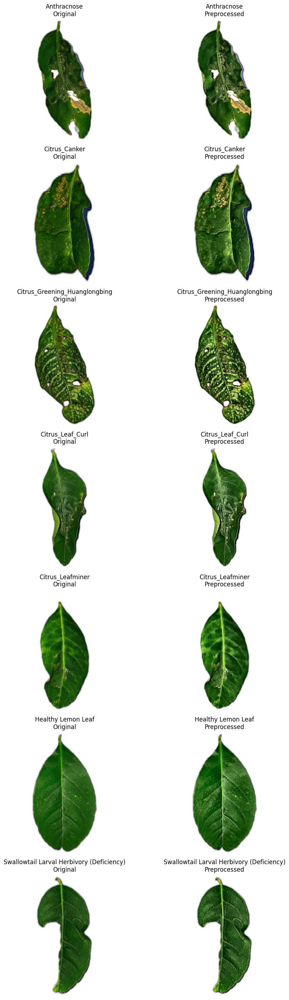

In [4]:
import random

random.seed(42)

samples_per_class = 1
selected_records = []

for class_folder in class_folders:

    class_records = [
        record
        for record in records
        if record["class"] == class_folder.name
    ]

    if class_records:
        selected_records.extend(
            random.sample(
                class_records,
                min(samples_per_class, len(class_records))
            )
        )

fig, axes = plt.subplots(
    len(selected_records),
    2,
    figsize=(10, 4 * len(selected_records))
)

if len(selected_records) == 1:
    axes = np.expand_dims(axes, axis=0)

for row, record in enumerate(selected_records):

    original = read_rgb(record["input_path"])
    original = resize_image(original)

    processed = read_rgb(record["output_path"])

    class_name = record["class"].replace(
        "Tomato___",
        ""
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"{class_name}\nOriginal"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(processed)
    axes[row, 1].set_title(
        f"{class_name}\nPreprocessed"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
import random
import shutil
from pathlib import Path

# =====================================================
# Configuration
# =====================================================

SEED = 42
random.seed(SEED)

SOURCE_DIR = Path(
    "/kaggle/working/papaya_leaf_preprocessed"
)

SPLIT_DIR = Path(
    "/kaggle/working/papaya_leaf_split"
)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Remove previous split directory
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# Split each class separately
# =====================================================

split_counts = {}

class_folders = sorted([
    folder
    for folder in SOURCE_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    images = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    random.shuffle(images)

    total = len(images)

    train_count = int(total * 0.80)
    validation_count = int(total * 0.10)

    train_images = images[:train_count]

    validation_images = images[
        train_count:
        train_count + validation_count
    ]

    test_images = images[
        train_count + validation_count:
    ]

    splits = {
        "train": train_images,
        "validation": validation_images,
        "test": test_images
    }

    for split_name, split_images in splits.items():

        output_folder = (
            SPLIT_DIR
            / split_name
            / class_folder.name
        )

        output_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        for image_path in split_images:
            shutil.copy2(
                image_path,
                output_folder / image_path.name
            )

        split_counts[
            (split_name, class_folder.name)
        ] = len(split_images)

print(f"Split dataset saved in:\n{SPLIT_DIR}")

Split dataset saved in:
/kaggle/working/papaya_leaf_split


In [6]:
import random
import shutil
from pathlib import Path

from PIL import Image
from tqdm.auto import tqdm
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# =====================================================
# Configuration
# =====================================================

SEED = 42
random.seed(SEED)

TRAIN_DIR = Path(
    "/kaggle/working/papaya_leaf_split/train"
)

AUGMENTED_DIR = Path(
    "/kaggle/working/papaya_leaf_train_augmented"
)

AUGMENTATIONS_PER_IMAGE = 2

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

# Remove previous augmented folder
if AUGMENTED_DIR.exists():
    shutil.rmtree(AUGMENTED_DIR)

AUGMENTED_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================
# Tomato-leaf-safe augmentation
# =====================================================

augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=25,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10),
        shear=5,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.RandomPerspective(
        distortion_scale=0.10,
        p=0.30,
        interpolation=InterpolationMode.BICUBIC,
        fill=255
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
        hue=0.02
    )
])

# =====================================================
# Original + two augmented images
# =====================================================

class_counts = {}

class_folders = sorted([
    folder
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

for class_folder in class_folders:

    output_folder = AUGMENTED_DIR / class_folder.name
    output_folder.mkdir(parents=True, exist_ok=True)

    image_paths = sorted([
        path
        for path in class_folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])

    original_count = 0
    augmented_count = 0
    error_count = 0

    for image_path in tqdm(
        image_paths,
        desc=class_folder.name
    ):
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")

                # Save original
                original_path = (
                    output_folder
                    / f"{image_path.stem}_original.png"
                )

                image.save(original_path)
                original_count += 1

                # Generate two augmented versions
                for aug_number in range(
                    1,
                    AUGMENTATIONS_PER_IMAGE + 1
                ):
                    augmented_image = augmentation(image)

                    augmented_path = (
                        output_folder
                        / f"{image_path.stem}_aug{aug_number}.png"
                    )

                    augmented_image.save(augmented_path)
                    augmented_count += 1

        except Exception as error:
            error_count += 1
            print(f"Skipped {image_path}: {error}")

    class_counts[class_folder.name] = {
        "original": original_count,
        "augmented": augmented_count,
        "total": original_count + augmented_count,
        "errors": error_count
    }

# =====================================================
# Print class-wise counts
# =====================================================

print("\nAugmented tomato training dataset")
print("=" * 100)

overall_original = 0
overall_augmented = 0
overall_total = 0
overall_errors = 0

for class_name, counts in class_counts.items():

    overall_original += counts["original"]
    overall_augmented += counts["augmented"]
    overall_total += counts["total"]
    overall_errors += counts["errors"]

    print(
        f"{class_name:55s} | "
        f"Original: {counts['original']:4d} | "
        f"Augmented: {counts['augmented']:4d} | "
        f"Total: {counts['total']:4d}"
    )

print("-" * 100)
print(f"Original training images : {overall_original}")
print(f"Generated augmentations  : {overall_augmented}")
print(f"Final training images     : {overall_total}")
print(f"Processing errors         : {overall_errors}")
print(f"Saved directory           : {AUGMENTED_DIR}")

Anthracnose:   0%|          | 0/487 [00:00<?, ?it/s]

Citrus_Canker:   0%|          | 0/498 [00:00<?, ?it/s]

Citrus_Greening_Huanglongbing:   0%|          | 0/494 [00:00<?, ?it/s]

Citrus_Leaf_Curl:   0%|          | 0/507 [00:00<?, ?it/s]

Citrus_Leafminer:   0%|          | 0/520 [00:00<?, ?it/s]

Healthy Lemon Leaf:   0%|          | 0/504 [00:00<?, ?it/s]

Swallowtail Larval Herbivory (Deficiency):   0%|          | 0/504 [00:00<?, ?it/s]


Augmented tomato training dataset
Anthracnose                                             | Original:  487 | Augmented:  974 | Total: 1461
Citrus_Canker                                           | Original:  498 | Augmented:  996 | Total: 1494
Citrus_Greening_Huanglongbing                           | Original:  494 | Augmented:  988 | Total: 1482
Citrus_Leaf_Curl                                        | Original:  507 | Augmented: 1014 | Total: 1521
Citrus_Leafminer                                        | Original:  520 | Augmented: 1040 | Total: 1560
Healthy Lemon Leaf                                      | Original:  504 | Augmented: 1008 | Total: 1512
Swallowtail Larval Herbivory (Deficiency)               | Original:  504 | Augmented: 1008 | Total: 1512
----------------------------------------------------------------------------------------------------
Original training images : 3514
Generated augmentations  : 7028
Final training images     : 10542
Processing errors         : 0
S

Device: cuda
Training path  : /kaggle/working/papaya_leaf_train_augmented
Validation path: /kaggle/working/papaya_leaf_split/validation
Testing path   : /kaggle/working/papaya_leaf_split/test
Output path    : /kaggle/working/lemon_msceca_swin_outputs
Patience       : 5
Plot directory : /kaggle/working/lemon_msceca_swin_outputs/plots
Table directory: /kaggle/working/lemon_msceca_swin_outputs/tables

Training validation passed
----------------------------------------------------------------------
Anthracnose                                            :  1461
Citrus_Canker                                          :  1494
Citrus_Greening_Huanglongbing                          :  1482
Citrus_Leaf_Curl                                       :  1521
Citrus_Leafminer                                       :  1560
Healthy Lemon Leaf                                     :  1512
Swallowtail Larval Herbivory (Deficiency)              :  1512
Total                                                  : 10

,Split,Anthracnose,Citrus_Canker,Citrus_Greening_Huanglongbing,Citrus_Leaf_Curl,Citrus_Leafminer,Healthy Lemon Leaf,Swallowtail Larval Herbivory (Deficiency),Total
0,Train,1461,1494,1482,1521,1560,1512,1512,10542
1,Validation,60,62,61,63,65,63,63,437
2,Test,62,63,63,64,65,63,63,443


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Loaded pretrained feature backbone: swin_tiny_patch4_window7_224.ms_in1k

Parameter summary


,Component,Total Parameters,Trainable Parameters,FP32 Parameter Memory (MB)
0,Swin-Tiny backbone,27517818,27517818,104.972145
1,Custom MSCECA-Swin modules,730152,730152,2.785309
2,Complete model,28247970,28247970,107.757454



Class weights


,Class,Training Images,Effective Weight
0,Anthracnose,1461,1.013095
1,Citrus Canker,1494,1.003261
2,Citrus Greening Huanglongbing,1482,1.006777
3,Citrus Leaf Curl,1521,0.995588
4,Citrus Leafminer,1560,0.985059
5,Healthy Lemon Leaf,1512,0.998110
6,Swallowtail Larval Herbivory (Deficiency),1512,0.998110



Training started
Epoch | Train Loss | Train Acc | Train Macro-F1 | Val Loss | Val Acc | Val Macro-F1 | Val BAcc | Backbone LR | Head LR
01    | 0.5831     | 0.6950    | 0.6951         | 1.0252   | 0.6568 | 0.6296       | 0.6608   | 0.0000100  | 0.0000667
02    | 0.2187     | 0.8723    | 0.8730         | 0.2464   | 0.8810 | 0.8806       | 0.8825   | 0.0000200  | 0.0001333
03    | 0.1403     | 0.9212    | 0.9217         | 0.1394   | 0.9153 | 0.9160       | 0.9163   | 0.0000300  | 0.0002000
04    | 0.0759     | 0.9608    | 0.9611         | 0.1372   | 0.9314 | 0.9315       | 0.9323   | 0.0000300  | 0.0002000
05    | 0.0486     | 0.9768    | 0.9769         | 0.1603   | 0.9451 | 0.9454       | 0.9458   | 0.0000299  | 0.0001993
06    | 0.0399     | 0.9820    | 0.9821         | 0.1797   | 0.9497 | 0.9499       | 0.9506   | 0.0000296  | 0.0001973
07    | 0.0314     | 0.9884    | 0.9885         | 0.2079   | 0.9451 | 0.9454       | 0.9461   | 0.0000291  | 0.0001940
08    | 0.0286     | 0.9888   

,Epoch,Train Loss,Train Accuracy,Train Macro F1,Train Balanced Accuracy,Validation Loss,Validation Accuracy,Validation Macro F1,Validation Balanced Accuracy,Backbone LR,Head LR
0,1,0.583100,0.695029,0.695138,0.695165,1.025166,0.656751,0.629586,0.660765,0.000010,0.000067
1,2,0.218716,0.872320,0.873012,0.872995,0.246438,0.881007,0.880593,0.882458,0.000020,0.000133
2,3,0.140256,0.921172,0.921721,0.921732,0.139385,0.915332,0.915966,0.916260,0.000030,0.000200
3,4,0.075939,0.960823,0.961103,0.961175,0.137190,0.931350,0.931497,0.932294,0.000030,0.000200
4,5,0.048646,0.976760,0.976898,0.976923,0.160314,0.945080,0.945369,0.945834,0.000030,0.000199
5,6,0.039876,0.981977,0.982073,0.982077,0.179740,0.949657,0.949866,0.950593,0.000030,0.000197
6,7,0.031406,0.988427,0.988486,0.988507,0.207859,0.945080,0.945422,0.946127,0.000029,0.000194
7,8,0.028594,0.988807,0.988848,0.988838,0.231624,0.947368,0.947837,0.948395,0.000028,0.000189
8,9,0.025691,0.989945,0.989995,0.990016,0.214771,0.954233,0.954633,0.955128,0.000028,0.000184
9,10,0.020978,0.991463,0.991493,0.991484,0.226504,0.947368,0.947641,0.948325,0.000026,0.000177


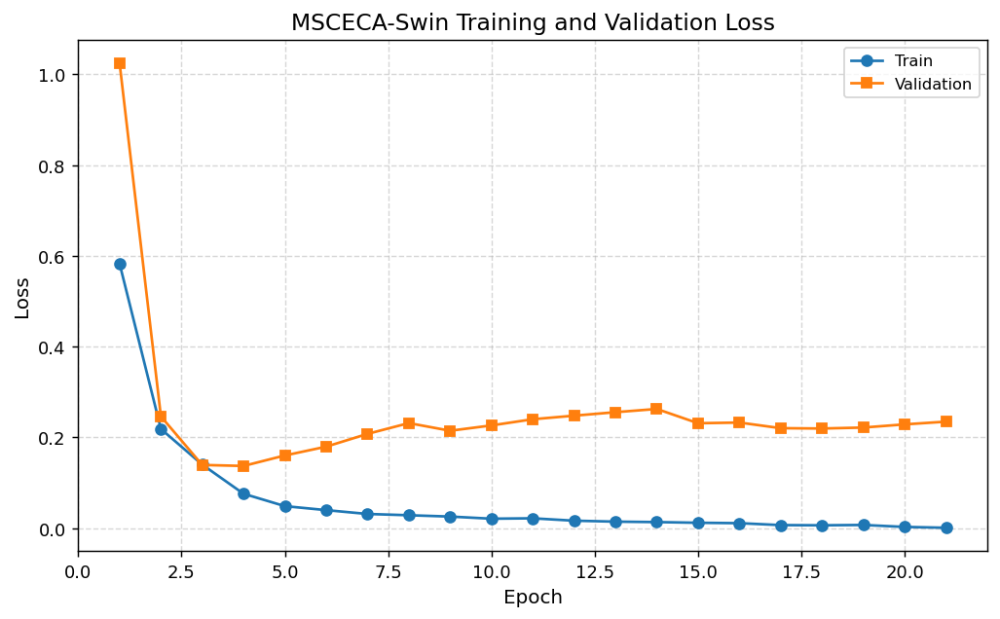

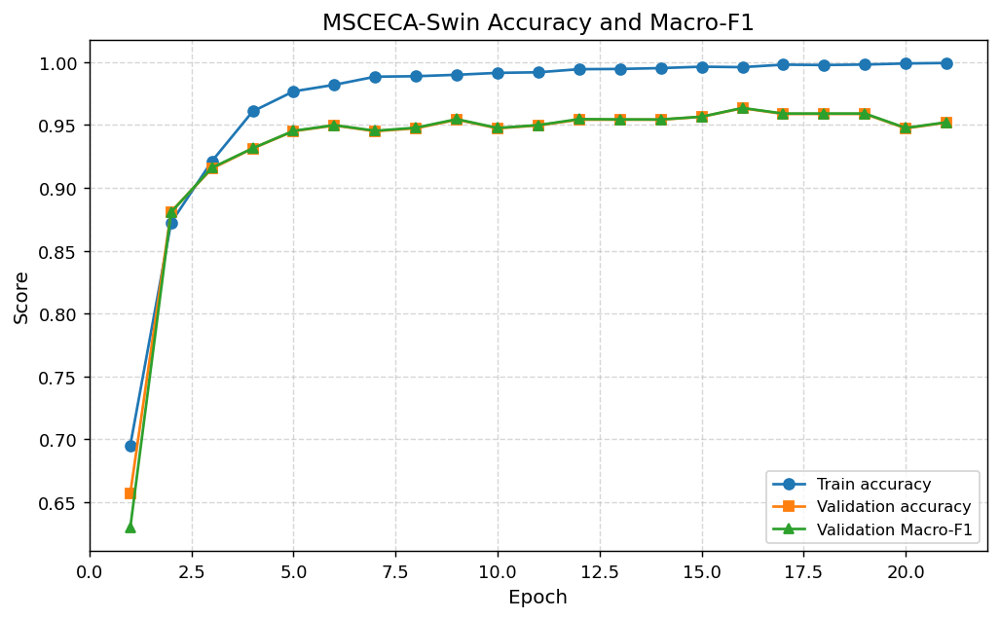

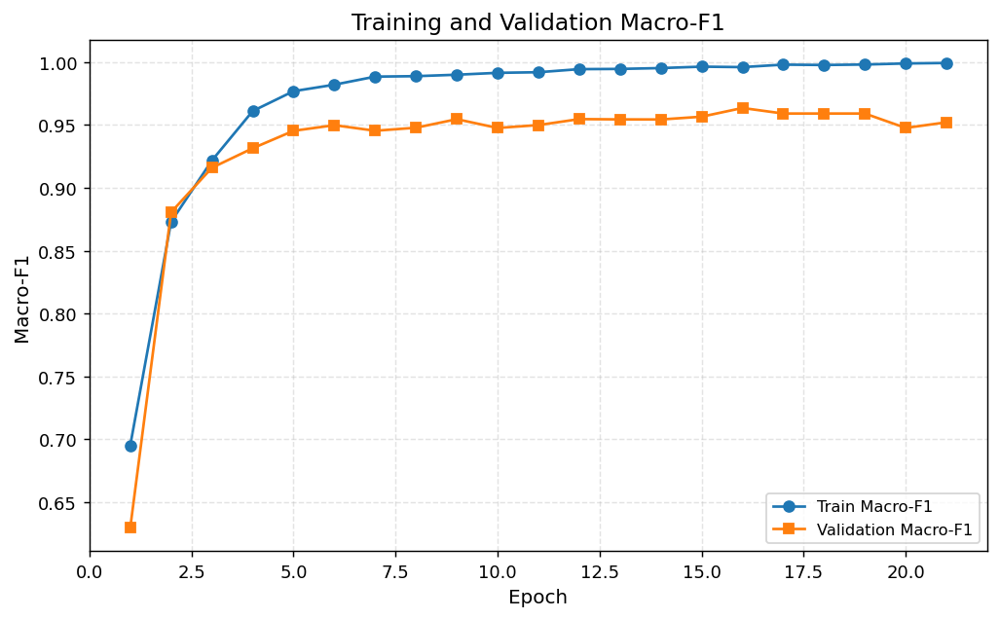

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/training_validation_macro_f1.png


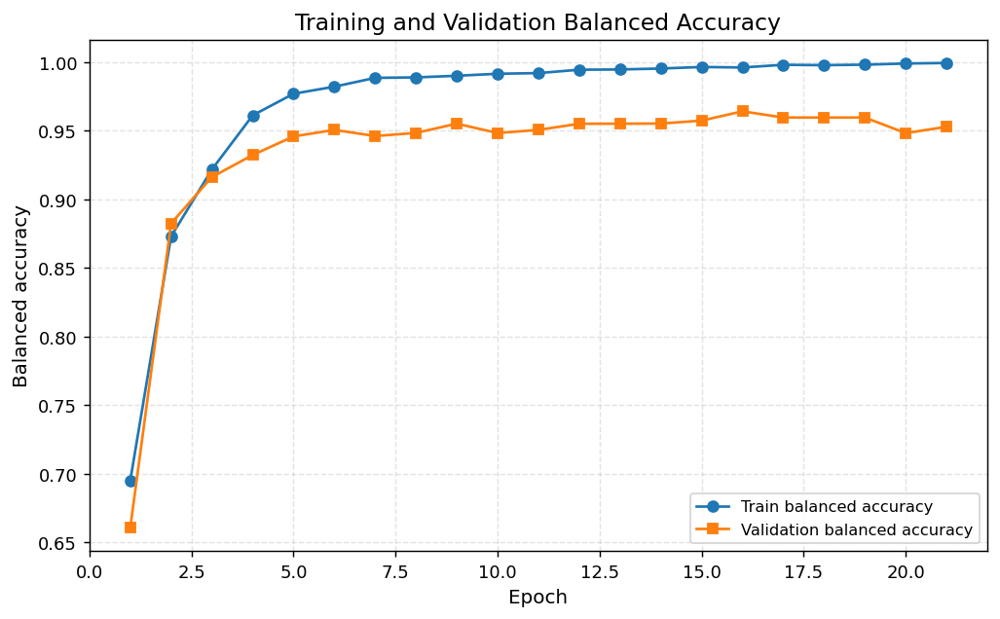

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/training_validation_balanced_accuracy.png


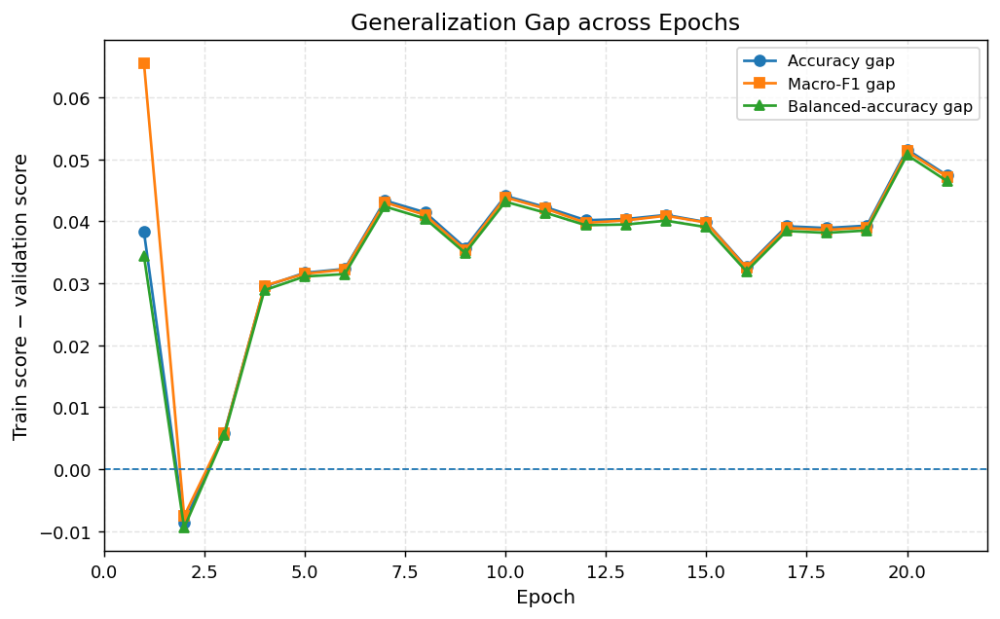

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/training_generalization_gaps.png


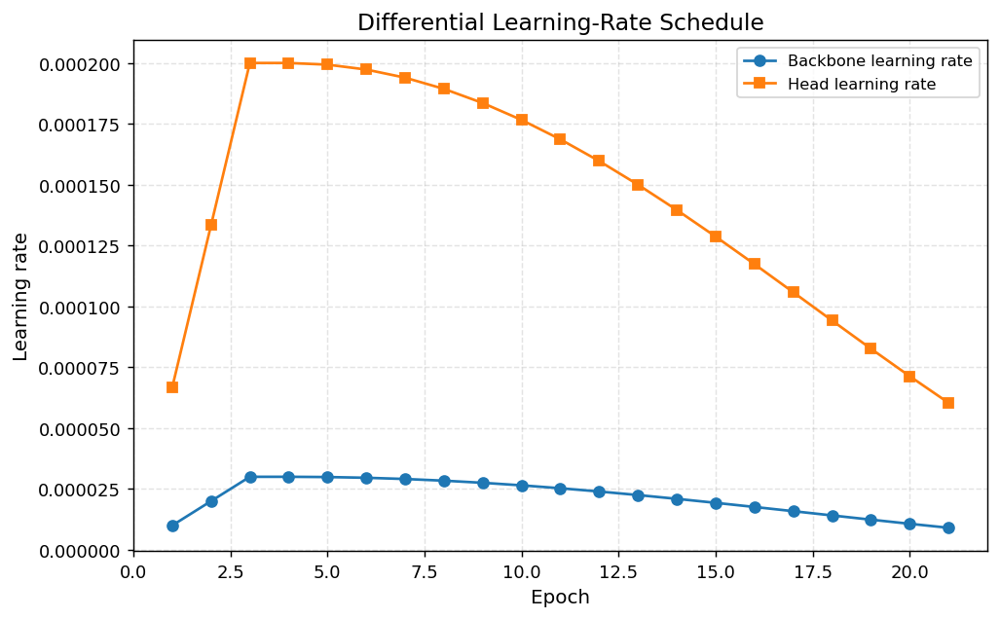

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/learning_rate_schedule.png

Training classification report
                                           precision    recall  f1-score   support

                              Anthracnose     1.0000    1.0000    1.0000      1461
                            Citrus Canker     1.0000    1.0000    1.0000      1494
            Citrus Greening Huanglongbing     1.0000    1.0000    1.0000      1482
                         Citrus Leaf Curl     1.0000    1.0000    1.0000      1521
                         Citrus Leafminer     1.0000    1.0000    1.0000      1560
                       Healthy Lemon Leaf     1.0000    1.0000    1.0000      1512
Swallowtail Larval Herbivory (Deficiency)     1.0000    1.0000    1.0000      1512

                                 accuracy                         1.0000     10542
                                macro avg     1.0000    1.0000    1.0000     10542
                             weighted avg     1.0

,Metric,Value
0,Accuracy,0.945824
1,Balanced Accuracy,0.946487
2,Precision Macro,0.948087
3,Precision Micro,0.945824
4,Precision Weighted,0.947598
5,Recall Macro,0.946487
6,Recall Micro,0.945824
7,Recall Weighted,0.945824
8,F1-score Macro,0.946359
9,F1-score Micro,0.945824



Per-class one-vs-rest metrics


,Class,Support,TP,TN,FP,FN,Sensitivity / Recall,Specificity,Precision / PPV,NPV,...,False Discovery Rate,False Omission Rate,Youden Index,LR+,LR-,Diagnostic Odds Ratio,ROC-AUC OvR,PR-AUC,Brier Score,Classwise ECE
0,Anthracnose,62,62,380,1,0,1.000000,0.997375,0.984127,1.000000,...,0.015873,0.000000,0.997375,381.000000,0.000000,inf,1.000000,1.000000,0.000498,0.001150
1,Citrus Canker,63,63,378,2,0,1.000000,0.994737,0.969231,1.000000,...,0.030769,0.000000,0.994737,190.000000,0.000000,inf,0.999958,0.999752,0.004269,0.005286
2,Citrus Greening Huanglongbing,63,59,377,3,4,0.936508,0.992105,0.951613,0.989501,...,0.048387,0.010499,0.928613,118.624339,0.063997,1853.583333,0.997097,0.982313,0.014586,0.015734
3,Citrus Leaf Curl,64,60,367,12,4,0.937500,0.968338,0.833333,0.989218,...,0.166667,0.010782,0.905838,29.609375,0.064544,458.750000,0.991878,0.938582,0.033314,0.034374
4,Citrus Leafminer,65,54,373,5,11,0.830769,0.986772,0.915254,0.971354,...,0.084746,0.028646,0.817542,62.806154,0.171499,366.218182,0.980260,0.938664,0.034290,0.036555
5,Healthy Lemon Leaf,63,63,380,0,0,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,1.000000,inf,0.000000,inf,1.000000,1.000000,0.000000,0.000079
6,Swallowtail Larval Herbivory (Deficiency),63,58,379,1,5,0.920635,0.997368,0.983051,0.986979,...,0.016949,0.013021,0.918003,349.841270,0.079574,4396.400000,0.996449,0.986728,0.013198,0.015278



TRAIN–VALIDATION–TEST METRIC COMPARISON

----------------------------------------------------------------------------------------------------
All Aggregate Metrics across Data Splits
----------------------------------------------------------------------------------------------------


,Metric,Training,Validation,Testing
0,Accuracy,1.000000,0.963387,0.945824
1,Balanced Accuracy,1.000000,0.964124,0.946487
2,Precision Macro,1.000000,0.964915,0.948087
3,Precision Micro,1.000000,0.963387,0.945824
4,Precision Weighted,1.000000,0.964763,0.947598
5,Recall Macro,1.000000,0.964124,0.946487
6,Recall Micro,1.000000,0.963387,0.945824
7,Recall Weighted,1.000000,0.963387,0.945824
8,F1-score Macro,1.000000,0.963549,0.946359
9,F1-score Micro,1.000000,0.963387,0.945824


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/train_validation_test_all_metrics.csv


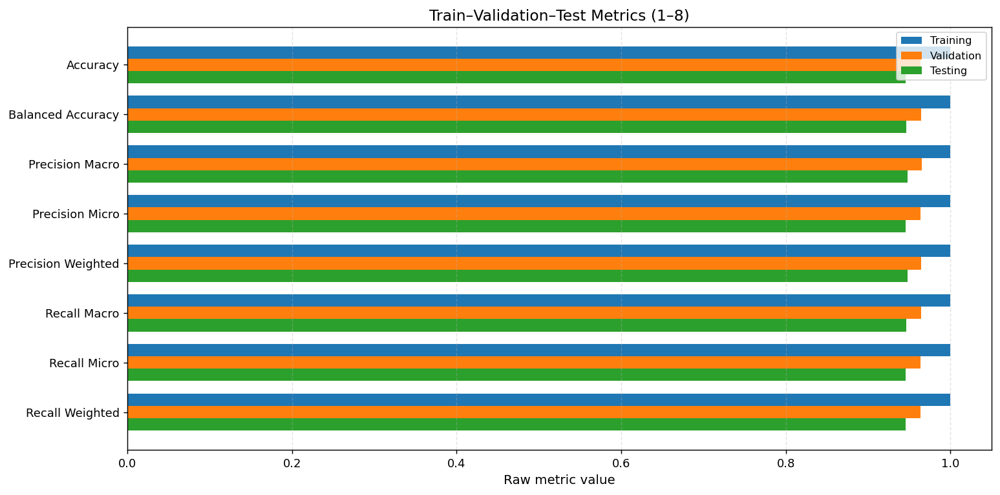

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_1_8.png


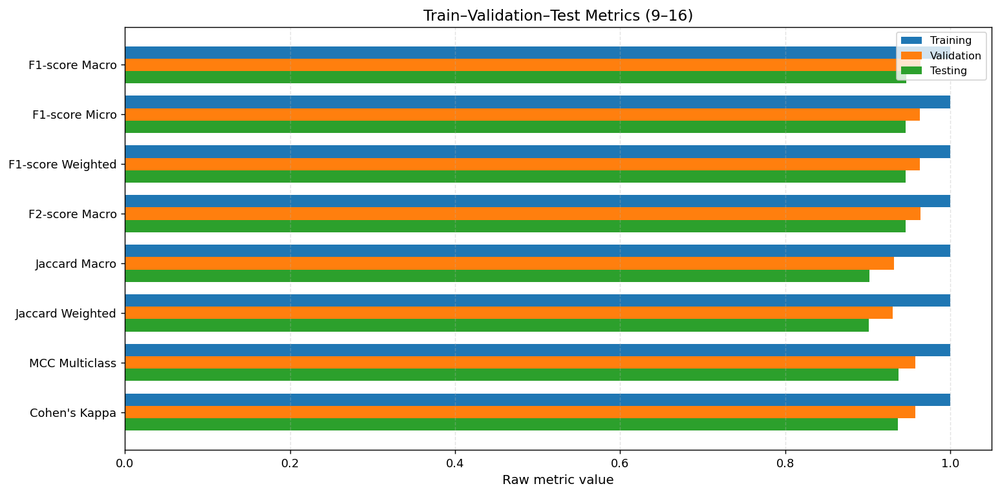

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_9_16.png


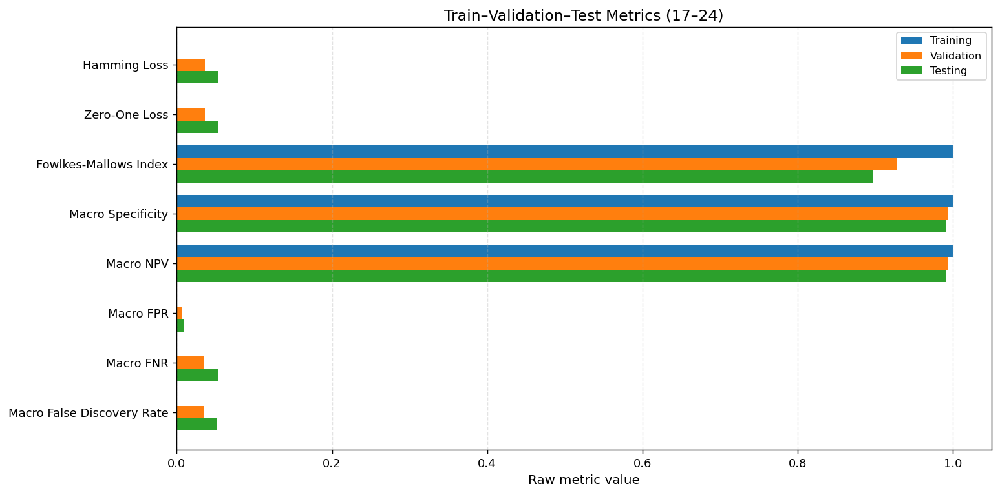

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_17_24.png


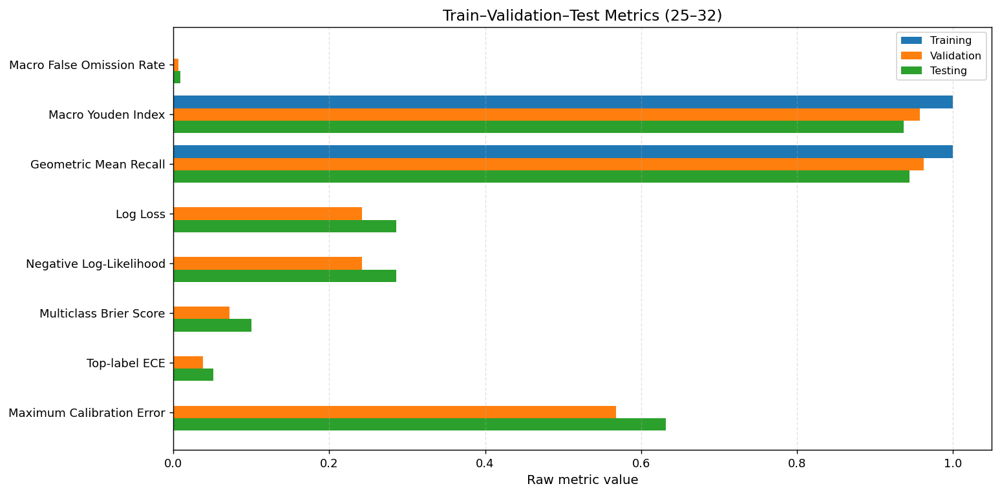

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_25_32.png


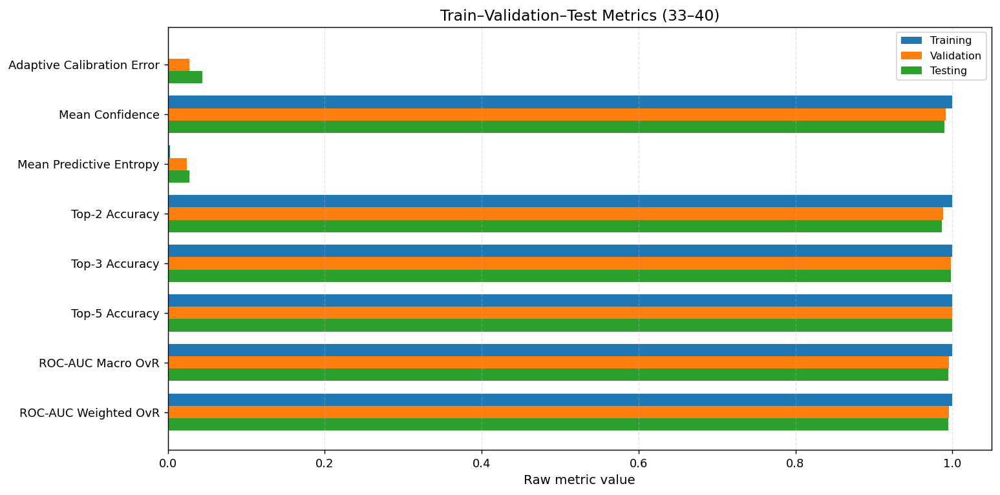

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_33_40.png


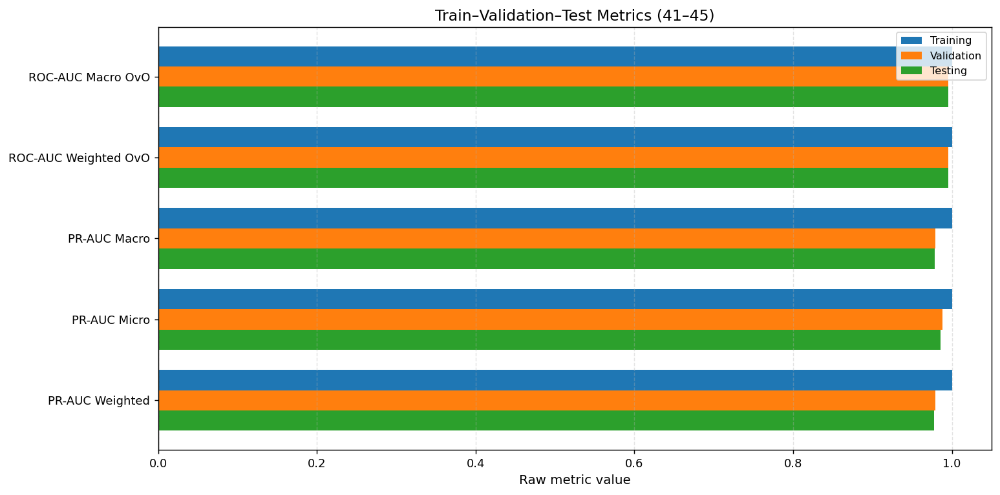

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/train_validation_test_metrics_41_45.png

COMPLETE TEST EVALUATION METRICS
Accuracy                                  : 0.945824
Balanced Accuracy                         : 0.946487
Precision Macro                           : 0.948087
Precision Micro                           : 0.945824
Precision Weighted                        : 0.947598
Recall Macro                              : 0.946487
Recall Micro                              : 0.945824
Recall Weighted                           : 0.945824
F1-score Macro                            : 0.946359
F1-score Micro                            : 0.945824
F1-score Weighted                         : 0.945771
F2-score Macro                            : 0.946210
Jaccard Macro                             : 0.902064
Jaccard Weighted                          : 0.901035
MCC Multiclass                            : 0.937134
Cohen's Kappa                             : 0.936794
Hamming Loss      

,Metric,Value
0,Accuracy,0.945824
1,Balanced Accuracy,0.946487
2,Precision Macro,0.948087
3,Precision Micro,0.945824
4,Precision Weighted,0.947598
5,Recall Macro,0.946487
6,Recall Micro,0.945824
7,Recall Weighted,0.945824
8,F1-score Macro,0.946359
9,F1-score Micro,0.945824


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/metric_group_1.csv


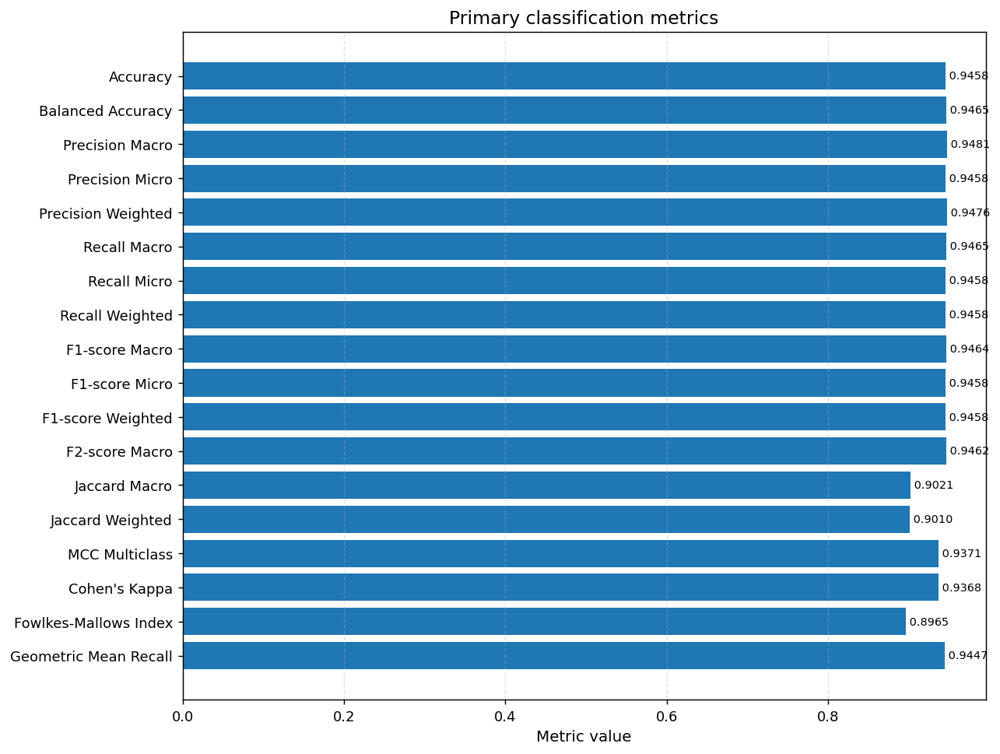

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/metric_group_1.png

----------------------------------------------------------------------------------------------------
Ranking and probability metrics
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Top-2 Accuracy,0.986456
1,Top-3 Accuracy,0.997743
2,Top-5 Accuracy,1.000000
3,ROC-AUC Macro OvR,0.995092
4,ROC-AUC Weighted OvR,0.995007
5,ROC-AUC Macro OvO,0.995142
6,ROC-AUC Weighted OvO,0.995082
7,PR-AUC Macro,0.978006
8,PR-AUC Micro,0.985994
9,PR-AUC Weighted,0.977689


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/metric_group_2.csv


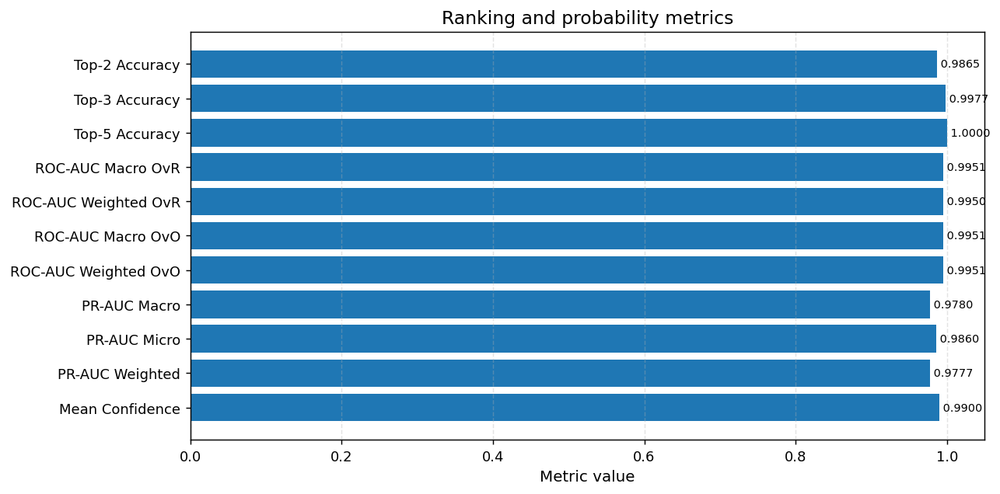

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/metric_group_2.png

----------------------------------------------------------------------------------------------------
Diagnostic macro metrics
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Macro Specificity,0.990957
1,Macro NPV,0.991008
2,Macro FPR,0.009043
3,Macro FNR,0.053513
4,Macro False Discovery Rate,0.051913
5,Macro False Omission Rate,0.008992
6,Macro Youden Index,0.937444


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/metric_group_3.csv


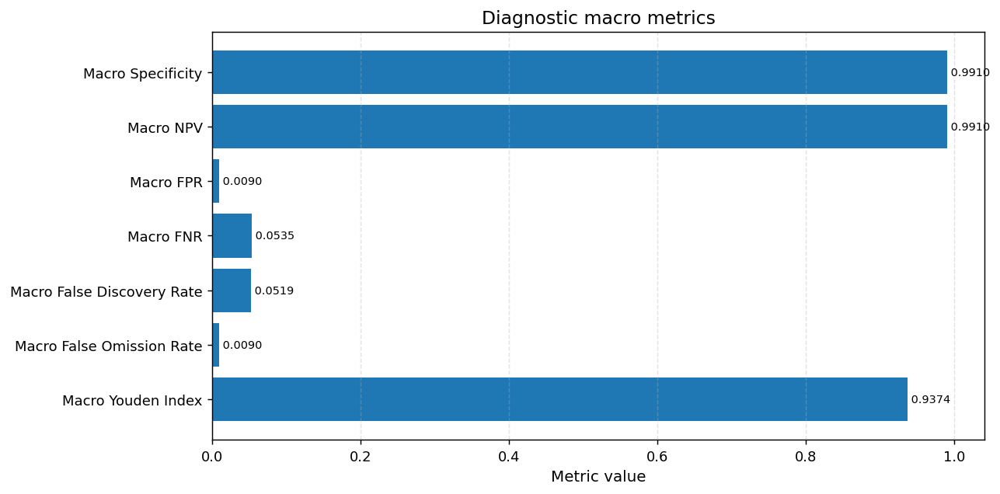

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/metric_group_3.png

----------------------------------------------------------------------------------------------------
Loss, error, and calibration metrics
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Hamming Loss,0.054176
1,Zero-One Loss,0.054176
2,Log Loss,0.285920
3,Negative Log-Likelihood,0.285920
4,Multiclass Brier Score,0.100154
5,Top-label ECE,0.051370
6,Maximum Calibration Error,0.631754
7,Adaptive Calibration Error,0.043900
8,Mean Predictive Entropy,0.027937


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/metric_group_4.csv


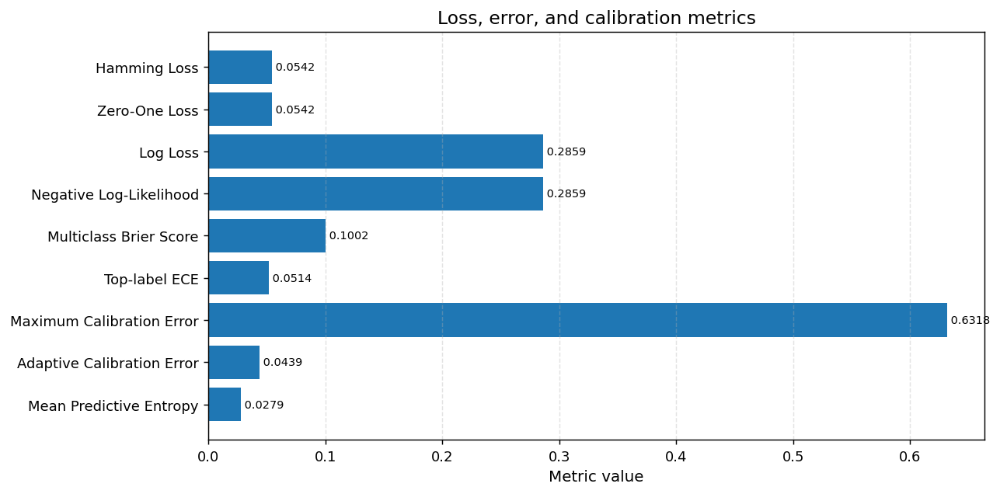

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/metric_group_4.png


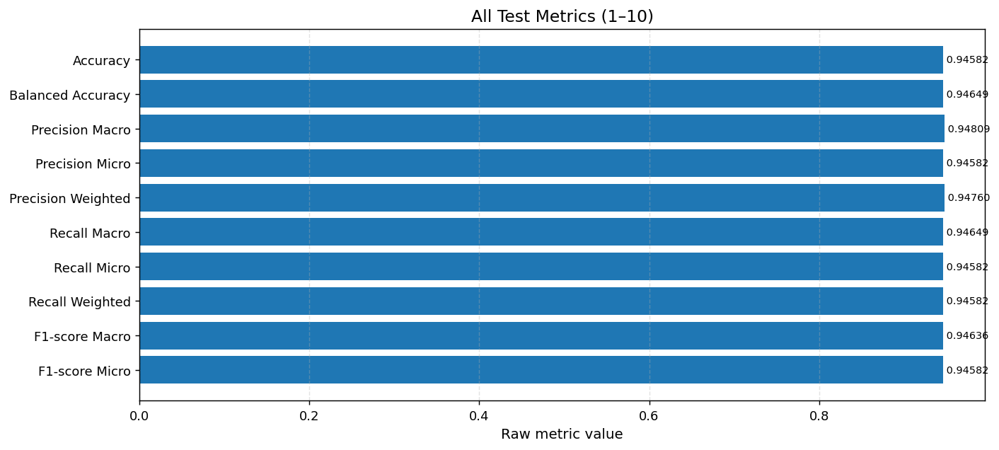

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_test_metrics_1_10.png


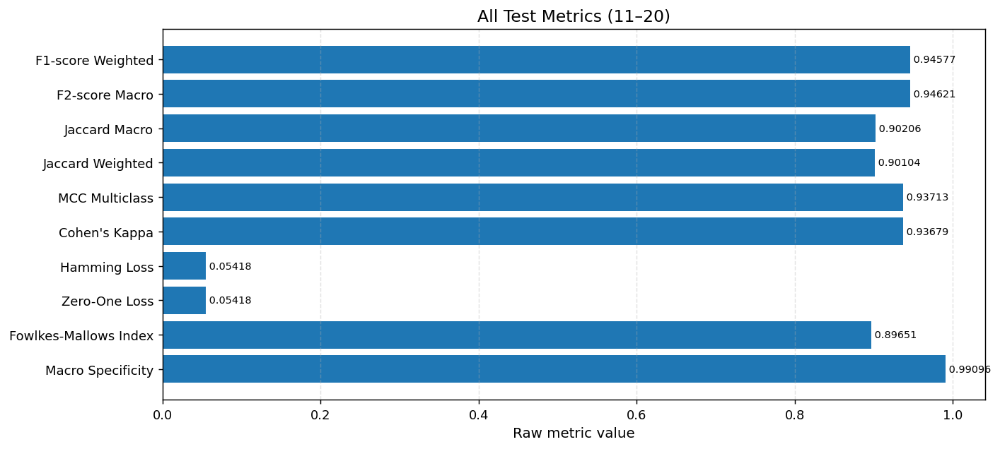

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_test_metrics_11_20.png


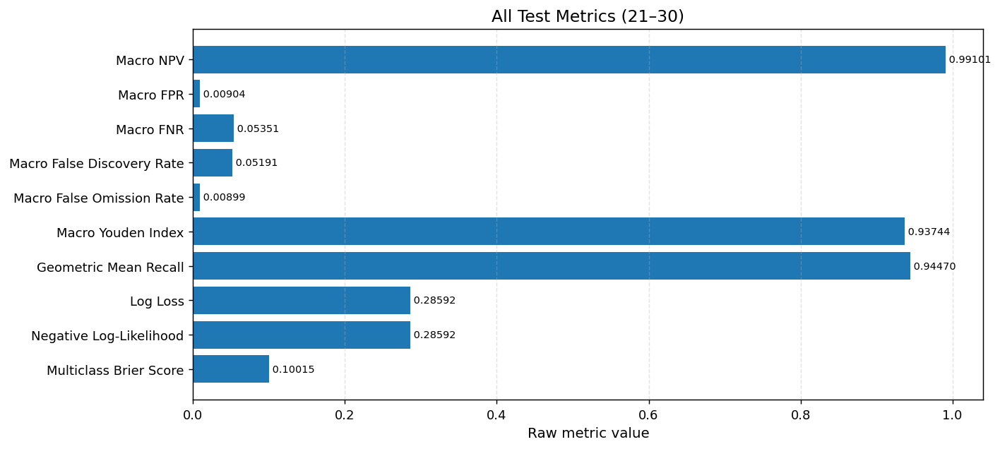

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_test_metrics_21_30.png


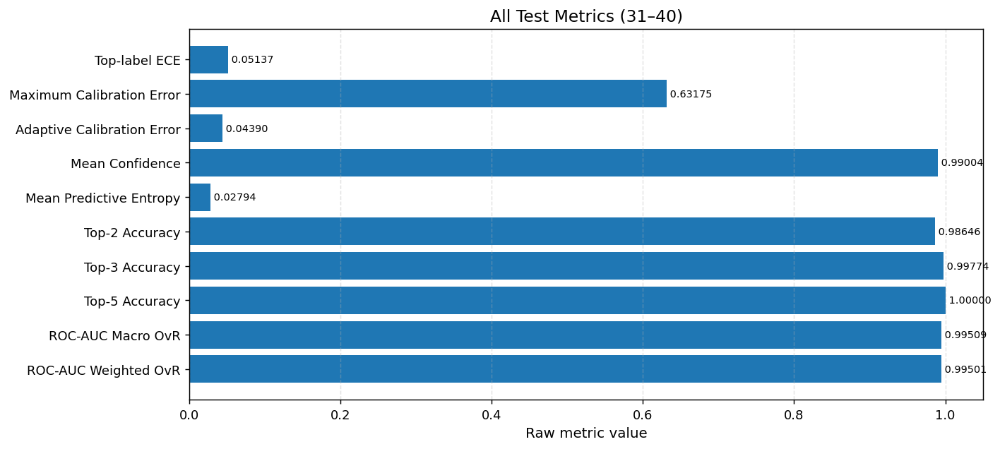

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_test_metrics_31_40.png


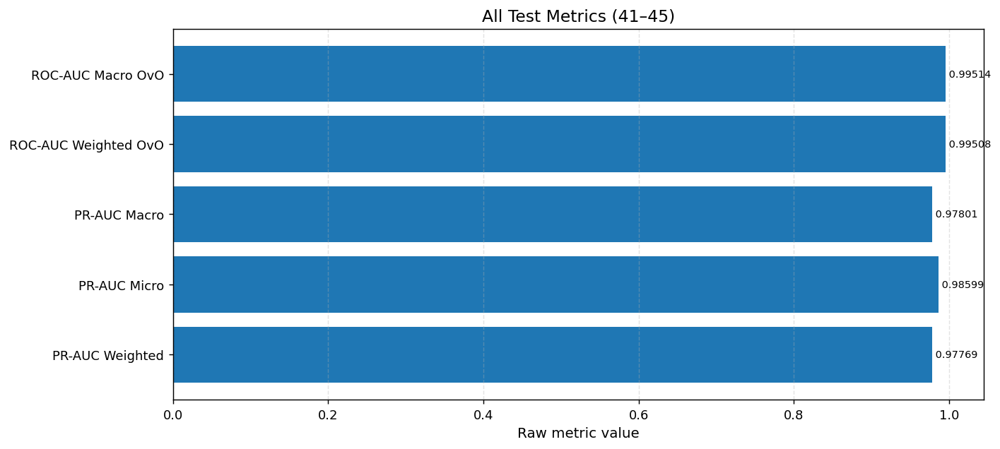

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_test_metrics_41_45.png

COMPLETE PER-CLASS ONE-VS-REST METRICS


,Class,Support,TP,TN,FP,FN,Sensitivity / Recall,Specificity,Precision / PPV,NPV,...,False Discovery Rate,False Omission Rate,Youden Index,LR+,LR-,Diagnostic Odds Ratio,ROC-AUC OvR,PR-AUC,Brier Score,Classwise ECE
0,Anthracnose,62,62,380,1,0,1.000000,0.997375,0.984127,1.000000,...,0.015873,0.000000,0.997375,381.000000,0.000000,inf,1.000000,1.000000,0.000498,0.001150
1,Citrus Canker,63,63,378,2,0,1.000000,0.994737,0.969231,1.000000,...,0.030769,0.000000,0.994737,190.000000,0.000000,inf,0.999958,0.999752,0.004269,0.005286
2,Citrus Greening Huanglongbing,63,59,377,3,4,0.936508,0.992105,0.951613,0.989501,...,0.048387,0.010499,0.928613,118.624339,0.063997,1853.583333,0.997097,0.982313,0.014586,0.015734
3,Citrus Leaf Curl,64,60,367,12,4,0.937500,0.968338,0.833333,0.989218,...,0.166667,0.010782,0.905838,29.609375,0.064544,458.750000,0.991878,0.938582,0.033314,0.034374
4,Citrus Leafminer,65,54,373,5,11,0.830769,0.986772,0.915254,0.971354,...,0.084746,0.028646,0.817542,62.806154,0.171499,366.218182,0.980260,0.938664,0.034290,0.036555
5,Healthy Lemon Leaf,63,63,380,0,0,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,1.000000,inf,0.000000,inf,1.000000,1.000000,0.000000,0.000079
6,Swallowtail Larval Herbivory (Deficiency),63,58,379,1,5,0.920635,0.997368,0.983051,0.986979,...,0.016949,0.013021,0.918003,349.841270,0.079574,4396.400000,0.996449,0.986728,0.013198,0.015278


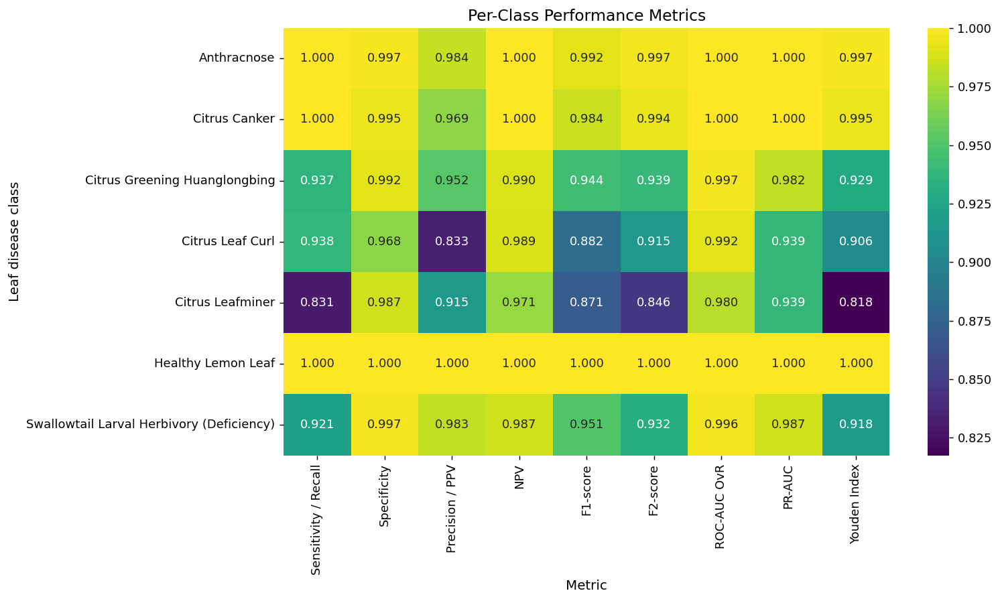

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_performance_metrics.png


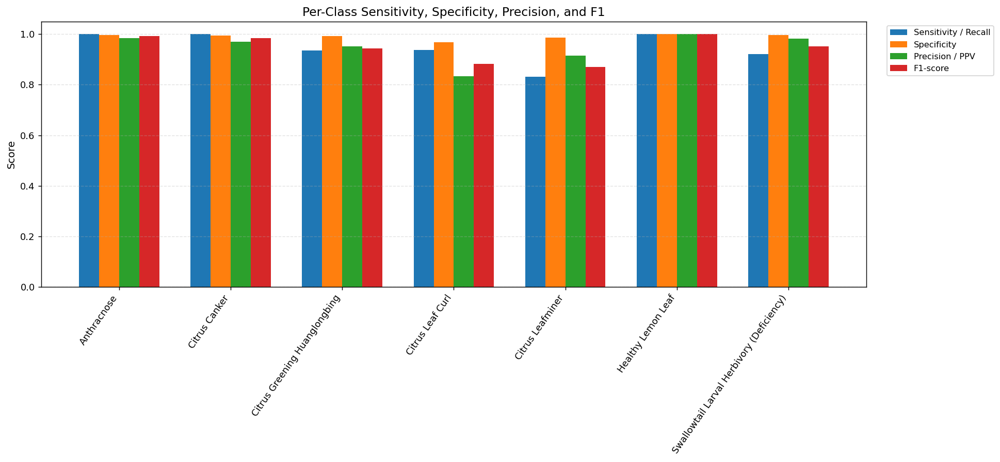

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_core_metrics_grouped.png


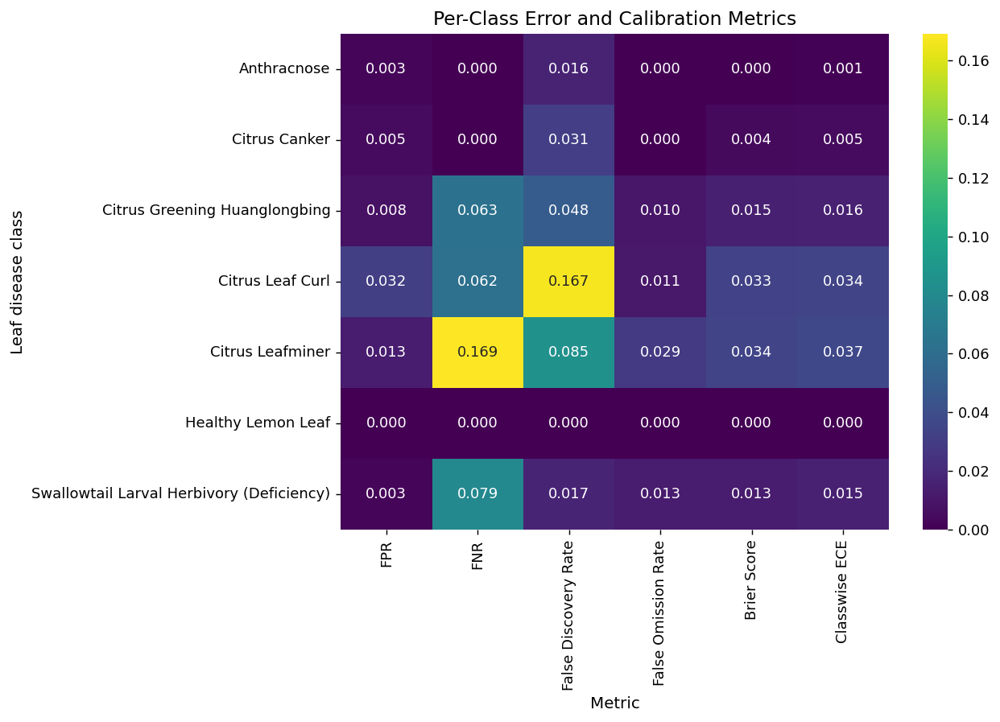

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_error_calibration_metrics.png


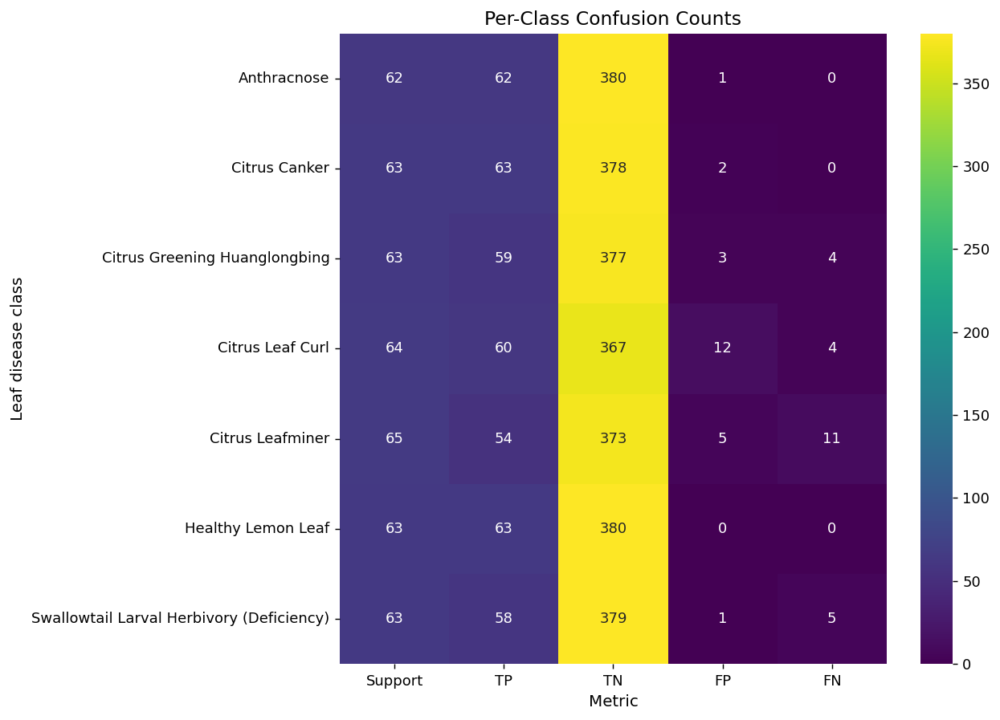

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_confusion_counts.png


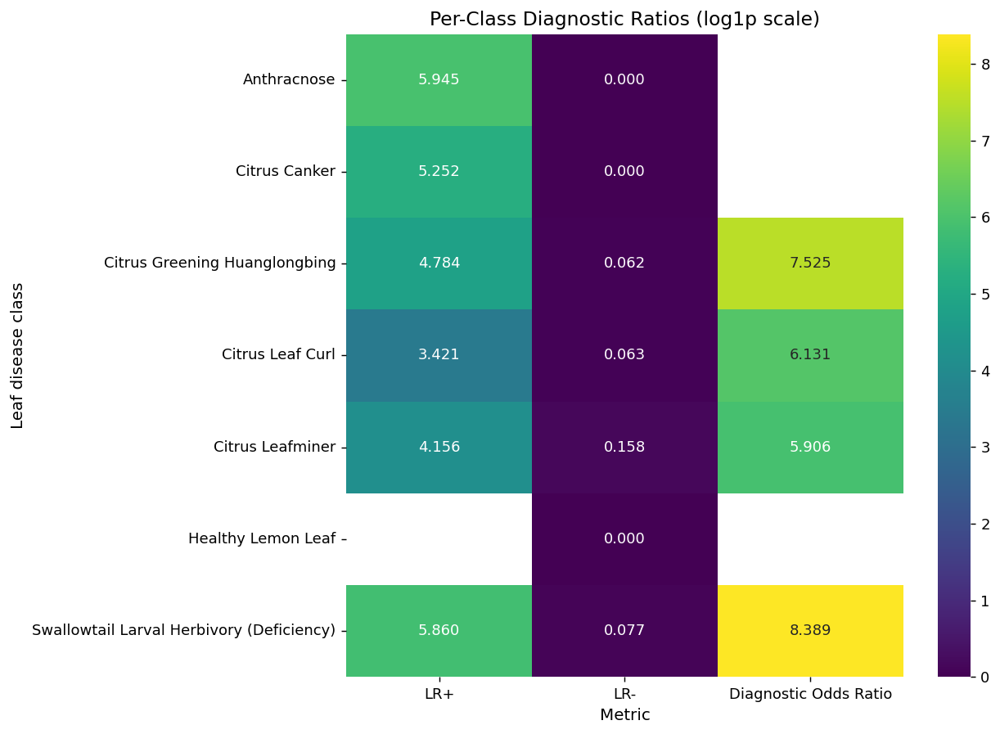

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_diagnostic_ratios_log.png


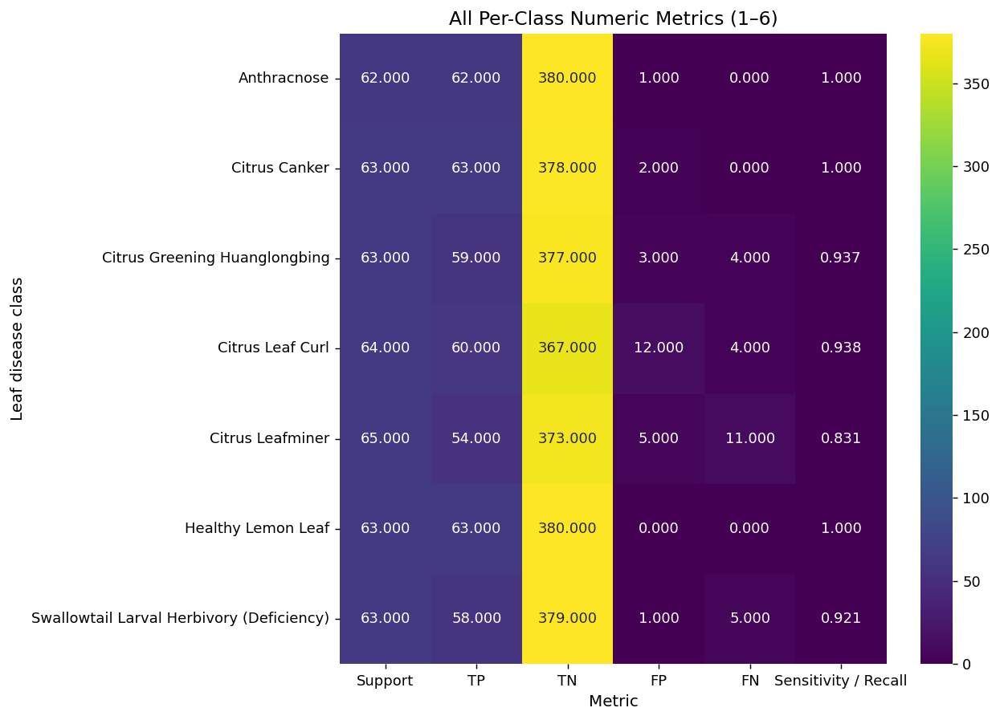

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_per_class_metrics_1_6.png


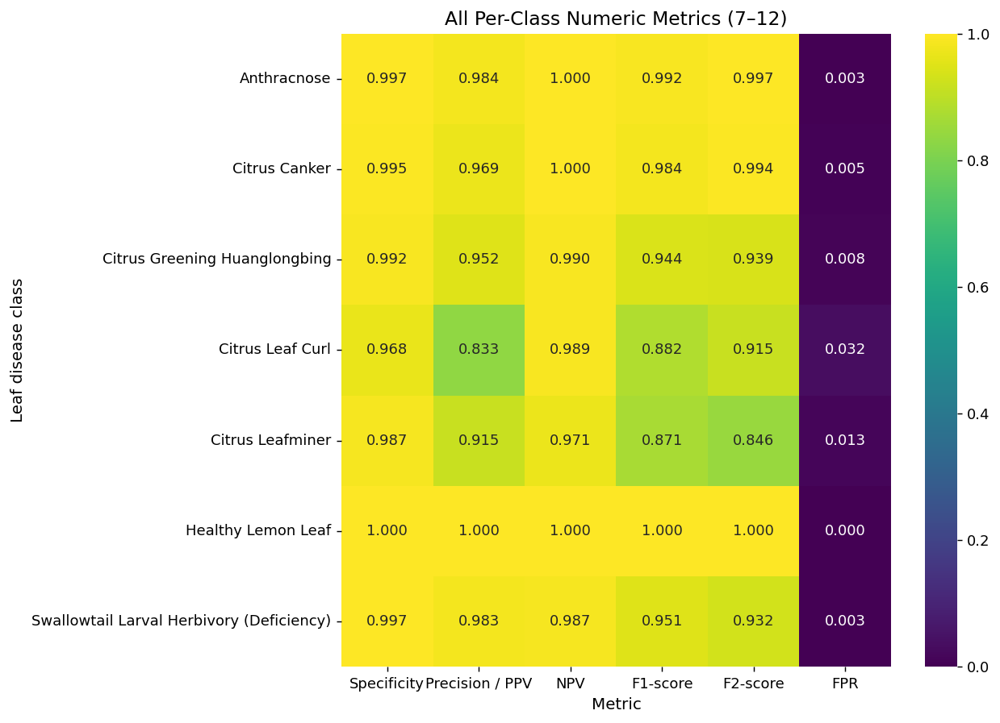

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_per_class_metrics_7_12.png


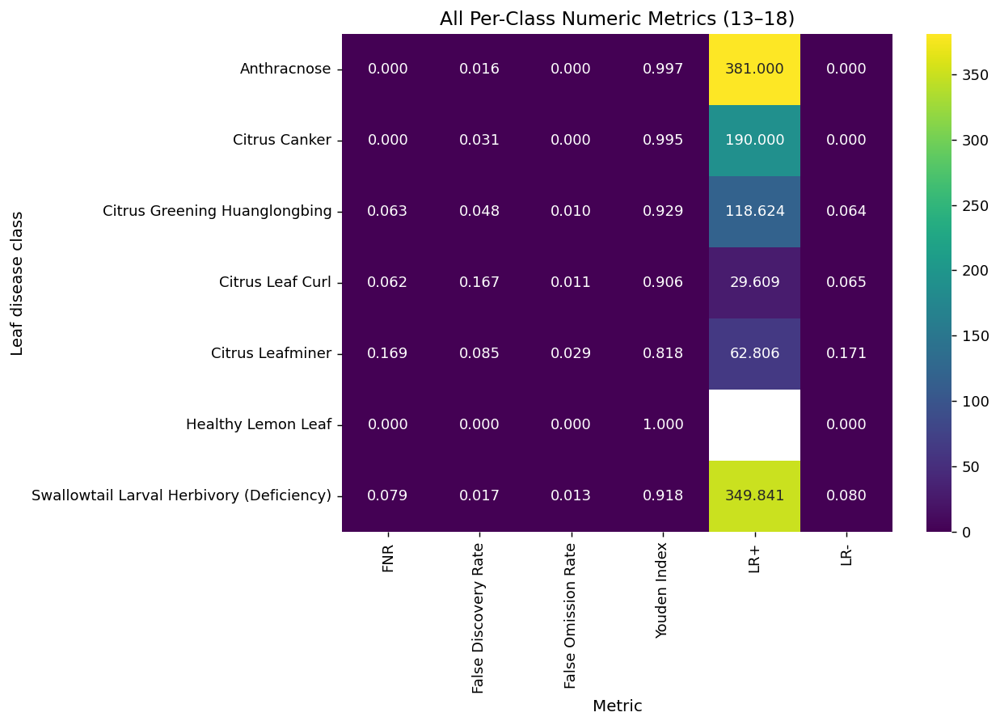

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_per_class_metrics_13_18.png


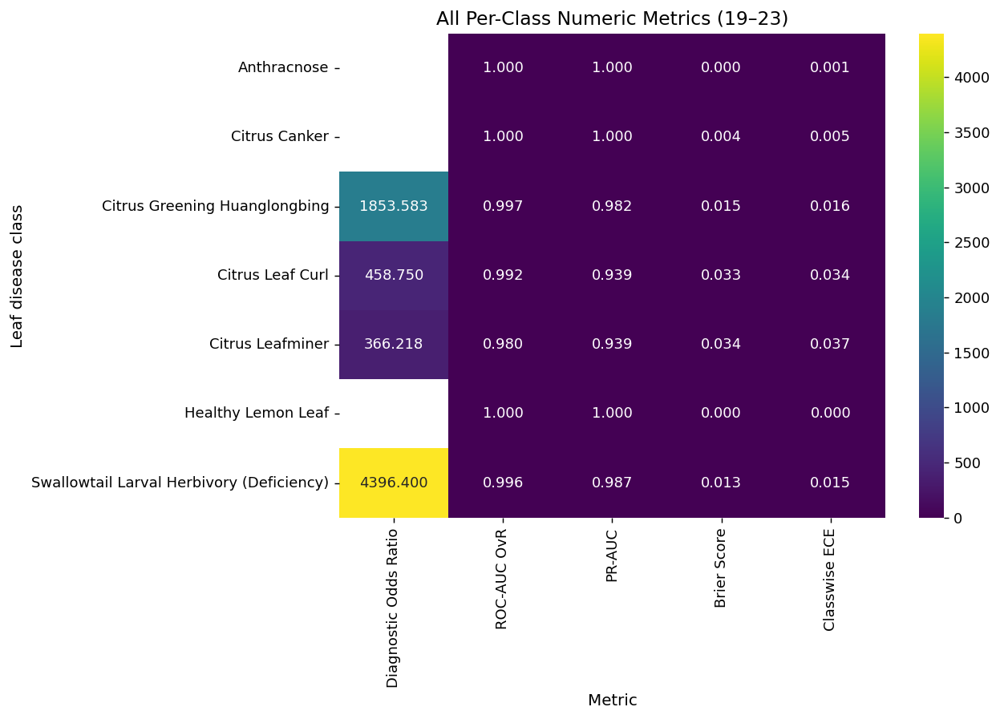

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/all_per_class_metrics_19_23.png

Bootstrap 95% confidence intervals


,Metric,Bootstrap Mean,95% CI Lower,95% CI Upper,Valid Iterations
0,Accuracy,0.945702,0.923251,0.966140,1000
1,Balanced Accuracy,0.946354,0.926985,0.966780,1000
2,Macro F1,0.945817,0.925554,0.967483,1000
3,Weighted F1,0.945629,0.923309,0.966369,1000
4,MCC,0.936987,0.911000,0.960735,1000
5,Cohen Kappa,0.936514,0.910276,0.960455,1000
6,Macro ROC-AUC OvR,0.995029,0.991383,0.998087,1000
7,Macro PR-AUC,0.977924,0.962381,0.990667,1000


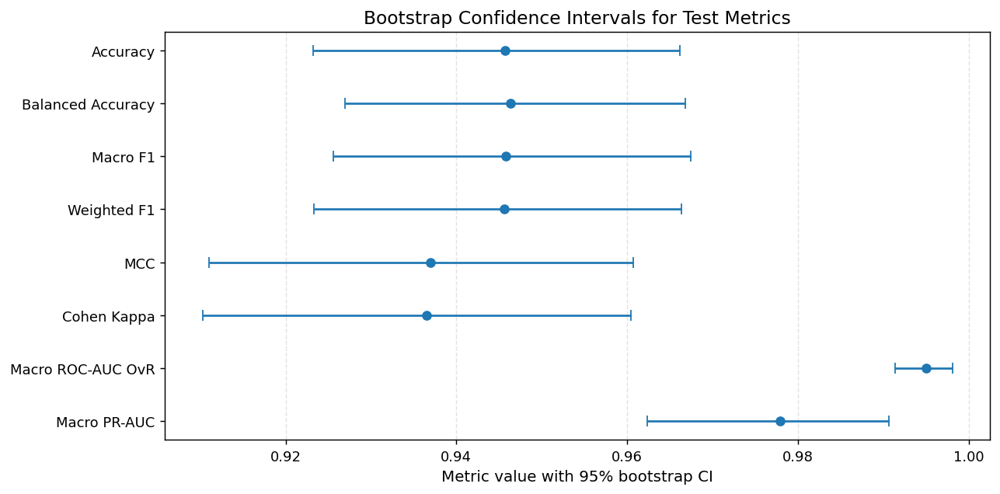

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/bootstrap_confidence_intervals.png


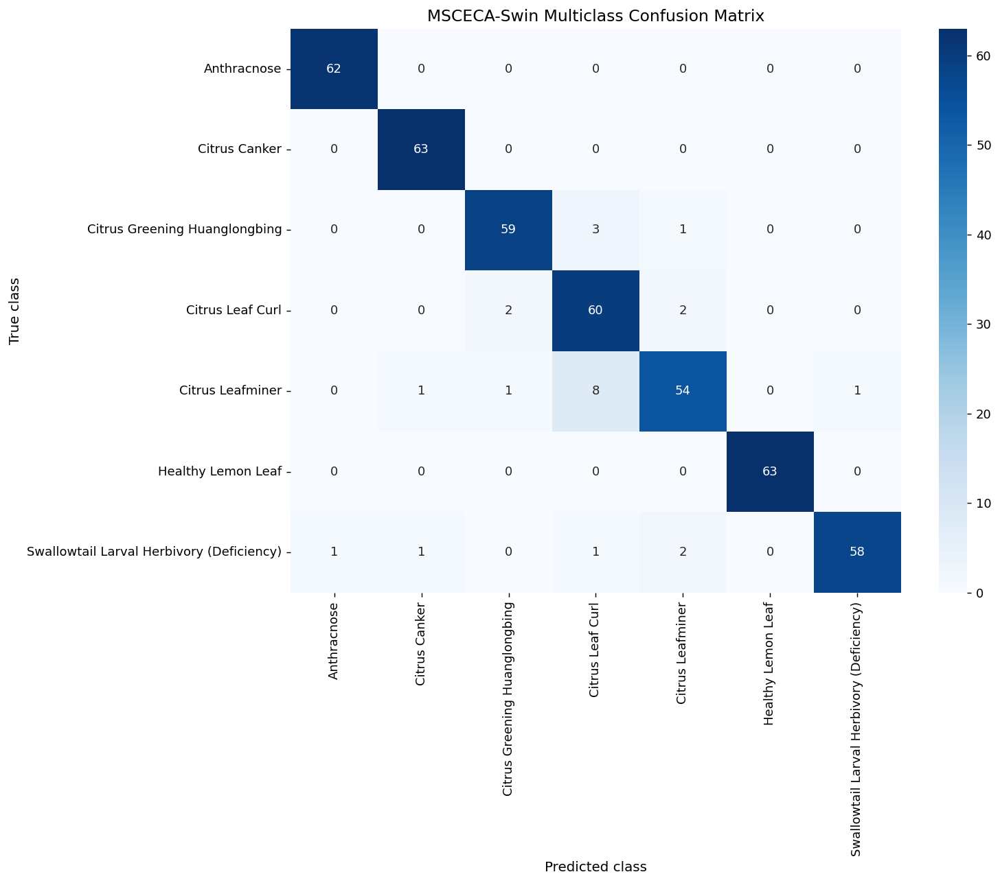

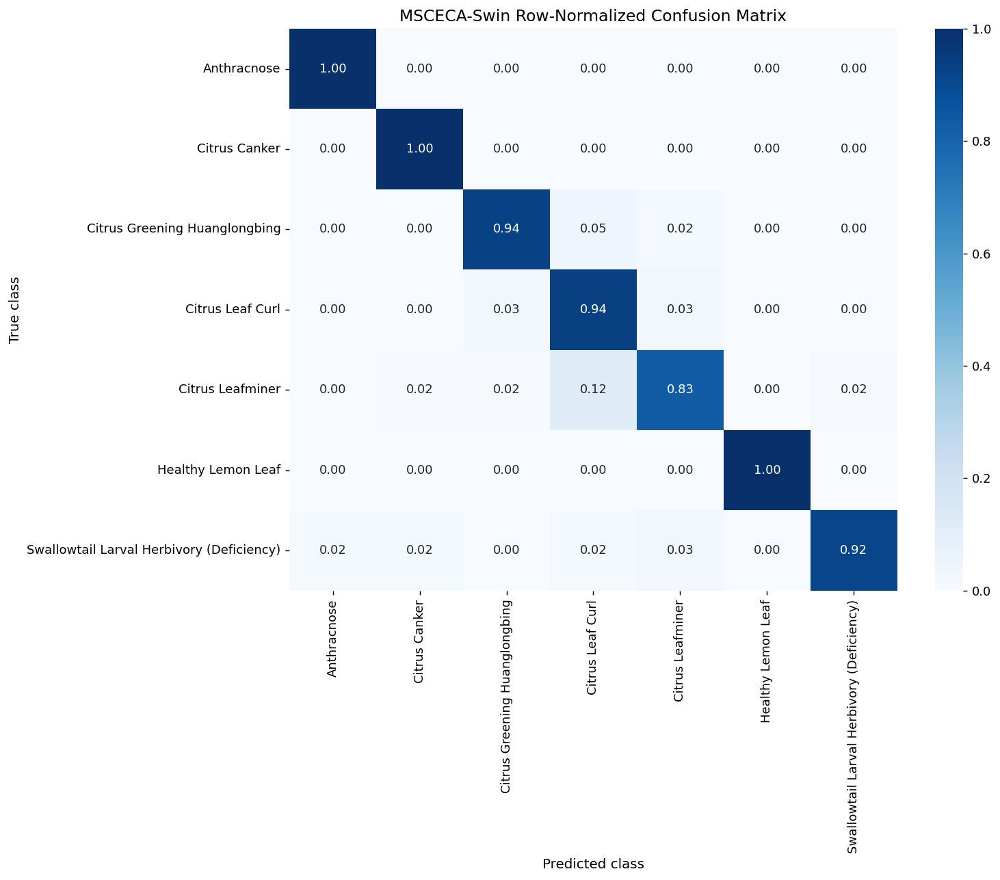

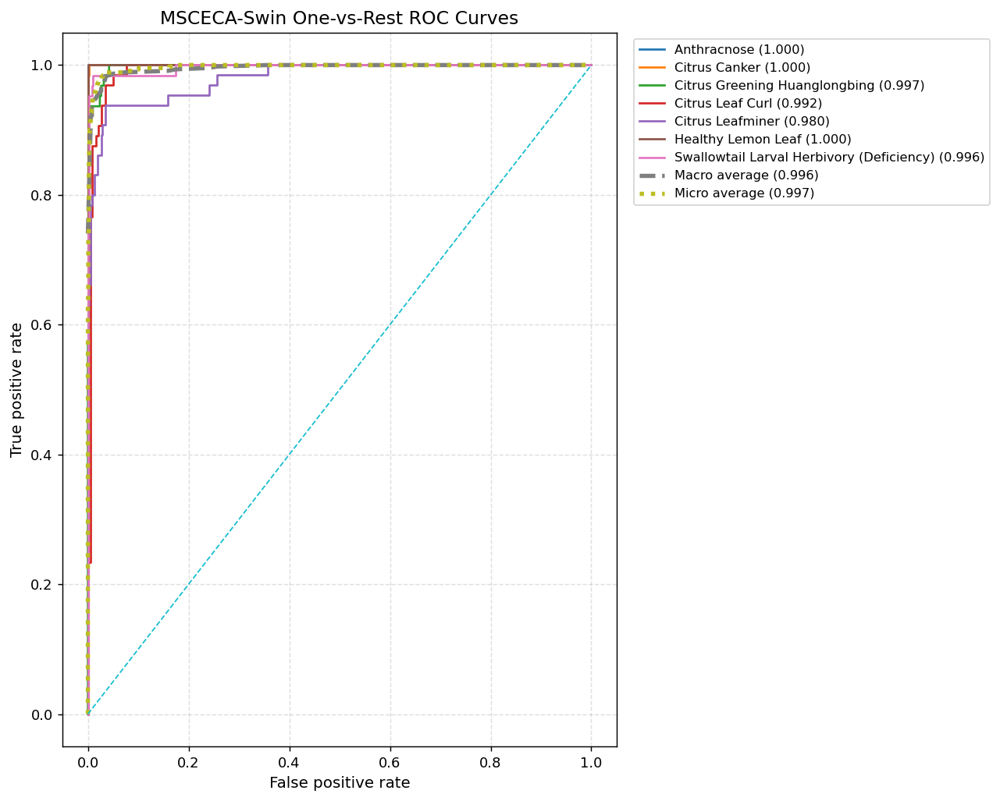

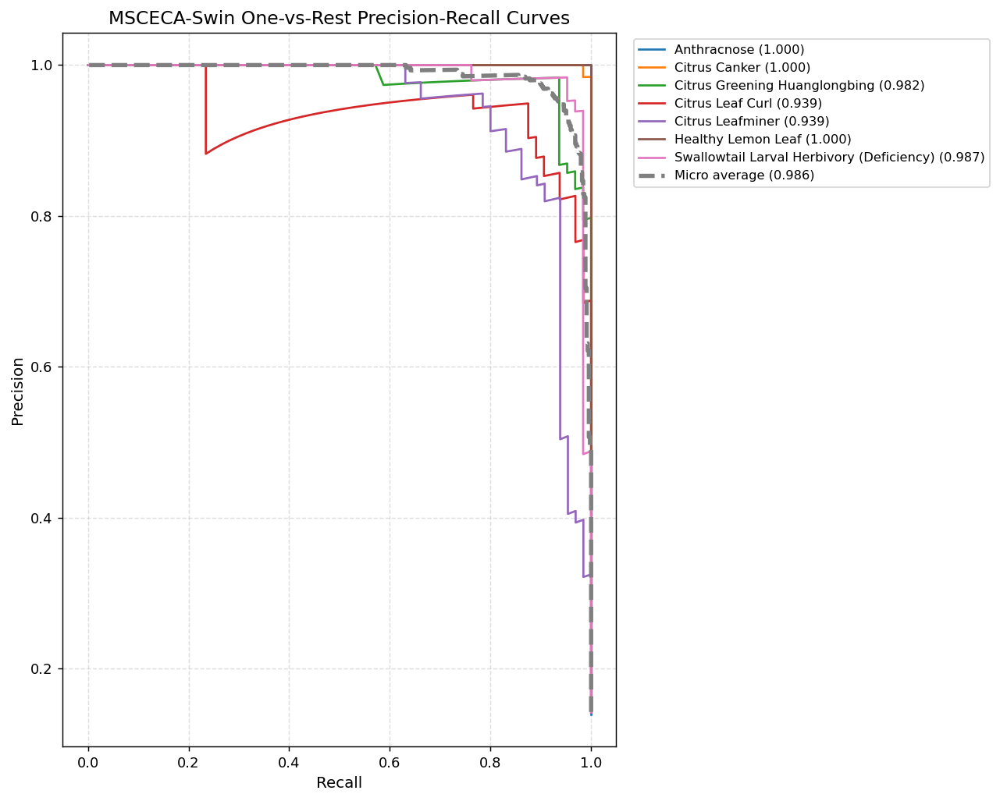

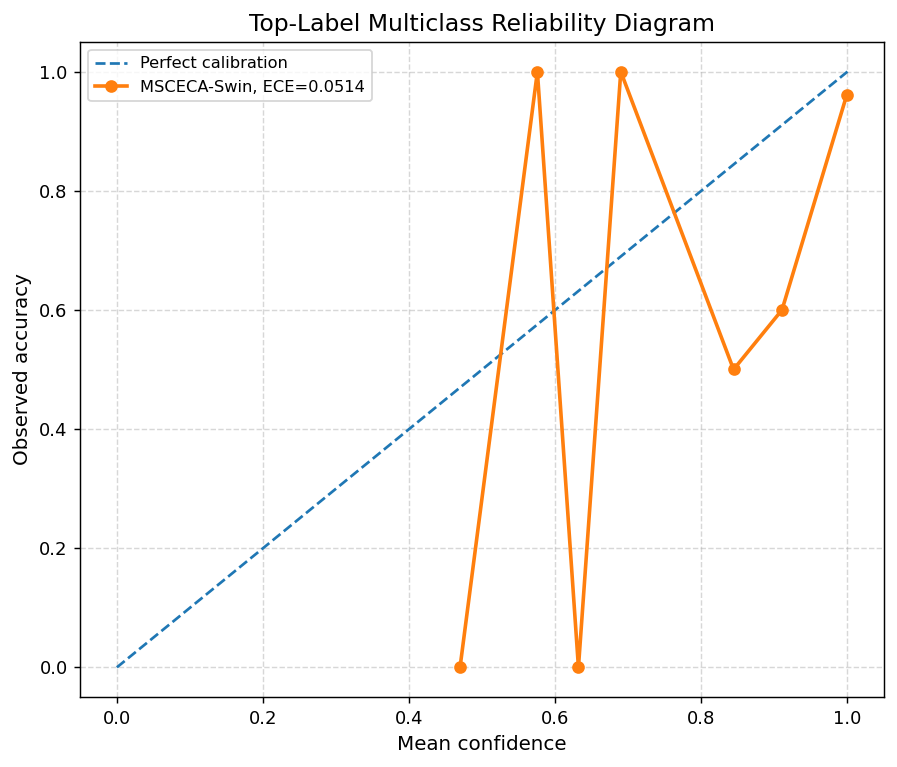

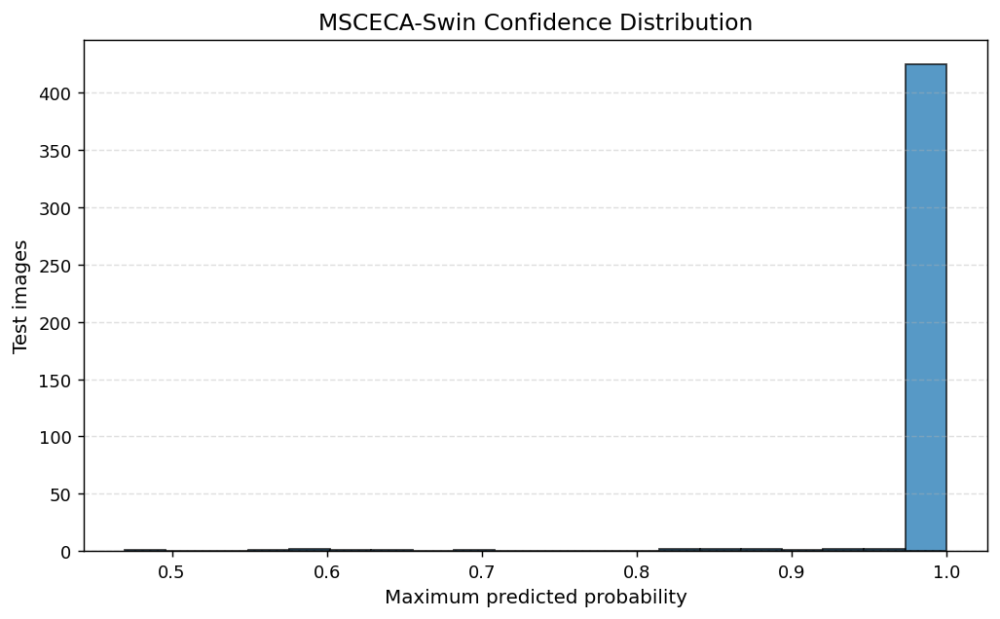

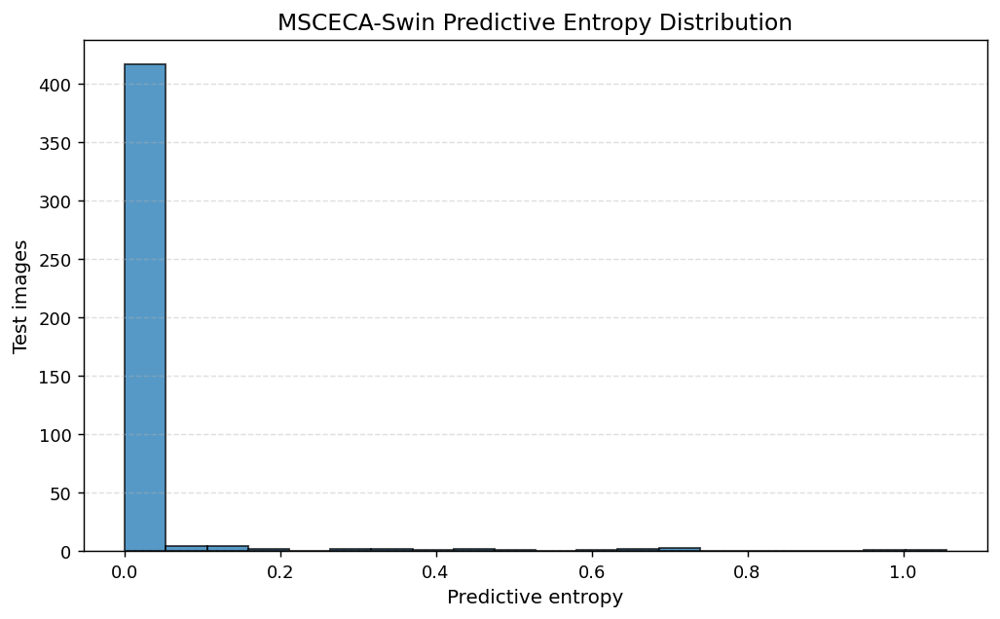

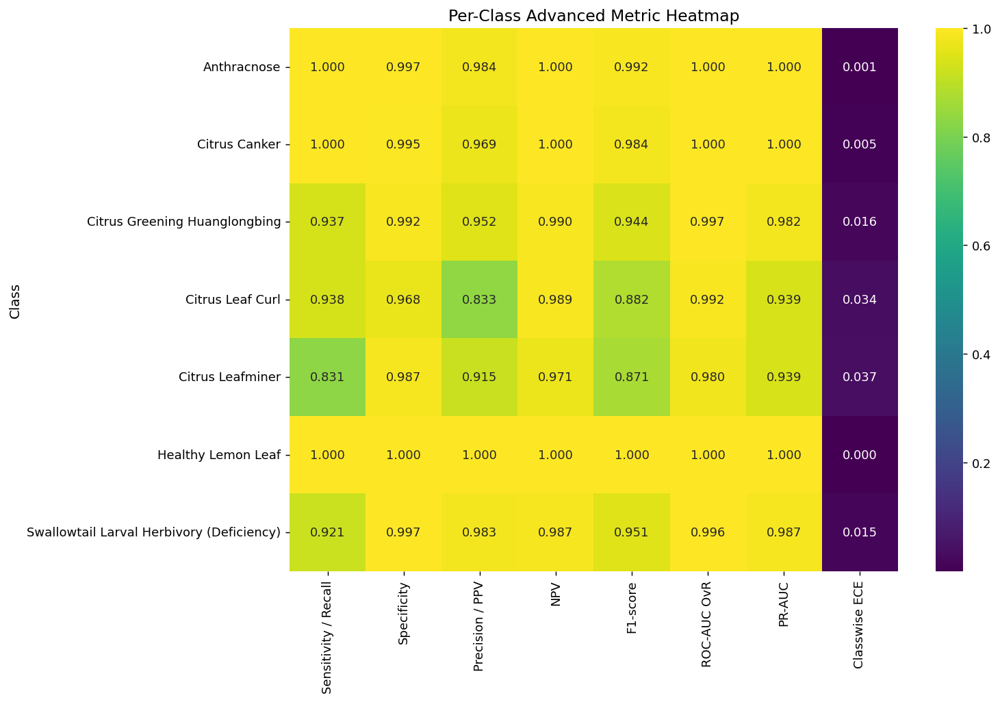

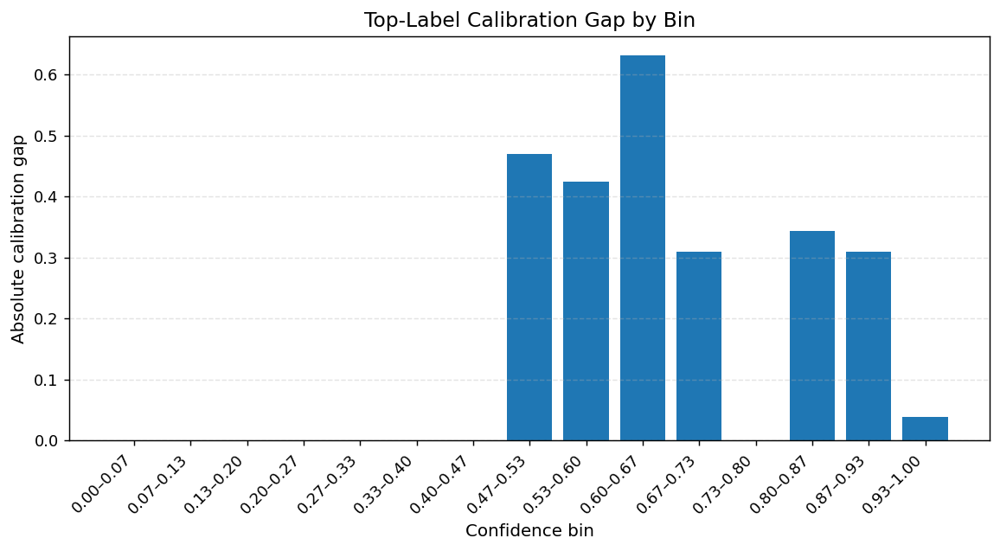

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/top_label_calibration_gap.png


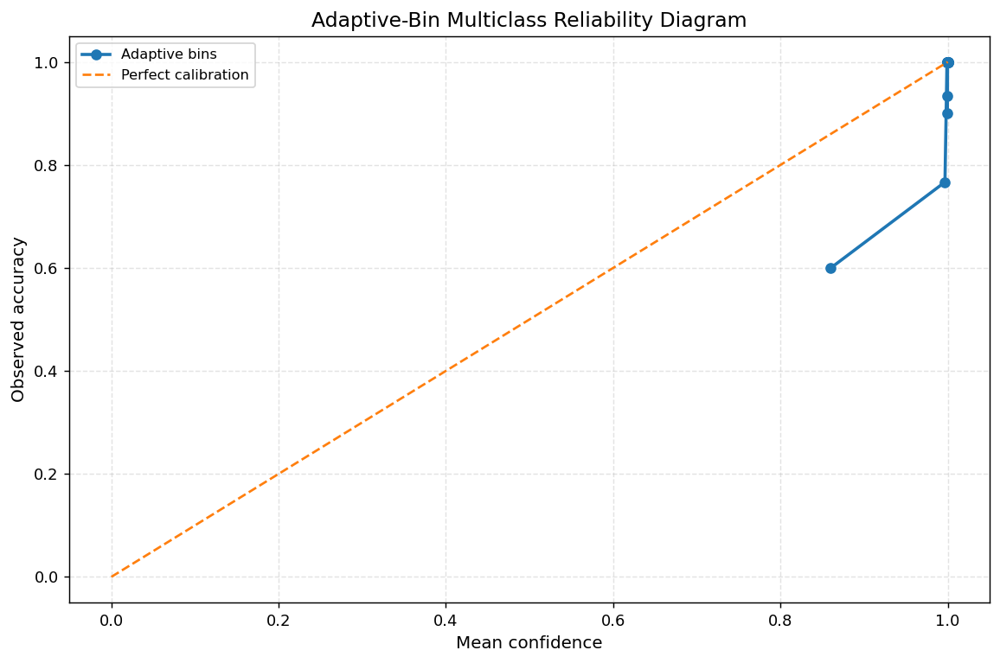

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/adaptive_reliability_diagram.png


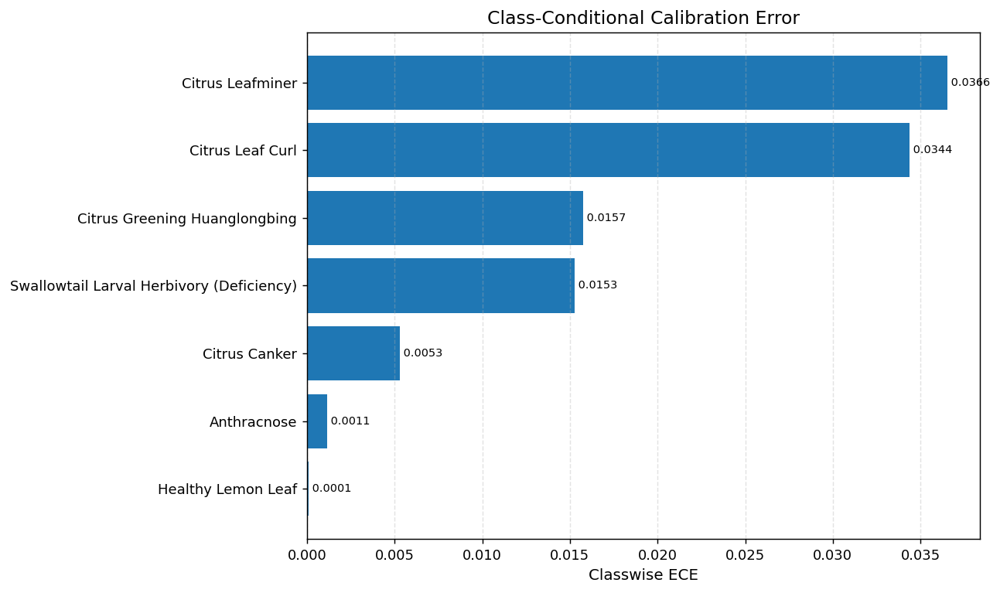

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/classwise_ece.png

Chi-square test on confusion matrix


,Chi-square Statistic,p-value,Degrees of Freedom
0,2353.096779,0.0,36


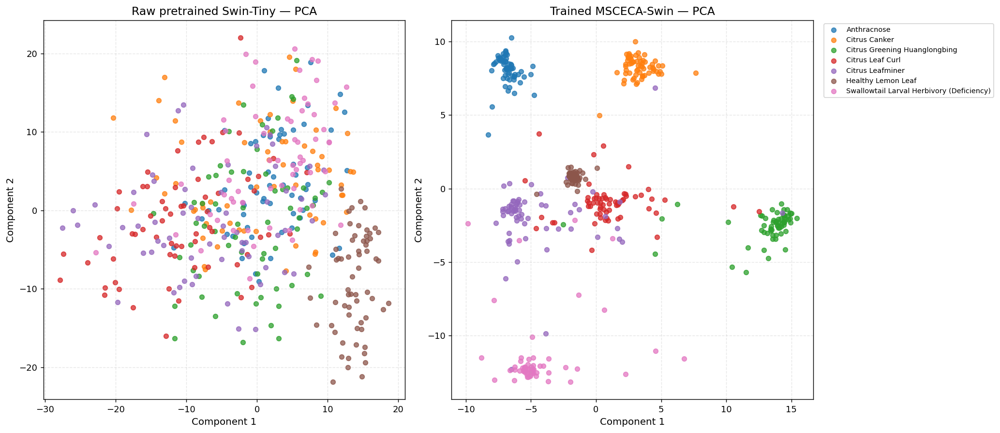

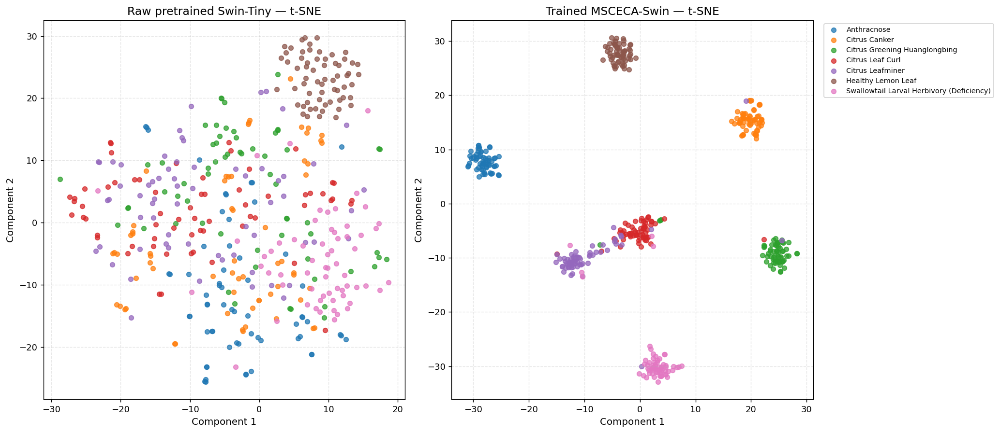

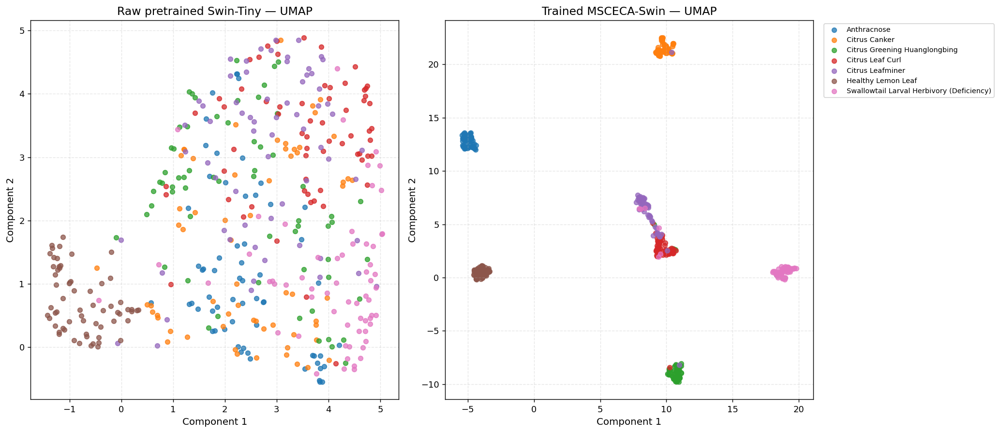


Raw Swin-Tiny vs MSCECA-Swin embedding quality


,Feature Model,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,Raw pretrained Swin-Tiny,0.034195,16.349960,4.708871
1,Trained MSCECA-Swin,0.598288,297.385315,0.724991


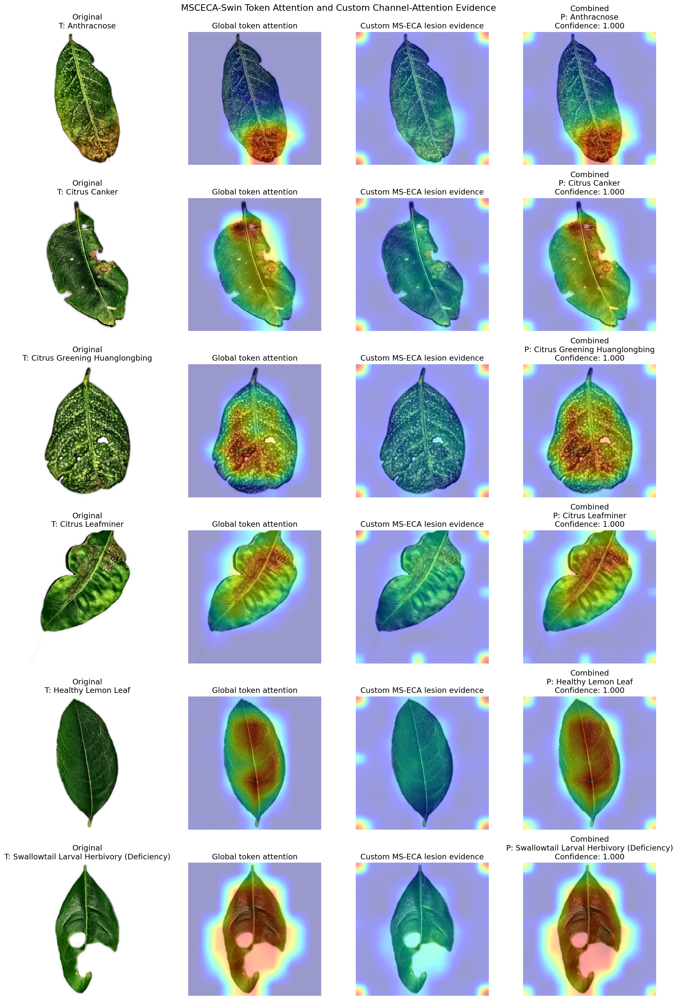

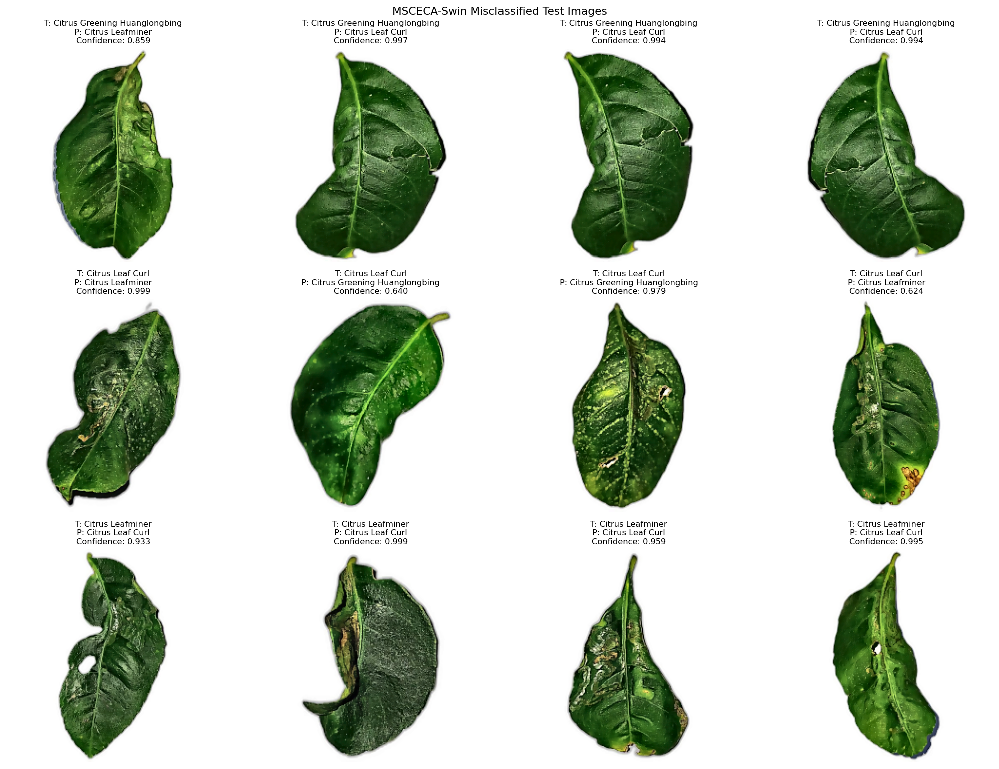


Running multiclass MC Dropout with 20 passes...

MC Dropout uncertainty summary


,Uncertainty Metric,Value
0,MC Accuracy,0.945824
1,MC Balanced Accuracy,0.946487
2,MC Macro F1,0.946359
3,MC Weighted F1,0.945771
4,MC MCC,0.937134
5,MC Macro ROC-AUC,0.994799
6,Mean MC Confidence,0.989043
7,Mean Predictive Entropy,0.033749
8,Mean Expected Entropy,0.031213
9,Mean Mutual Information,0.002536



Per-sample uncertainty preview


,True Label,Predicted Label,True Class,Predicted Class,Correct,MC Confidence,Predictive Entropy,Expected Entropy,Mutual Information,Variation Ratio,Predicted-Class Probability STD
0,0,0,Anthracnose,Anthracnose,1,0.999681,0.003313,0.002977,0.000336,0.0,0.000498
1,0,0,Anthracnose,Anthracnose,1,0.999842,0.001789,0.001675,0.000113,0.0,0.000174
2,0,0,Anthracnose,Anthracnose,1,0.999808,0.002169,0.002027,0.000142,0.0,0.000220
3,0,0,Anthracnose,Anthracnose,1,0.999721,0.002994,0.002705,0.000289,0.0,0.000413
4,0,0,Anthracnose,Anthracnose,1,0.999464,0.005464,0.004728,0.000735,0.0,0.001253
5,0,0,Anthracnose,Anthracnose,1,0.999570,0.004385,0.003851,0.000535,0.0,0.000789
6,0,0,Anthracnose,Anthracnose,1,0.999801,0.002195,0.002023,0.000172,0.0,0.000242
7,0,0,Anthracnose,Anthracnose,1,0.999832,0.001887,0.001806,0.000081,0.0,0.000138
8,0,0,Anthracnose,Anthracnose,1,0.999877,0.001441,0.001350,0.000091,0.0,0.000131
9,0,0,Anthracnose,Anthracnose,1,0.999635,0.003879,0.003598,0.000281,0.0,0.000427



Correct versus incorrect uncertainty


,Correct,Count,Mean_Confidence,Mean_Predictive_Entropy,Mean_Mutual_Information,Mean_Variation_Ratio,Mean_Probability_STD,Group
0,0,24,0.915541,0.229158,0.015538,0.031250,0.03603,Incorrect
1,1,419,0.993253,0.022556,0.001791,0.001909,0.00386,Correct


... (7 outputs left out)

,Metric,Deterministic,MC Dropout
0,Accuracy,0.945824,0.945824
1,Balanced Accuracy,0.946487,0.946487
2,F1-score Macro,0.946359,0.946359
3,F1-score Weighted,0.945771,0.945771
4,MCC Multiclass,0.937134,0.937134
5,Cohen's Kappa,0.936794,0.936794
6,ROC-AUC Macro OvR,0.995092,0.994799
7,PR-AUC Macro,0.978006,0.974634
8,Top-label ECE,0.051370,0.046014
9,Multiclass Brier Score,0.100154,0.099040


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/deterministic_vs_mc_dropout_metrics.csv

----------------------------------------------------------------------------------------------------
Per-Class Uncertainty Summary
----------------------------------------------------------------------------------------------------


,True Class,Samples,Accuracy,Mean_Confidence,Mean_Predictive_Entropy,Mean_Normalized_Entropy,Mean_Expected_Entropy,Mean_Mutual_Information,Mean_Variation_Ratio,Mean_Predicted_Class_STD,Mean_Margin_Uncertainty,Mean_Brier_Score,Mean_NLL
0,Anthracnose,62,1.000000,0.999638,0.003751,0.001928,0.003389,0.000362,0.000000,0.000556,0.000486,0.000000,0.000362
1,Citrus Canker,63,1.000000,0.999692,0.003238,0.001664,0.002949,0.000289,0.000000,0.000469,0.000428,0.000000,0.000308
2,Citrus Greening Huanglongbing,63,0.936508,0.995404,0.024833,0.012762,0.023407,0.001426,0.000000,0.002902,0.008183,0.121768,0.339400
3,Citrus Leaf Curl,64,0.937500,0.984522,0.047213,0.024263,0.044581,0.002632,0.006250,0.006738,0.029478,0.085326,0.193192
4,Citrus Leafminer,65,0.830769,0.978497,0.066358,0.034101,0.061934,0.004424,0.006923,0.010721,0.040523,0.335738,0.937528
5,Healthy Lemon Leaf,63,1.000000,0.999514,0.004275,0.002197,0.003820,0.000455,0.000000,0.000771,0.000745,0.000004,0.000487
6,Swallowtail Larval Herbivory (Deficiency),63,0.920635,0.966610,0.084846,0.043602,0.076782,0.008064,0.011111,0.016805,0.061825,0.141577,0.370728


Saved table: /kaggle/working/lemon_msceca_swin_outputs/tables/per_class_uncertainty_summary.csv


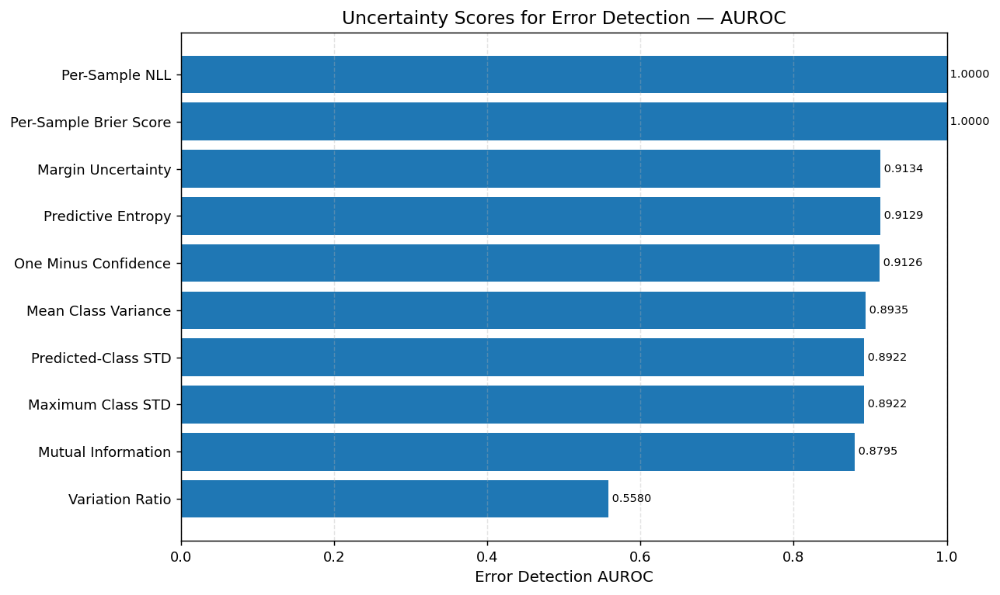

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_error_detection_auroc.png


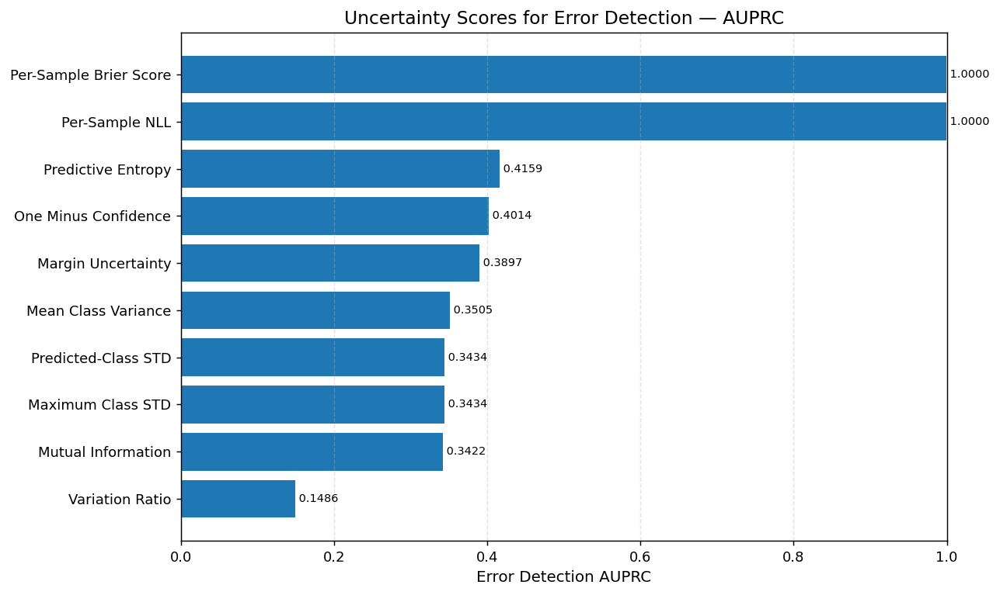

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_error_detection_auprc.png


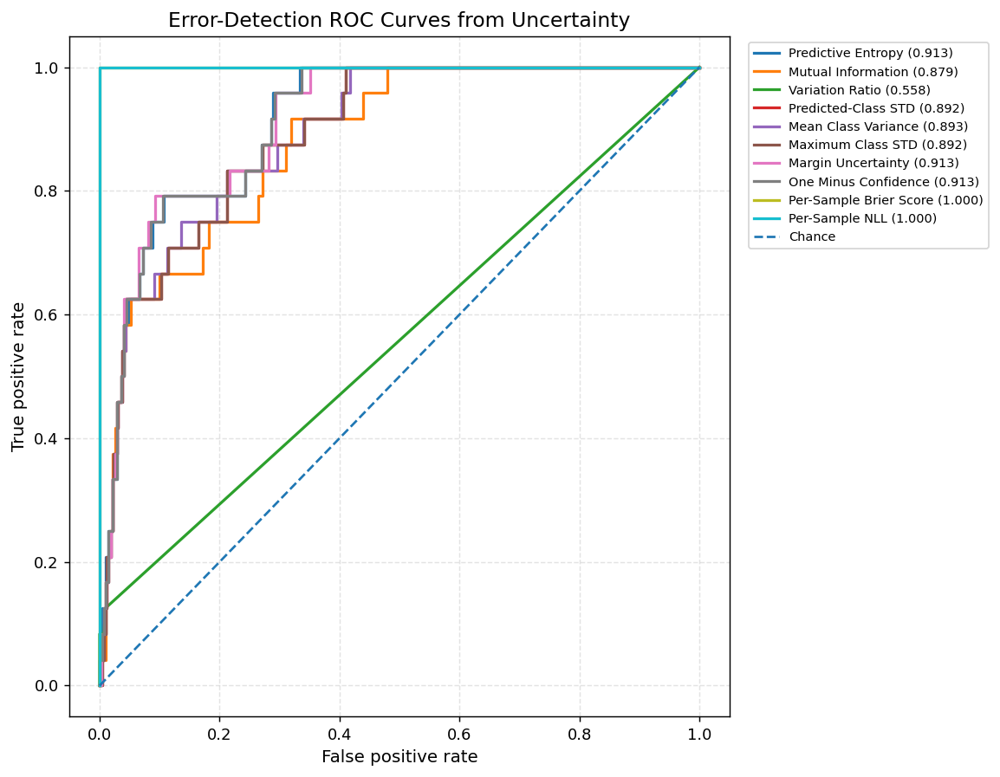

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_error_detection_roc_curves.png


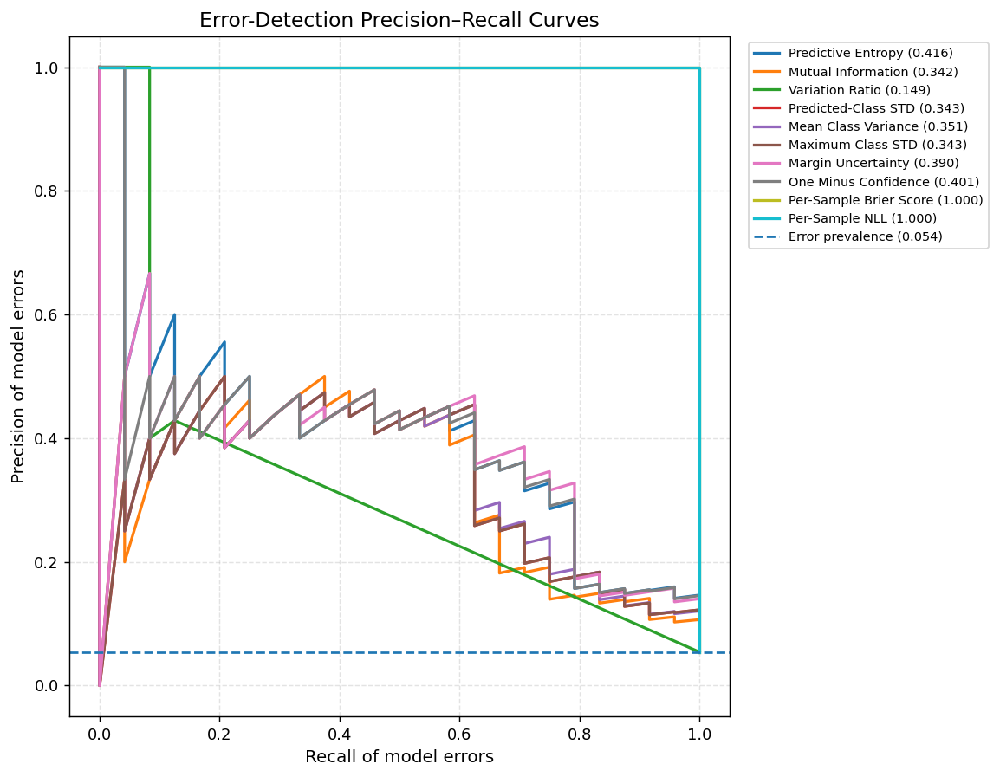

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_error_detection_pr_curves.png


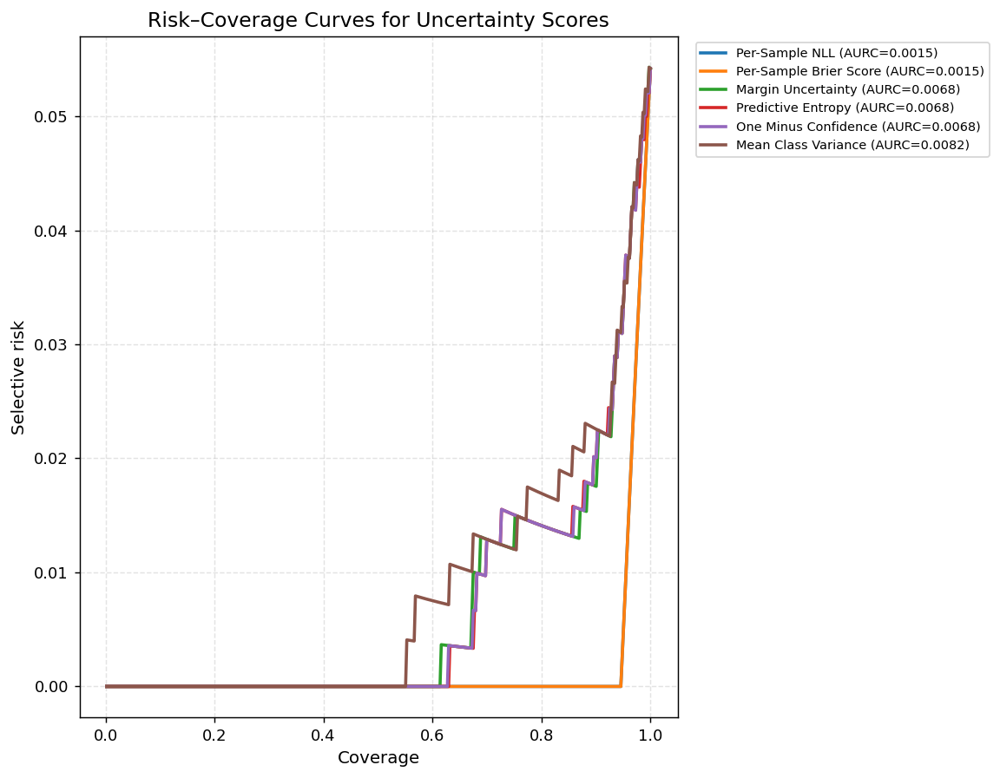

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/risk_coverage_curves.png


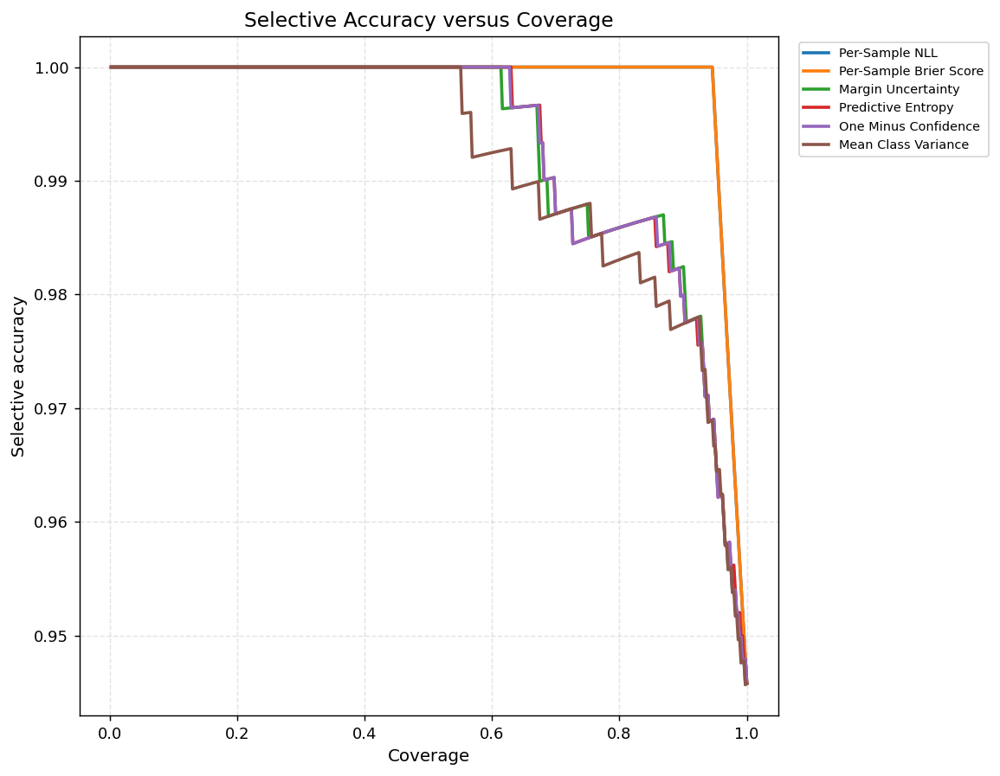

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/selective_accuracy_coverage.png


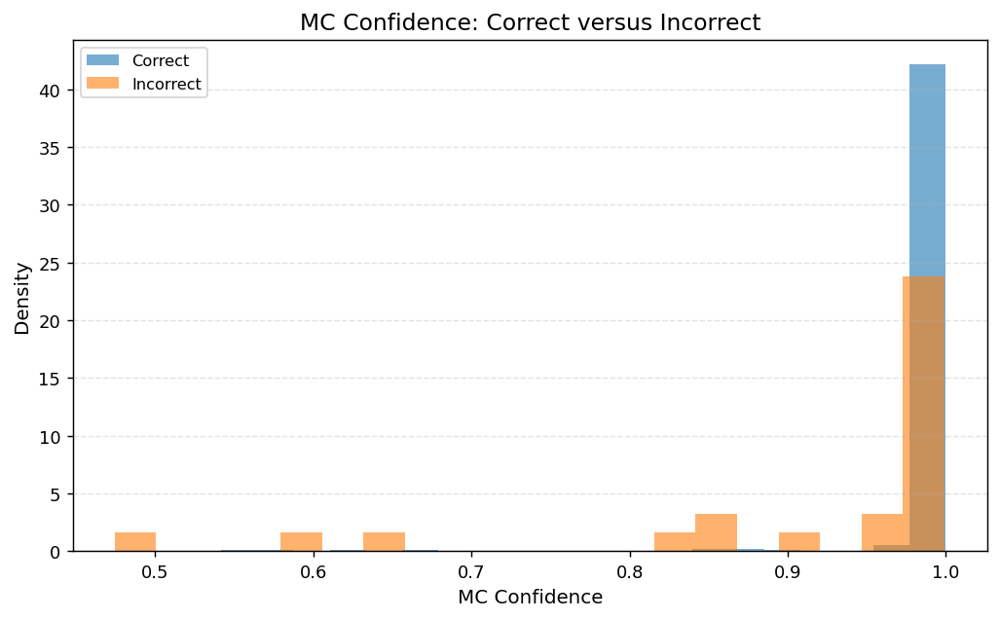

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_mc_confidence.png


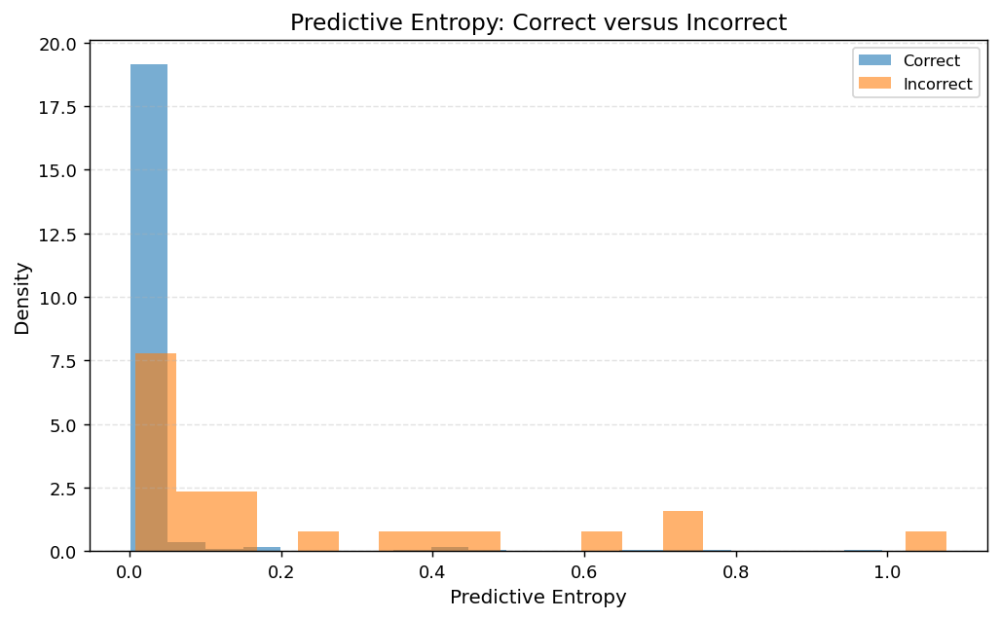

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_predictive_entropy.png


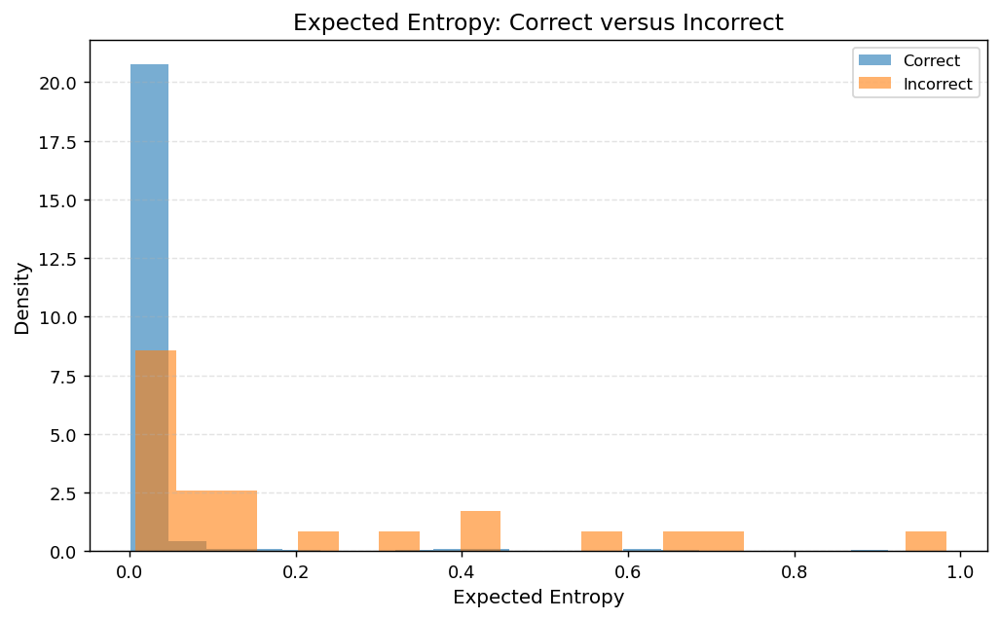

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_expected_entropy.png


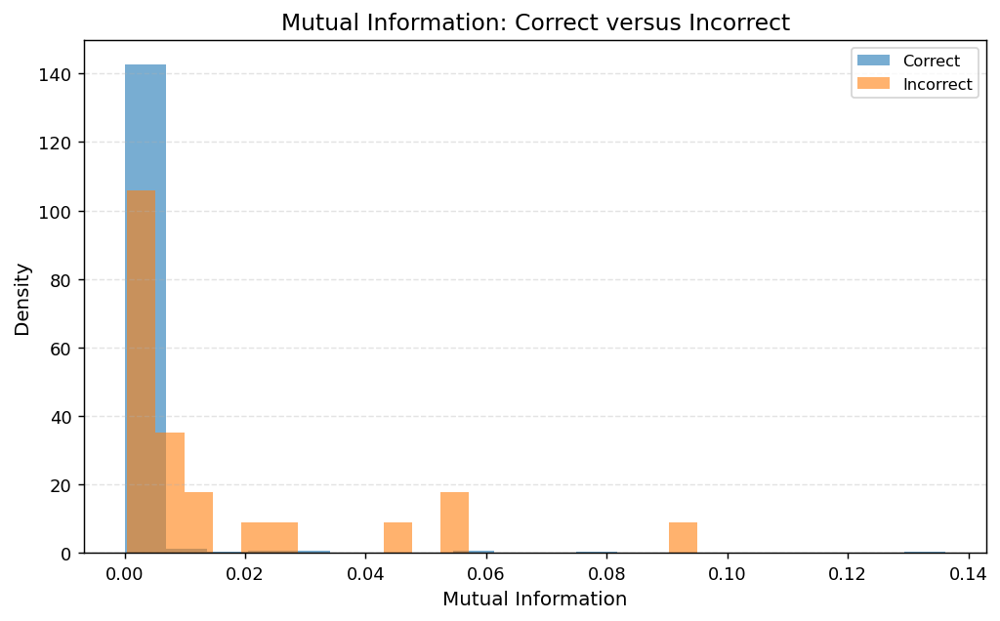

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_mutual_information.png


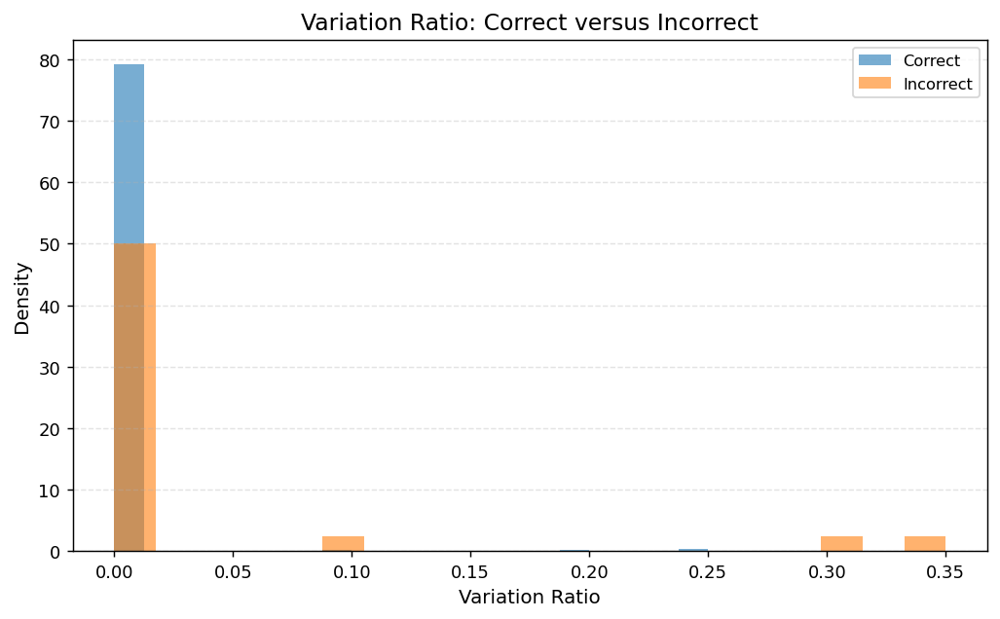

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_variation_ratio.png


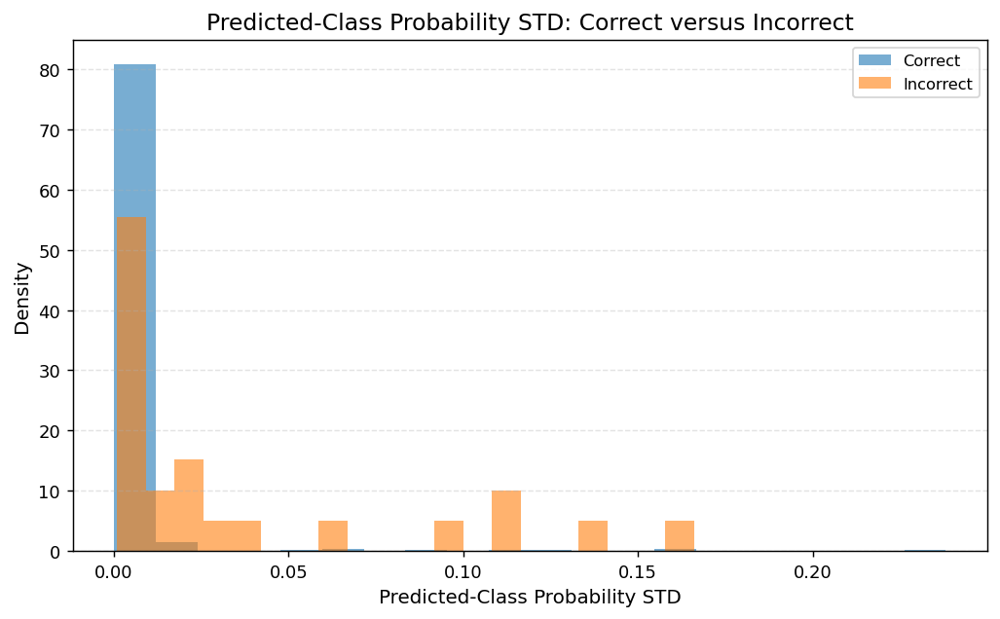

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_predicted_class_probability_std.png


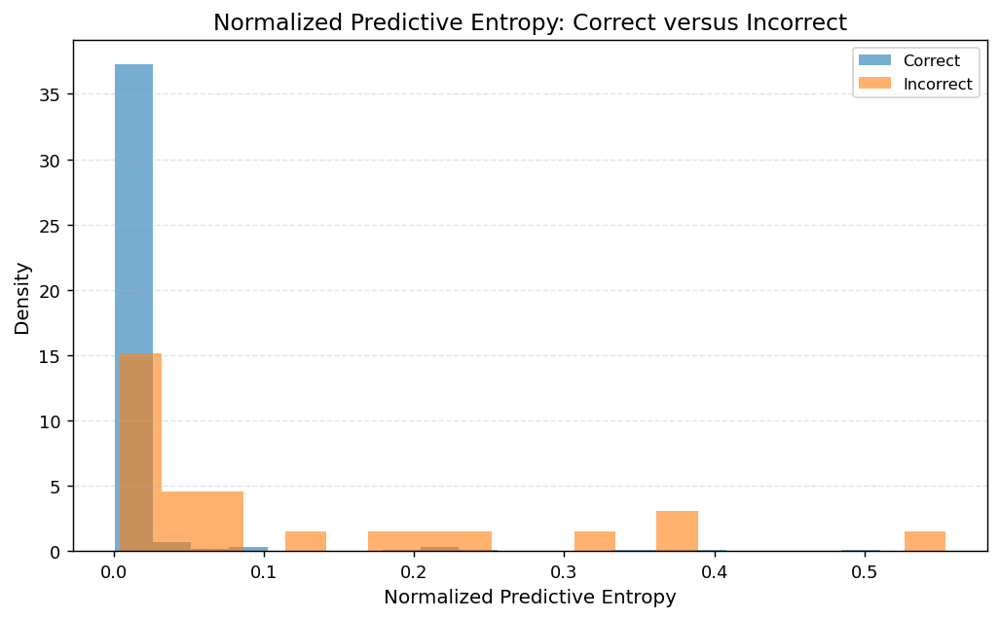

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_normalized_predictive_entropy.png


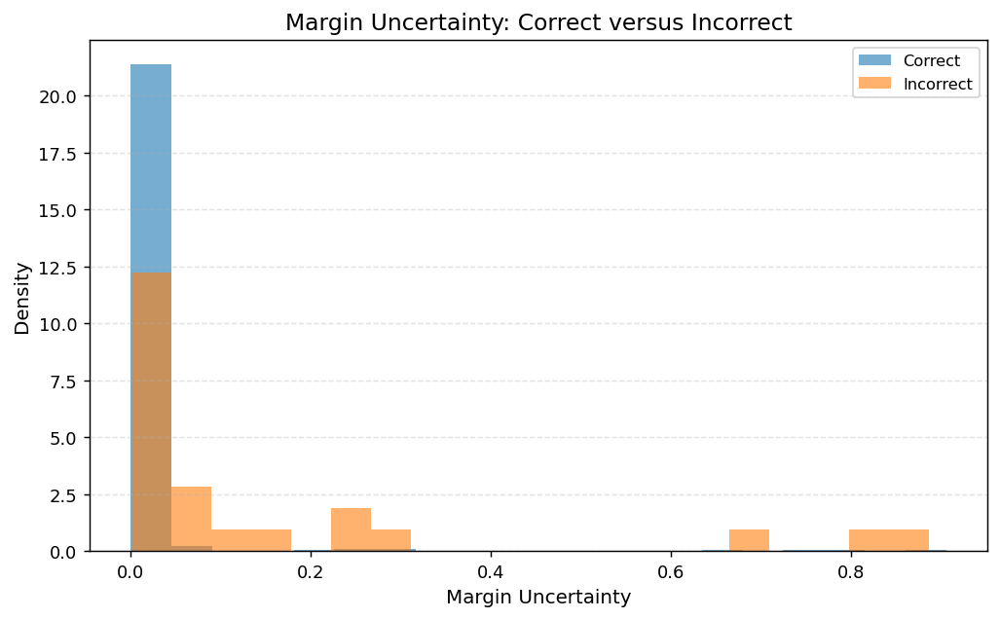

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_margin_uncertainty.png


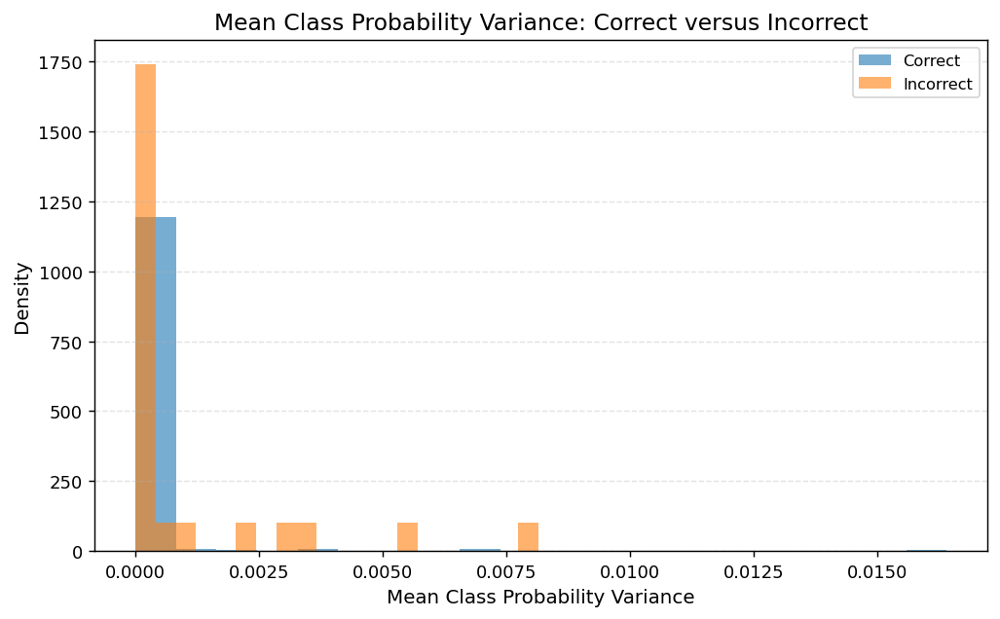

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_mean_class_probability_variance.png


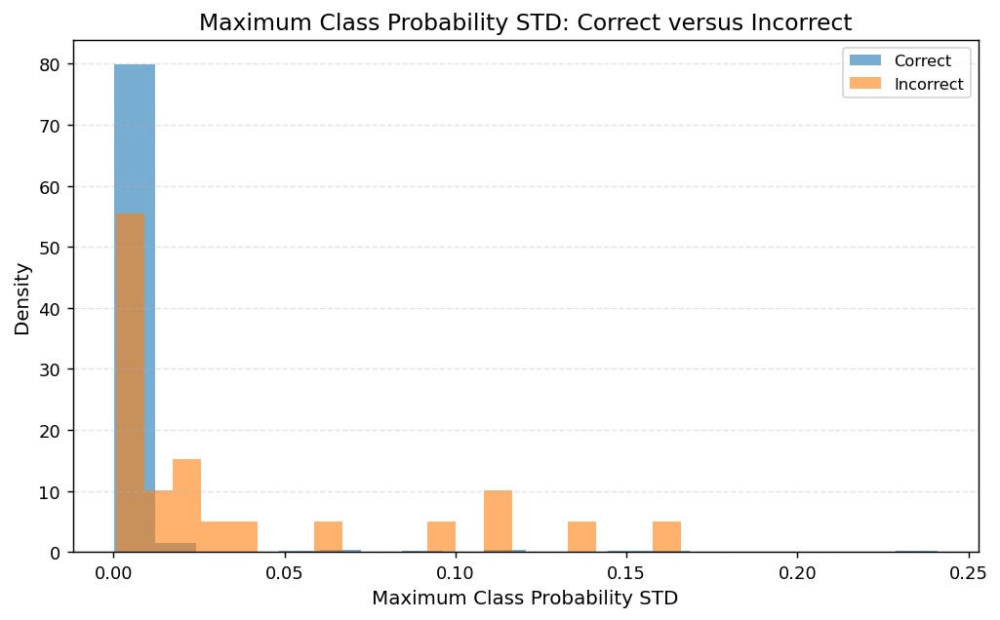

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_maximum_class_probability_std.png


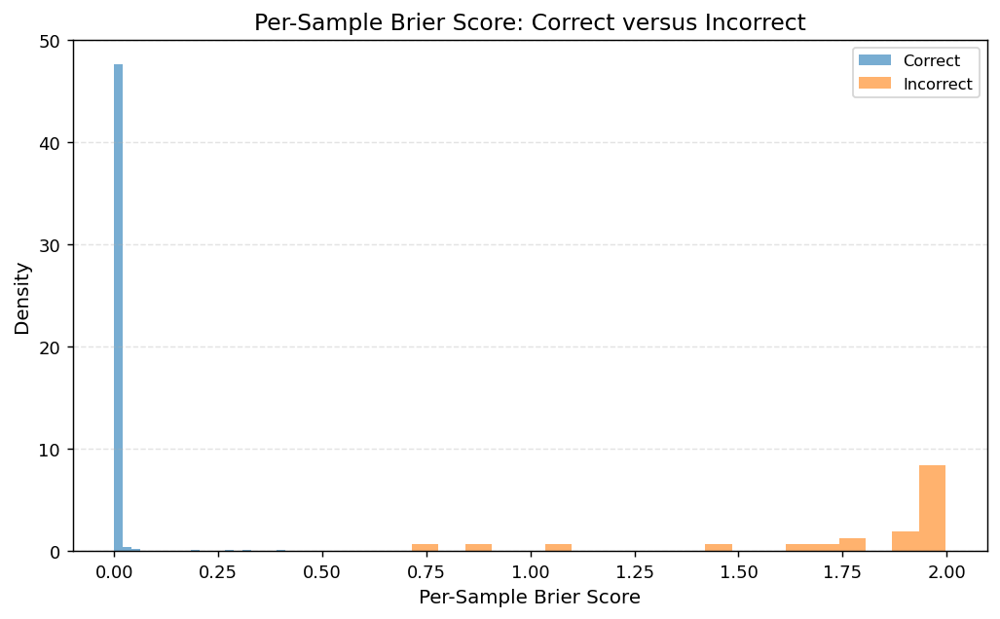

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_per_sample_brier_score.png


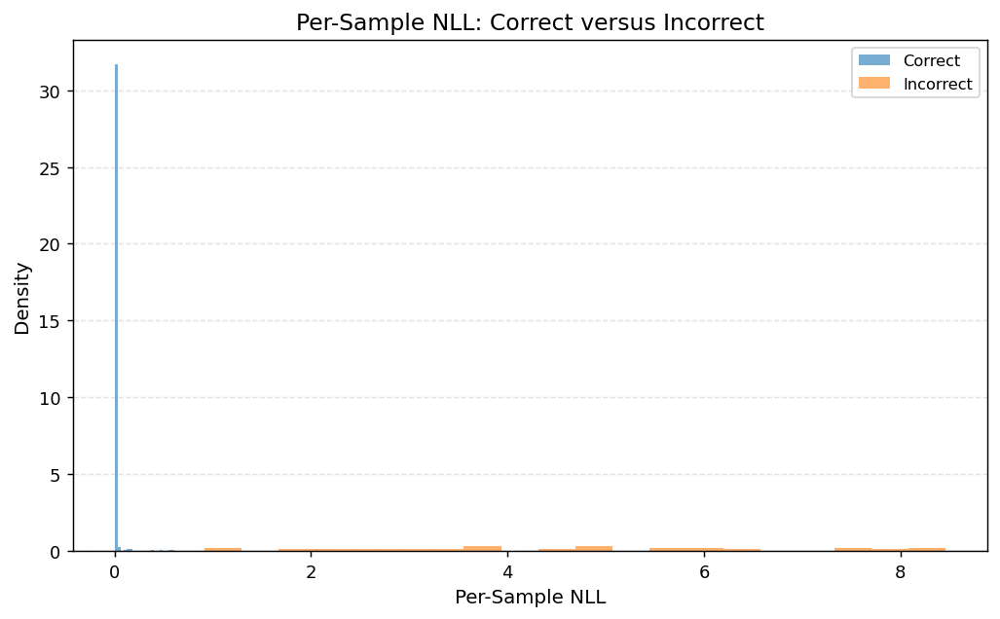

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_distribution_per_sample_nll.png


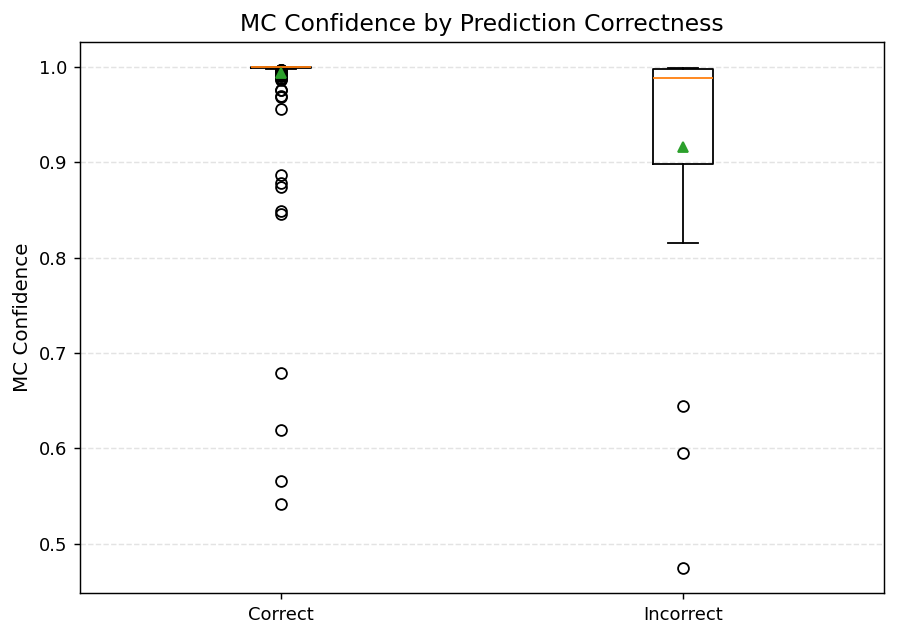

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_mc_confidence.png


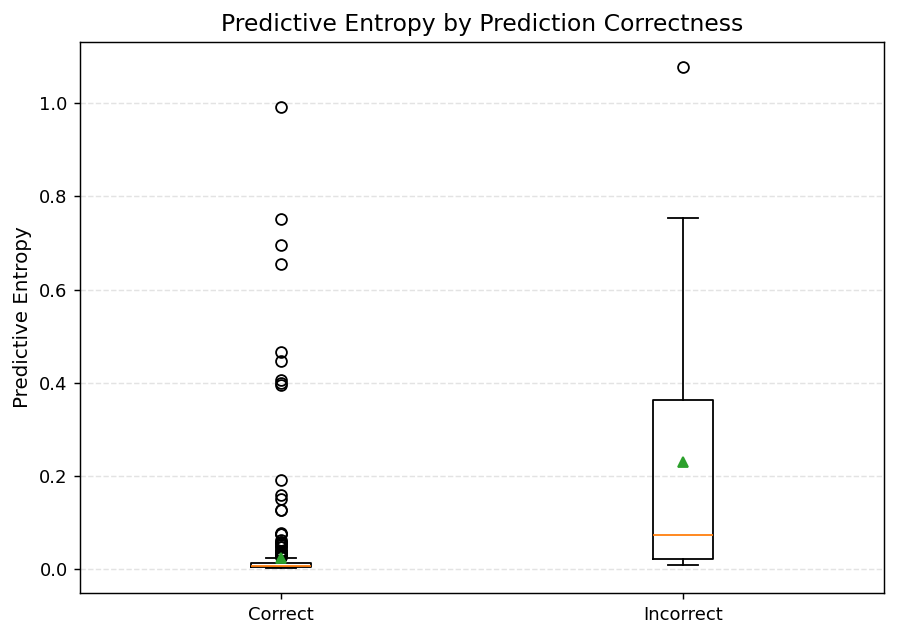

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_predictive_entropy.png


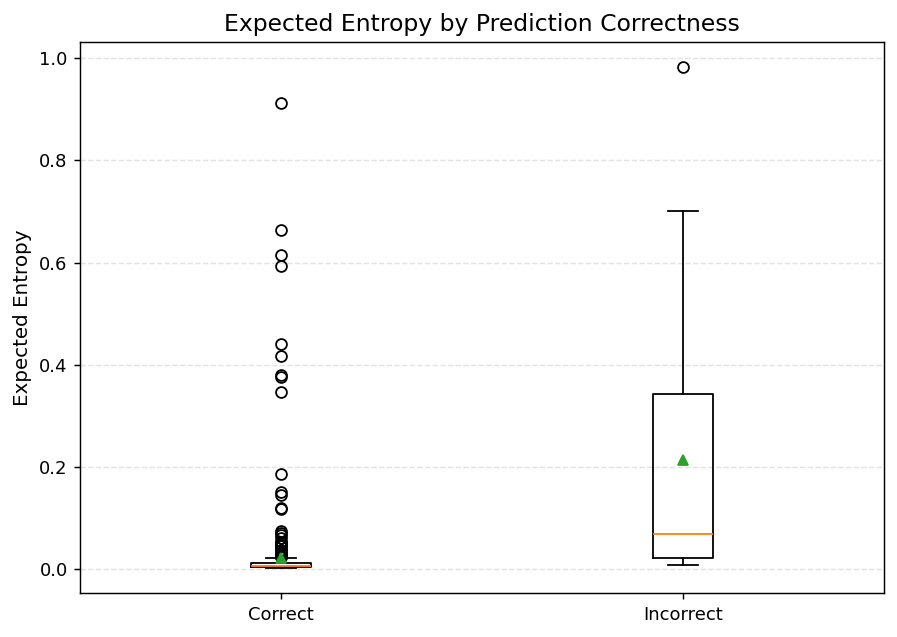

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_expected_entropy.png


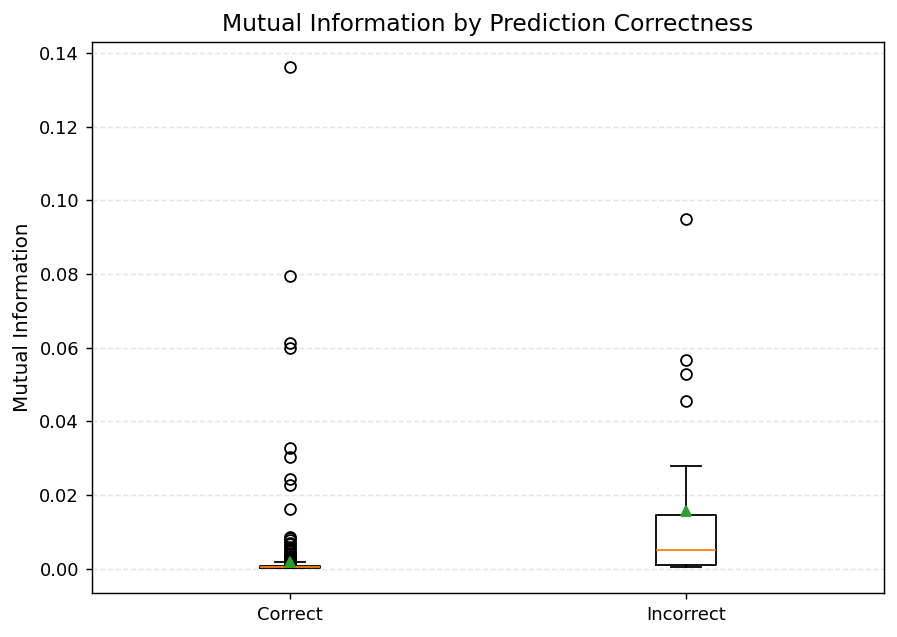

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_mutual_information.png


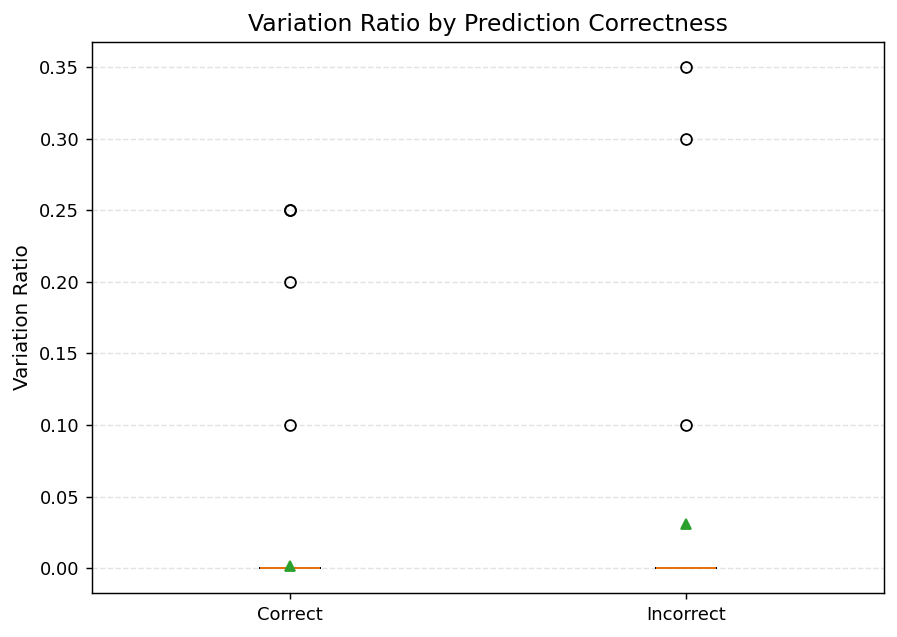

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_variation_ratio.png


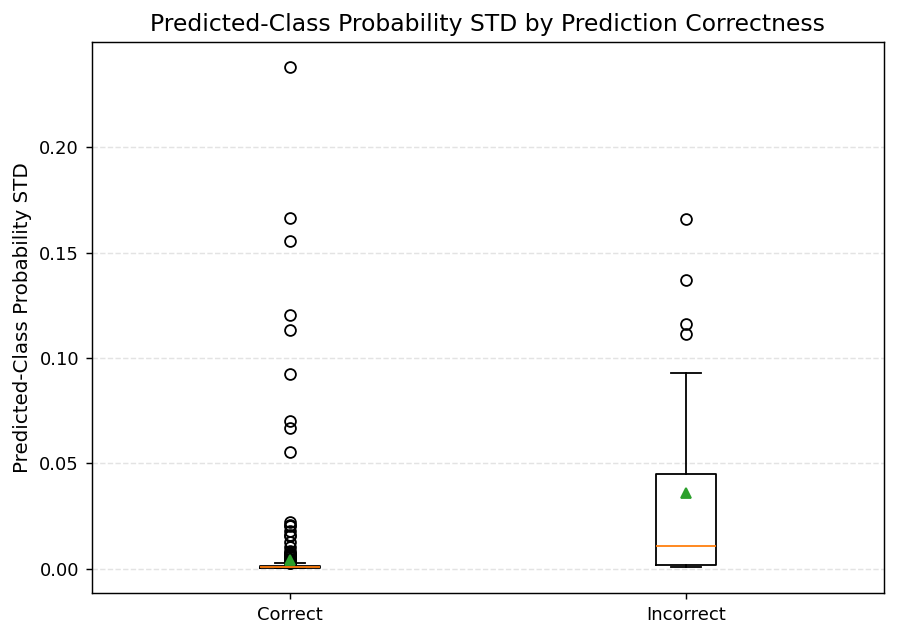

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_predicted_class_probability_std.png


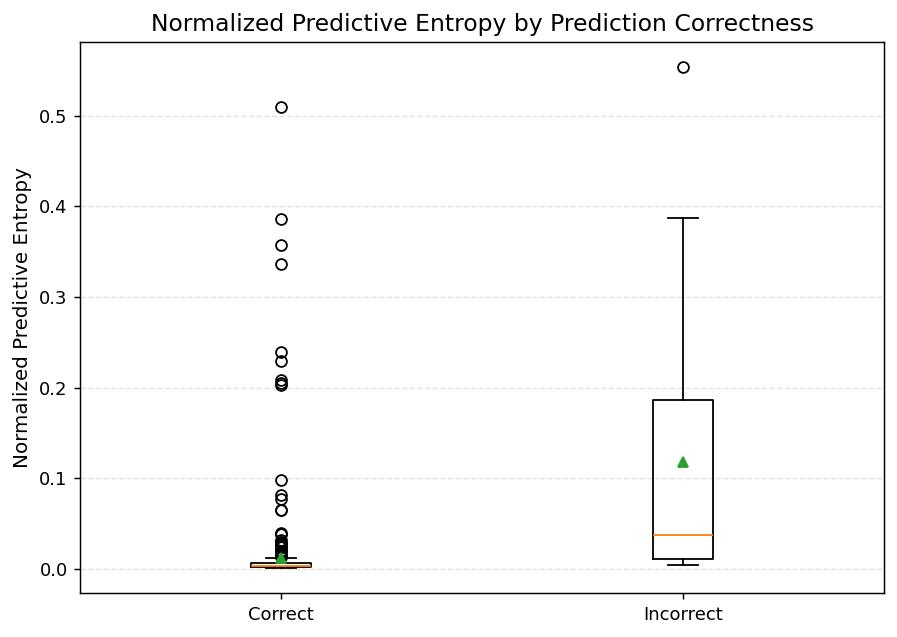

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_normalized_predictive_entropy.png


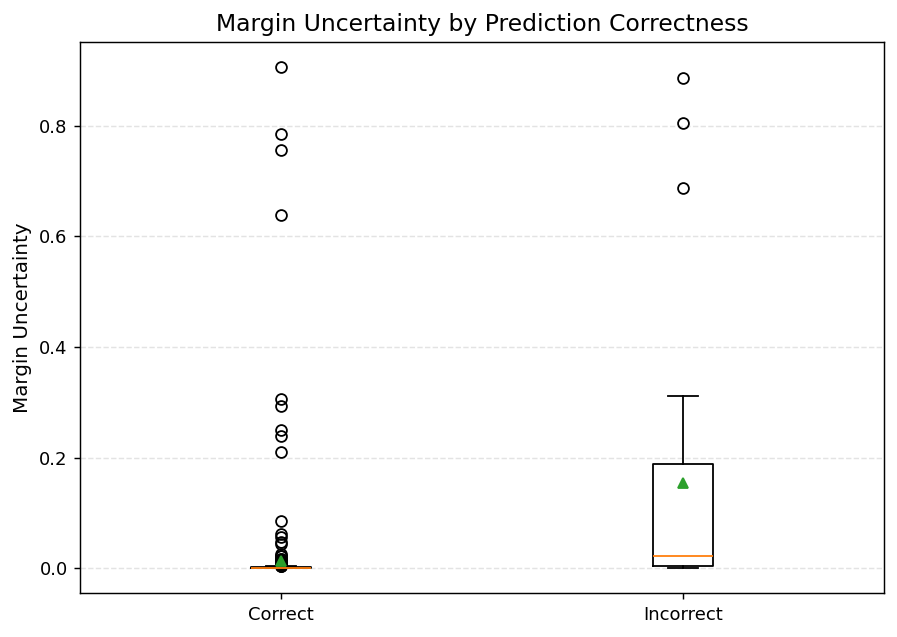

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_margin_uncertainty.png


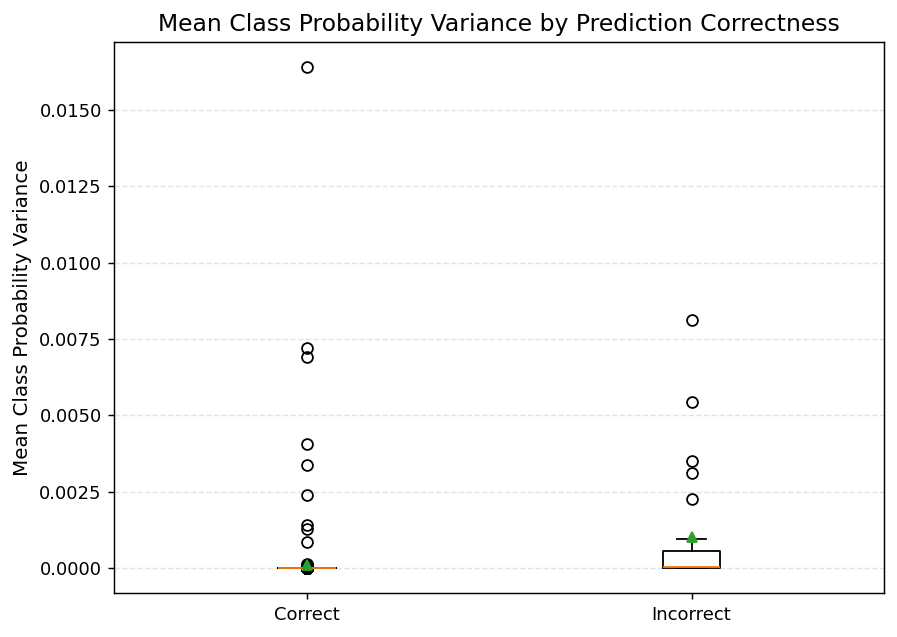

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_mean_class_probability_variance.png


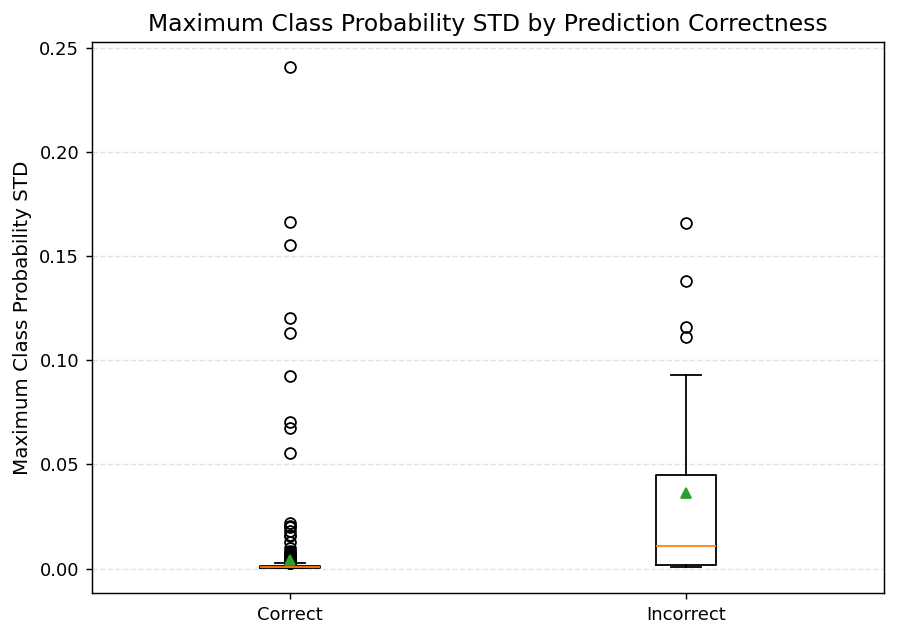

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_maximum_class_probability_std.png


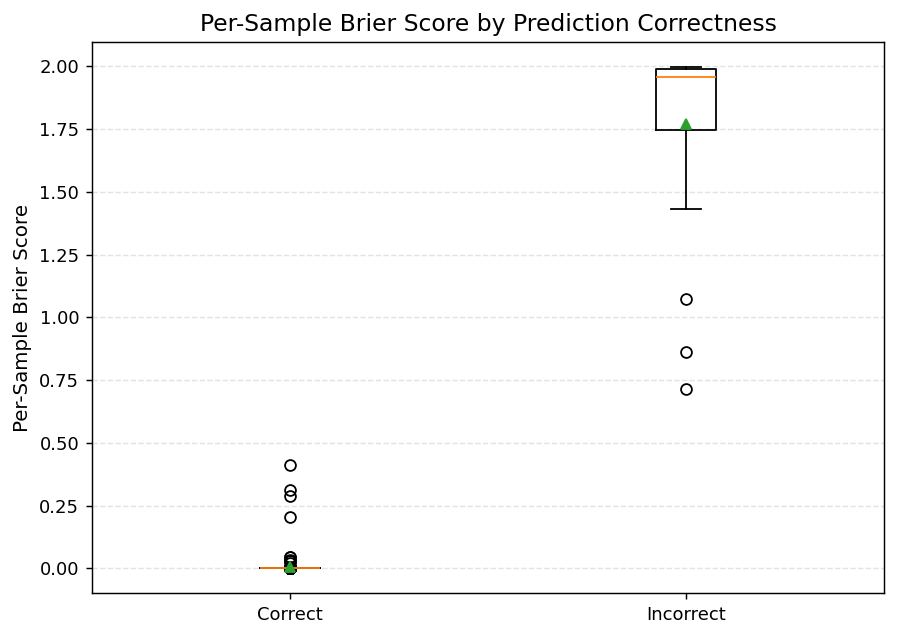

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_per_sample_brier_score.png


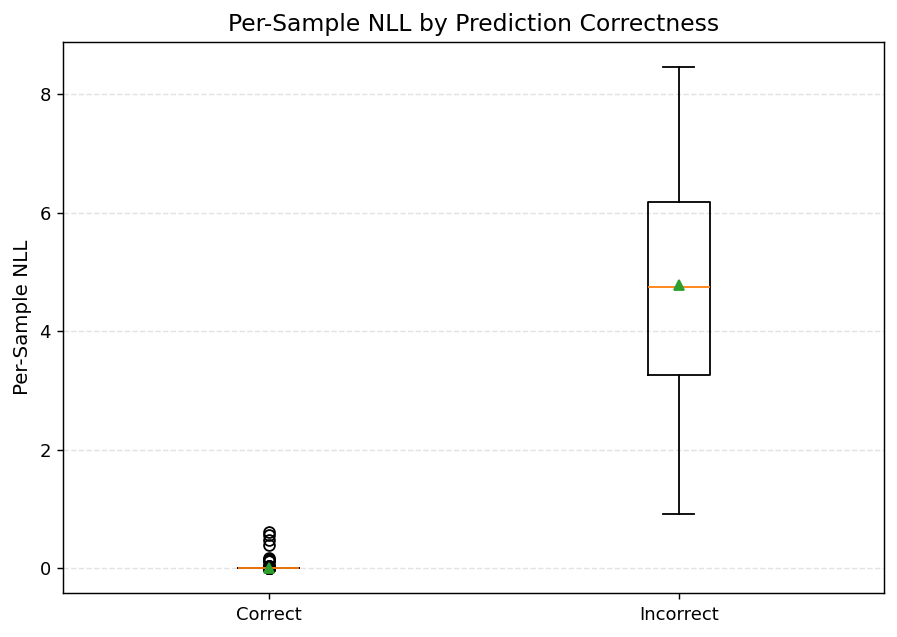

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_boxplot_per_sample_nll.png


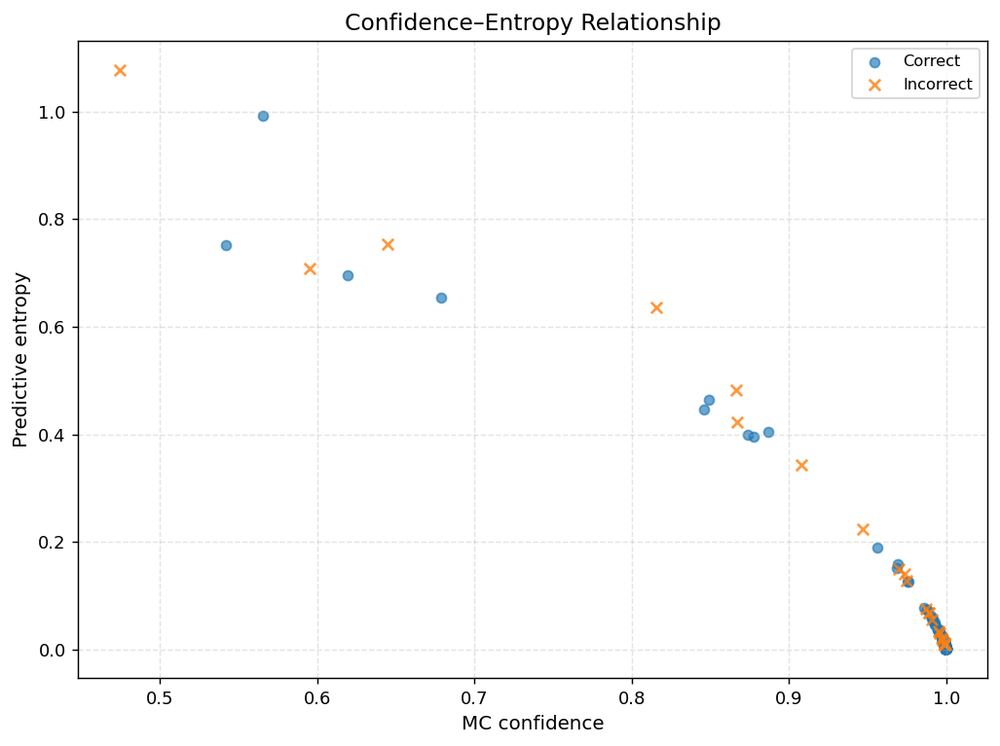

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/confidence_vs_predictive_entropy.png


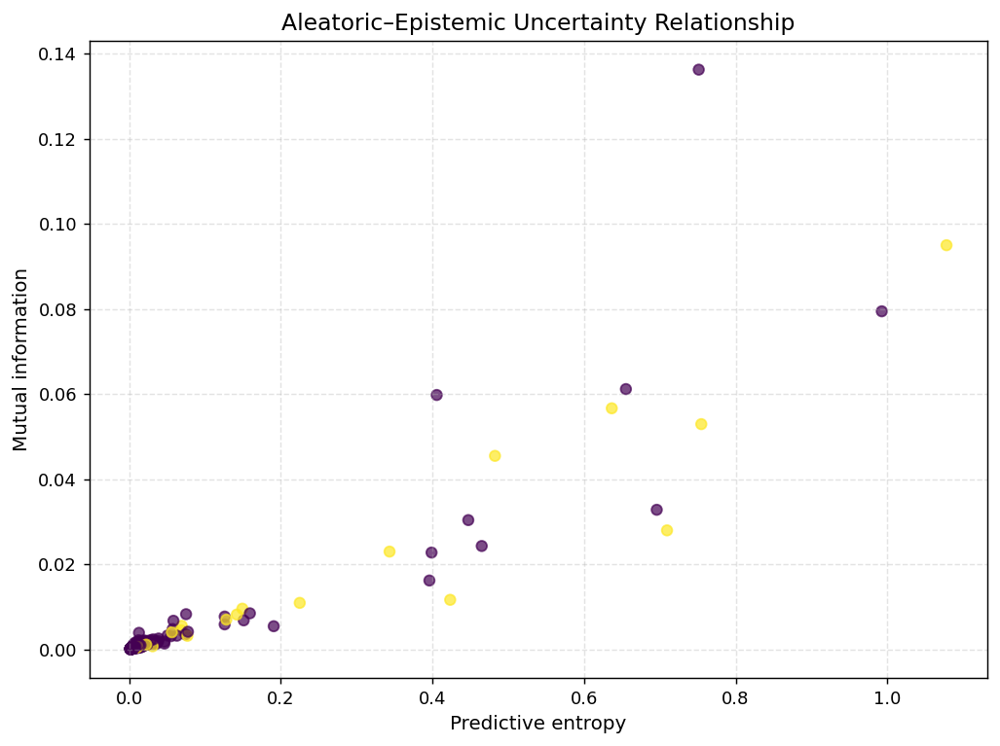

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/predictive_entropy_vs_mutual_information.png


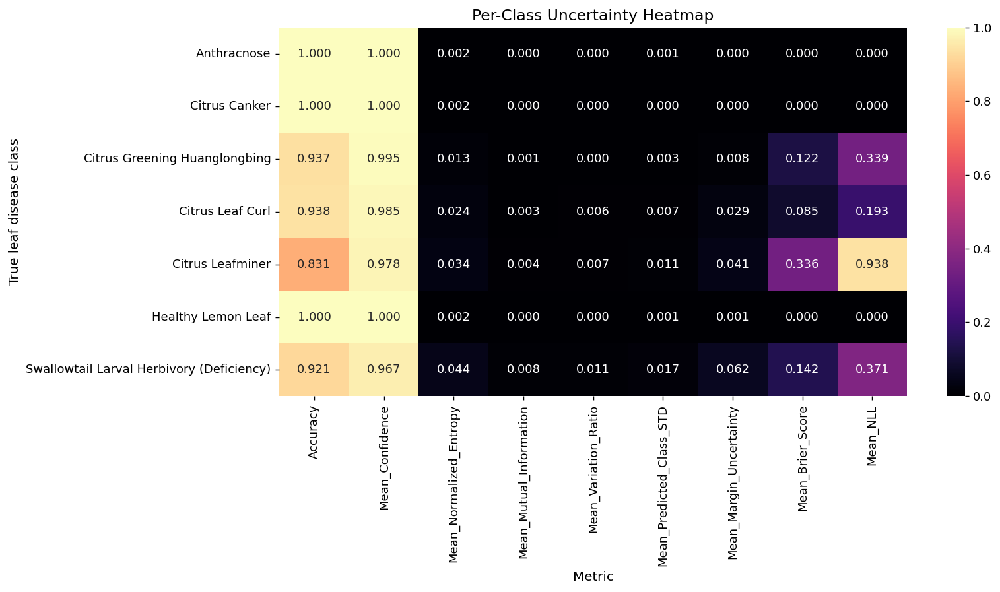

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/per_class_uncertainty_heatmap.png


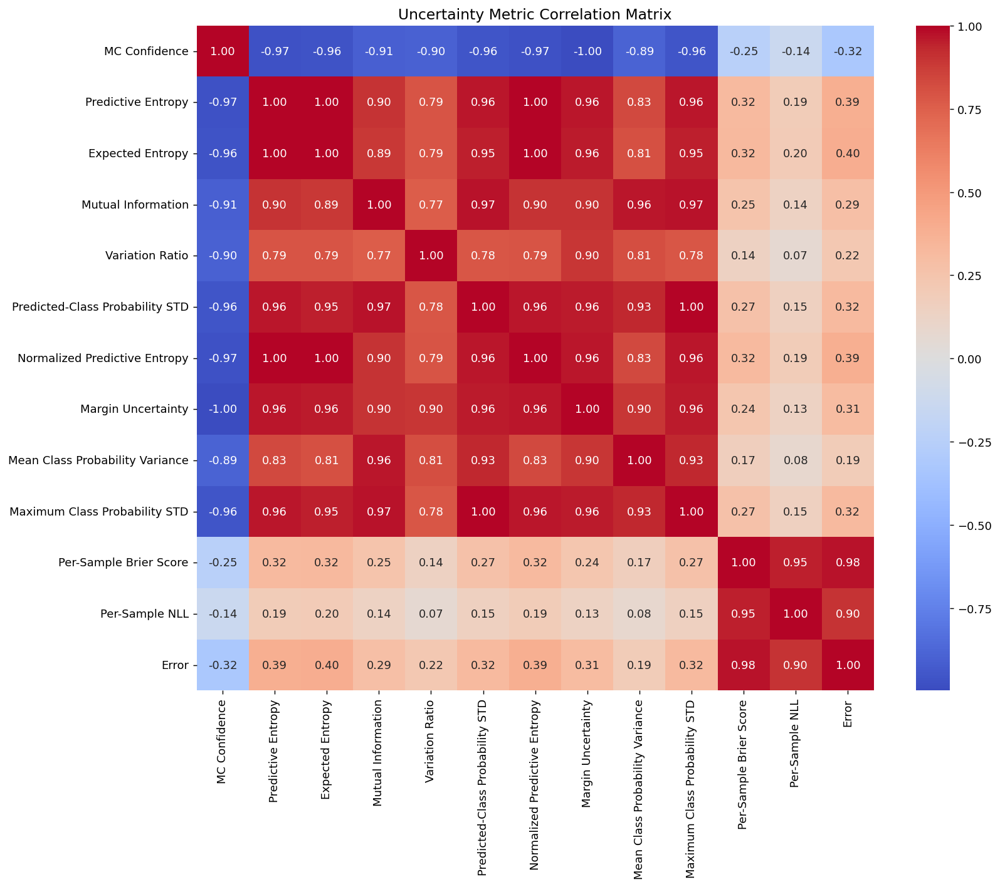

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/uncertainty_metric_correlation.png


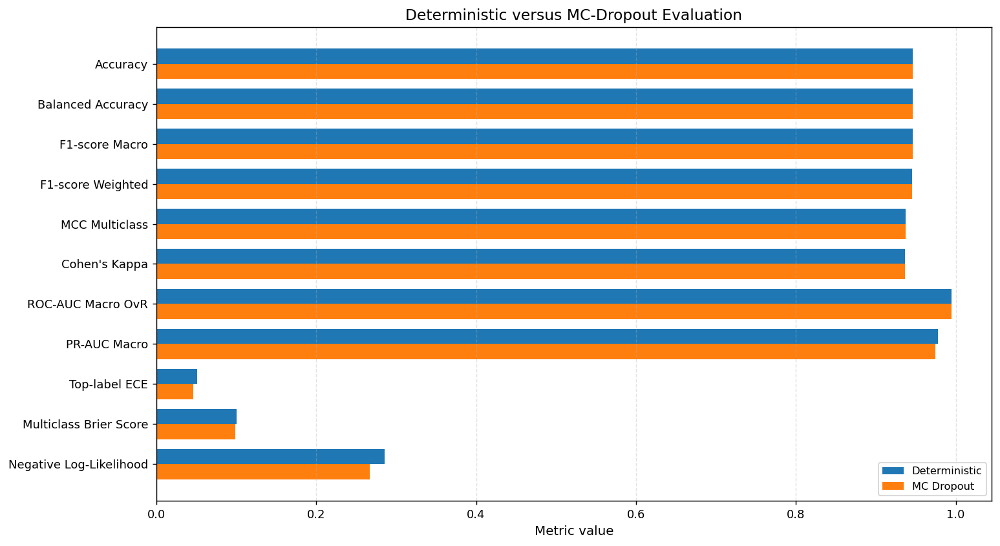

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/deterministic_vs_mc_dropout_metrics.png


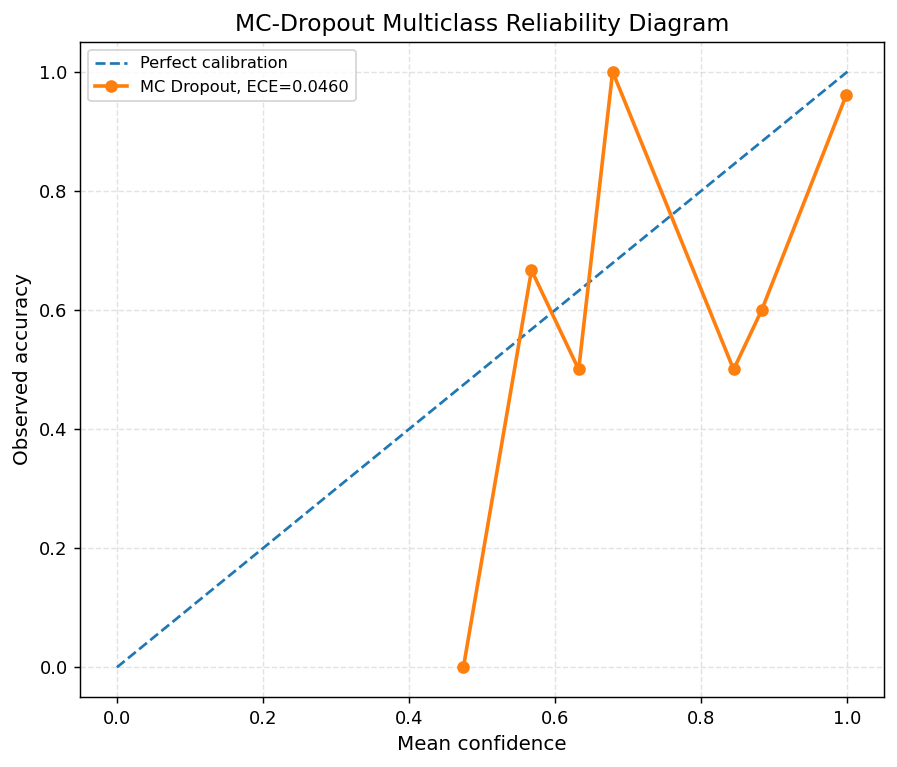

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/mc_dropout_reliability_diagram.png


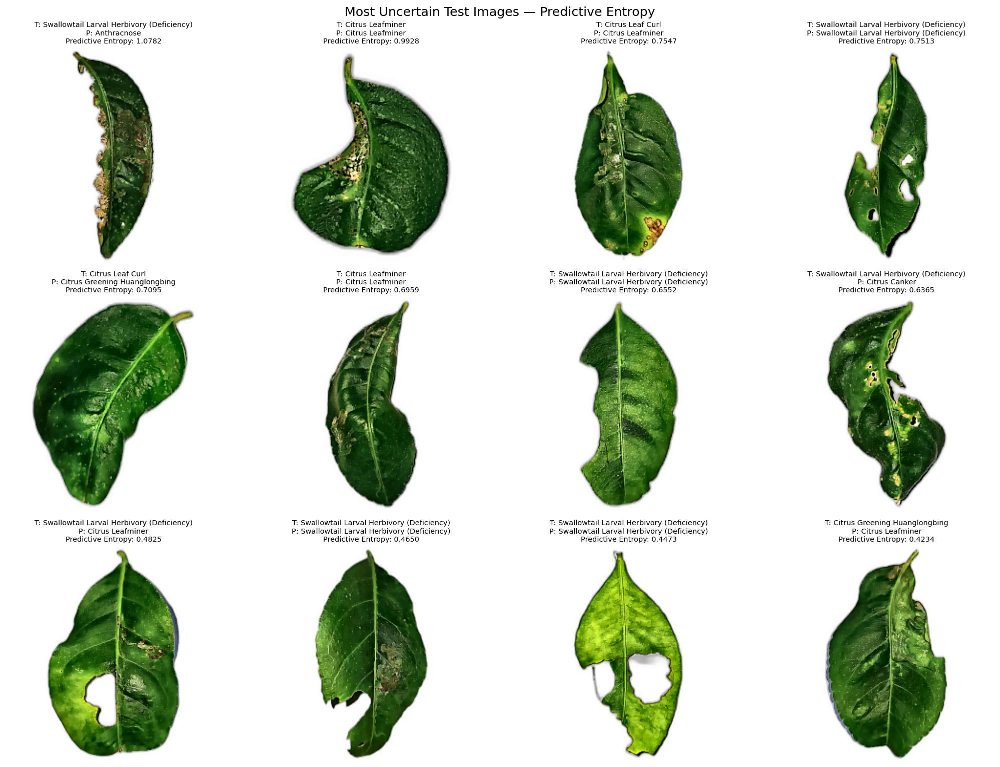

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/most_uncertain_images_predictive_entropy.png


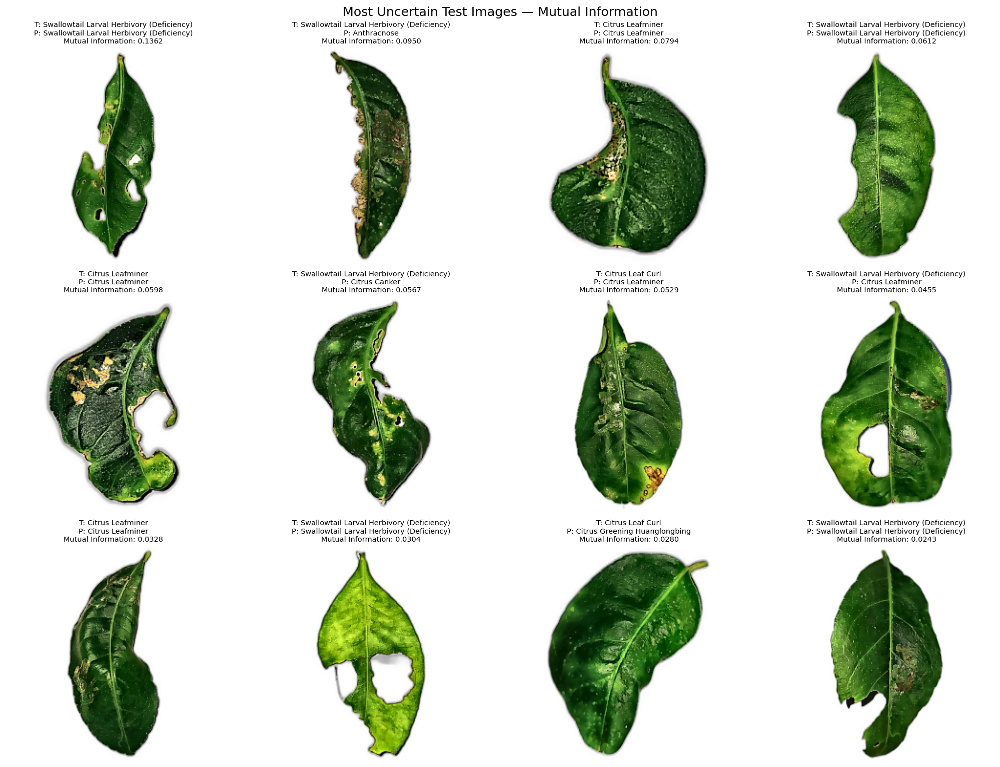

Saved plot: /kaggle/working/lemon_msceca_swin_outputs/plots/most_uncertain_images_mutual_information.png

Resource and efficiency summary


,Model,Backbone,Pretrained Backbone Loaded,Input Size,Classes,Total Parameters,Trainable Parameters,Custom Module Parameters,Parameter Memory FP32 (MB),Checkpoint Size (MB),GFLOPs per Image,Training Time (s),Training Time (min),Inference Time Total (s),Inference Time per Image (s),Throughput (images/s),Peak GPU Memory (MB),Current GPU Memory (MB),RAM Used (MB)
0,Lemon-MSCECA-Swin,swin_tiny_patch4_window7_224.ms_in1k,True,224x224x3,7,28247970,28247970,730152,107.757454,107.84765,9.231583,1959.836267,32.663938,2.49776,0.005638,177.35891,920.279297,686.271973,6224.339844



Final summary


,Item,Value
0,Model,Lemon-MSCECA-Swin
1,Architecture Meaning,Swin-Tiny with custom Multi-Scale Efficient Ch...
2,Backbone,swin_tiny_patch4_window7_224.ms_in1k
3,Training Path,/kaggle/working/papaya_leaf_train_augmented
4,Validation Path,/kaggle/working/papaya_leaf_split/validation
...,...,...
94,RAM Used (MB),6224.339844
95,Saved Model,/kaggle/working/lemon_msceca_swin_outputs/best...
96,Output Directory,/kaggle/working/lemon_msceca_swin_outputs
97,Plot Directory,/kaggle/working/lemon_msceca_swin_outputs/plots



Completed:
- Lemon-MSCECA-Swin training
- Complete multiclass metrics
- Per-class OvR diagnostic metrics
- ROC, PR, calibration, confidence, and entropy plots
- Raw Swin-Tiny vs MSCECA-Swin PCA, t-SNE, and optional UMAP
- Token attention and custom MS-ECA evidence maps
- Misclassification visualization
- Multiclass MC Dropout uncertainty
- Error-detection AUROC/AUPRC for multiple uncertainty scores
- Risk-coverage, AURC, and selective-accuracy analysis
- Correct-vs-incorrect uncertainty distributions and boxplots
- Per-class uncertainty and uncertainty-correlation heatmaps
- Deterministic-vs-MC Dropout comparison
- Uncertainty-ranked test image visualization
- Bootstrap confidence intervals
- Resource and efficiency analysis
- All CSV outputs saved to: /kaggle/working/lemon_msceca_swin_outputs
- All added plots saved to: /kaggle/working/lemon_msceca_swin_outputs/plots
- All added tables saved to: /kaggle/working/lemon_msceca_swin_outputs/tables


In [7]:
# ============================================================
# Lemon-MSCECA-Swin: Multiclass Leaf Disease Classification
# Backbone: Swin Transformer Tiny + Custom Multi-Scale Efficient Channel Attention
# Full training, multiclass evaluation, calibration, uncertainty,
# raw-Swin vs MSCECA-Swin PCA/t-SNE/UMAP, and attention visualization
# ============================================================

# %%
import os
import sys
import time
import math
import copy
import random
import warnings
import subprocess
from contextlib import nullcontext
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.transforms import InterpolationMode
from PIL import Image
from IPython.display import display

try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm

try:
    import seaborn as sns
except ImportError:
    sns = None

try:
    import umap.umap_ as umap
    UMAP_AVAILABLE = True
except ImportError:
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
        import umap.umap_ as umap
        UMAP_AVAILABLE = True
    except Exception:
        UMAP_AVAILABLE = False
        print("UMAP is unavailable. PCA and t-SNE will still run.")

from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    multilabel_confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    jaccard_score,
    hamming_loss,
    zero_one_loss,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    auc,
    top_k_accuracy_score,
    fowlkes_mallows_score,
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)
from scipy.stats import chi2_contingency


# %%
# ============================================================
# Reproducibility and configuration
# ============================================================

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

set_seed()

TRAIN_PATH = "/kaggle/working/papaya_leaf_train_augmented"
VAL_PATH = "/kaggle/working/papaya_leaf_split/validation"
TEST_PATH = "/kaggle/working/papaya_leaf_split/test"

OUTPUT_DIR = Path("/kaggle/working/lemon_msceca_swin_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_DIR = OUTPUT_DIR / "plots"
TABLE_DIR = OUTPUT_DIR / "tables"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "swin_tiny_patch4_window7_224.ms_in1k"
MODEL_SAVE_PATH = OUTPUT_DIR / "best_lemon_msceca_swin.pth"

INPUT_SIZE = 224
EPOCHS = 30
PATIENCE = 5


BATCH_SIZE = 16
BACKBONE_LR = 3e-5
HEAD_LR = 2e-4
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.30
LABEL_SMOOTHING = 0.05
FOCAL_GAMMA = 1.5
WARMUP_EPOCHS = 3
MC_DROPOUT_PASSES = 20
BOOTSTRAP_ITERATIONS = 1000
TSNE_MAX_SAMPLES = 1500
USE_CLASS_WEIGHTS = True

SUPPORTED_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

NUM_WORKERS = min(4, os.cpu_count() if os.cpu_count() is not None else 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"

print("Device:", DEVICE)
print("Training path  :", TRAIN_PATH)
print("Validation path:", VAL_PATH)
print("Testing path   :", TEST_PATH)
print("Output path    :", OUTPUT_DIR)
print("Patience       :", PATIENCE)

print("Plot directory :", PLOT_DIR)
print("Table directory:", TABLE_DIR)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9
})


def print_section(title, width=100, character="="):
    print("\n" + character * width)
    print(title)
    print(character * width)


def save_and_show_figure(figure, filename):
    """
    Save every newly added evaluation figure as PNG and display it.
    """
    output_path = PLOT_DIR / filename
    figure.tight_layout()
    figure.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(figure)
    print("Saved plot:", output_path)


def display_and_save_table(dataframe, filename, title=None, decimals=6):
    """
    Print, display, and save a DataFrame in a consistent format.
    """
    if title is not None:
        print_section(title, character="-")

    display(dataframe.round(decimals))
    output_path = TABLE_DIR / filename
    dataframe.to_csv(output_path, index=False)
    print("Saved table:", output_path)



# %%
# ============================================================
# Dataset validation and transforms
# ============================================================

def validate_class_folder_dataset(path, split_name):
    if not os.path.isdir(path):
        raise FileNotFoundError(f"{split_name} path not found: {path}")

    class_folders = sorted([
        entry.name for entry in Path(path).iterdir() if entry.is_dir()
    ])

    if len(class_folders) < 2:
        raise ValueError(
            f"{split_name} must contain at least two class folders. "
            f"Detected: {class_folders}"
        )

    counts = {}
    for class_name in class_folders:
        class_path = Path(path) / class_name
        count = sum(
            1 for item in class_path.rglob("*")
            if item.is_file() and item.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        counts[class_name] = count

    empty_classes = [name for name, count in counts.items() if count == 0]
    if empty_classes:
        raise ValueError(f"{split_name} has empty class folders: {empty_classes}")

    print(f"\n{split_name} validation passed")
    print("-" * 70)
    for class_name, count in counts.items():
        print(f"{class_name:55s}: {count:5d}")
    print(f"{'Total':55s}: {sum(counts.values()):5d}")

    return class_folders, counts

train_classes_found, train_counts_found = validate_class_folder_dataset(
    TRAIN_PATH, "Training"
)
val_classes_found, val_counts_found = validate_class_folder_dataset(
    VAL_PATH, "Validation"
)
test_classes_found, test_counts_found = validate_class_folder_dataset(
    TEST_PATH, "Testing"
)

if train_classes_found != val_classes_found or train_classes_found != test_classes_found:
    raise ValueError(
        "Train, validation, and test class folders are inconsistent.\n"
        f"Train: {train_classes_found}\n"
        f"Val  : {val_classes_found}\n"
        f"Test : {test_classes_found}"
    )

IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]

# The training directory already contains offline augmentations,
# so no additional geometric or color augmentation is applied here.
train_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (INPUT_SIZE, INPUT_SIZE),
        interpolation=InterpolationMode.BICUBIC
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGE_MEAN, IMAGE_STD)
])

train_dataset = ImageFolder(TRAIN_PATH, transform=train_transform)
val_dataset = ImageFolder(VAL_PATH, transform=eval_transform)
test_dataset = ImageFolder(TEST_PATH, transform=eval_transform)

if (
    train_dataset.class_to_idx != val_dataset.class_to_idx
    or train_dataset.class_to_idx != test_dataset.class_to_idx
):
    raise ValueError(
        "ImageFolder class mappings differ across splits.\n"
        f"Train: {train_dataset.class_to_idx}\n"
        f"Val  : {val_dataset.class_to_idx}\n"
        f"Test : {test_dataset.class_to_idx}"
    )

CLASS_NAMES = train_dataset.classes
CLASS_TO_IDX = train_dataset.class_to_idx
NUM_CLASSES = len(CLASS_NAMES)

def display_name(class_name):
    return (
        class_name.replace("Tomato___", "")
        .replace("Lemon___", "")
        .replace("_", " ")
        .replace("  ", " ")
    )

DISPLAY_CLASS_NAMES = [display_name(name) for name in CLASS_NAMES]

def dataset_counts(dataset):
    labels = np.asarray(dataset.targets)
    return {
        CLASS_NAMES[index]: int(np.sum(labels == index))
        for index in range(NUM_CLASSES)
    }

split_count_df = pd.DataFrame([
    {"Split": "Train", **dataset_counts(train_dataset)},
    {"Split": "Validation", **dataset_counts(val_dataset)},
    {"Split": "Test", **dataset_counts(test_dataset)}
])
split_count_df["Total"] = split_count_df[CLASS_NAMES].sum(axis=1)

print("\nClass mapping")
print(CLASS_TO_IDX)
print("\nImage count table")
display(split_count_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    persistent_workers=NUM_WORKERS > 0
)

train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    persistent_workers=NUM_WORKERS > 0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    persistent_workers=NUM_WORKERS > 0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=AMP_ENABLED,
    persistent_workers=NUM_WORKERS > 0
)


# %%
# ============================================================
# MSCECA-Swin model components
# Swin-Tiny + Custom Multi-Scale Efficient Channel Attention
# ============================================================

def valid_group_count(channels, preferred=16):
    for groups in range(min(preferred, channels), 0, -1):
        if channels % groups == 0:
            return groups
    return 1


def to_bchw(feature, expected_channels):
    """Convert a timm feature tensor from BCHW or BHWC to BCHW."""
    if feature.ndim != 4:
        raise ValueError(f"Expected a 4D feature map, received {feature.shape}")

    if feature.shape[1] == expected_channels:
        return feature

    if feature.shape[-1] == expected_channels:
        return feature.permute(0, 3, 1, 2).contiguous()

    raise ValueError(
        f"Cannot identify channel axis for shape {tuple(feature.shape)} "
        f"with expected channels={expected_channels}"
    )


class ConvNormAct(nn.Module):
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        stride=1,
        padding=1,
        groups=1,
        dilation=1
    ):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=kernel_size,
                stride=stride,
                padding=padding,
                groups=groups,
                dilation=dilation,
                bias=False
            ),
            nn.GroupNorm(valid_group_count(out_channels), out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)


class CustomMultiScaleEfficientChannelAttention(nn.Module):
    """
    Custom Multi-Scale Efficient Channel Attention (MS-ECA).

    This is NOT the standard ECA block. Standard ECA generally applies one
    global-average descriptor followed by one 1-D convolution. This module
    instead uses:

      1. Learnable weighting of three hierarchical Swin feature scales.
      2. Average, maximum, and standard-deviation channel descriptors.
      3. Parallel local channel-interaction branches with kernels 3, 5, and 7.
      4. Input-dependent softmax selection of the channel-kernel branches.
      5. Lightweight depthwise residual refinement after channel reweighting.

    The module avoids a conventional squeeze-and-excitation bottleneck and
    does not instantiate or directly reuse an ECA implementation.
    """

    def __init__(
        self,
        channels,
        num_scales=3,
        channel_kernels=(3, 5, 7),
        dropout=0.10
    ):
        super().__init__()

        if num_scales < 2:
            raise ValueError("Custom MS-ECA requires at least two scales.")

        if any(kernel % 2 == 0 for kernel in channel_kernels):
            raise ValueError("All channel-interaction kernels must be odd.")

        self.channels = channels
        self.num_scales = num_scales
        self.channel_kernels = tuple(channel_kernels)

        # A shared scale scorer receives three global statistics from each
        # projected Swin stage. Softmax makes the scale contributions sum to 1.
        scale_hidden = max(8, num_scales * 2)
        self.scale_score = nn.Sequential(
            nn.LayerNorm(3),
            nn.Linear(3, scale_hidden),
            nn.GELU(),
            nn.Linear(scale_hidden, 1)
        )

        # Each branch performs local cross-channel interaction over the
        # concatenated average, maximum, and standard-deviation descriptors.
        self.channel_branches = nn.ModuleList([
            nn.Conv1d(
                in_channels=3,
                out_channels=1,
                kernel_size=kernel,
                padding=kernel // 2,
                bias=False
            )
            for kernel in self.channel_kernels
        ])

        # Select the most useful channel receptive field for each image.
        self.kernel_selector = nn.Sequential(
            nn.LayerNorm(3),
            nn.Linear(3, max(8, len(self.channel_kernels) * 2)),
            nn.GELU(),
            nn.Linear(
                max(8, len(self.channel_kernels) * 2),
                len(self.channel_kernels)
            )
        )

        # Lightweight lesion-texture refinement. Depthwise convolution keeps
        # the additional parameter count small.
        self.refine = nn.Sequential(
            nn.Conv2d(
                channels,
                channels,
                kernel_size=3,
                padding=1,
                groups=channels,
                bias=False
            ),
            nn.GroupNorm(valid_group_count(channels), channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, kernel_size=1, bias=False),
            nn.GroupNorm(valid_group_count(channels), channels),
            nn.GELU(),
            nn.Dropout2d(dropout)
        )

        self.residual_scale = nn.Parameter(torch.tensor(0.50))

    @staticmethod
    def _channel_descriptors(feature):
        average_descriptor = F.adaptive_avg_pool2d(
            feature, output_size=1
        ).flatten(1)

        maximum_descriptor = F.adaptive_max_pool2d(
            feature, output_size=1
        ).flatten(1)

        standard_deviation_descriptor = feature.flatten(2).std(
            dim=2,
            unbiased=False
        )

        return (
            average_descriptor,
            maximum_descriptor,
            standard_deviation_descriptor
        )

    def forward(self, features):
        if len(features) != self.num_scales:
            raise ValueError(
                f"Expected {self.num_scales} aligned feature scales, "
                f"received {len(features)}."
            )

        reference_shape = features[0].shape
        for index, feature in enumerate(features):
            if feature.shape != reference_shape:
                raise ValueError(
                    "All custom MS-ECA inputs must have the same shape. "
                    f"Scale 0={reference_shape}, scale {index}={feature.shape}."
                )

        # ----------------------------------------------------
        # 1. Adaptive hierarchical-scale weighting
        # ----------------------------------------------------
        scale_statistics = []

        for feature in features:
            average, maximum, standard_deviation = (
                self._channel_descriptors(feature)
            )

            scale_statistics.append(torch.stack([
                average.mean(dim=1),
                maximum.mean(dim=1),
                standard_deviation.mean(dim=1)
            ], dim=1))

        scale_statistics = torch.stack(
            scale_statistics,
            dim=1
        )  # B x S x 3

        scale_logits = self.scale_score(
            scale_statistics
        ).squeeze(-1)  # B x S

        scale_attention = torch.softmax(
            scale_logits,
            dim=1
        )

        fused_feature = torch.zeros_like(features[0])

        for scale_index, feature in enumerate(features):
            weight = scale_attention[:, scale_index].view(-1, 1, 1, 1)
            fused_feature = fused_feature + weight * feature

        # ----------------------------------------------------
        # 2. Multi-statistic channel description
        # ----------------------------------------------------
        average, maximum, standard_deviation = (
            self._channel_descriptors(fused_feature)
        )

        descriptor = torch.stack([
            average,
            maximum,
            standard_deviation
        ], dim=1)  # B x 3 x C

        # ----------------------------------------------------
        # 3. Multi-kernel local channel interaction
        # ----------------------------------------------------
        branch_logits = torch.stack([
            branch(descriptor).squeeze(1)
            for branch in self.channel_branches
        ], dim=1)  # B x K x C

        selector_statistics = descriptor.mean(dim=2)  # B x 3
        kernel_attention = torch.softmax(
            self.kernel_selector(selector_statistics),
            dim=1
        )  # B x K

        channel_logits = torch.sum(
            branch_logits * kernel_attention.unsqueeze(-1),
            dim=1
        )

        channel_attention = torch.sigmoid(
            channel_logits
        ).unsqueeze(-1).unsqueeze(-1)  # B x C x 1 x 1

        # ----------------------------------------------------
        # 4. Residual channel refinement
        # ----------------------------------------------------
        attended_feature = fused_feature * channel_attention
        refined_feature = self.refine(attended_feature)

        output = fused_feature + torch.tanh(
            self.residual_scale
        ) * refined_feature

        # A normalized lesion-evidence map is returned only for qualitative
        # visualization. It is not a separate spatial-attention gate.
        spatial_evidence = torch.mean(
            torch.abs(attended_feature),
            dim=1,
            keepdim=True
        )

        evidence_minimum = spatial_evidence.amin(
            dim=(2, 3),
            keepdim=True
        )
        evidence_maximum = spatial_evidence.amax(
            dim=(2, 3),
            keepdim=True
        )

        spatial_evidence = (
            spatial_evidence - evidence_minimum
        ) / (
            evidence_maximum - evidence_minimum + 1e-8
        )

        return (
            output,
            spatial_evidence,
            channel_attention,
            scale_attention,
            kernel_attention
        )


class LeafTokenAttention(nn.Module):
    """Softmax token attention over the final Swin spatial tokens."""

    def __init__(self, feature_dim, reduction=4, dropout=0.30):
        super().__init__()
        hidden = max(feature_dim // reduction, 32)

        self.score_net = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1)
        )

        self.output_norm = nn.LayerNorm(feature_dim)
        self.residual_scale = nn.Parameter(torch.tensor(1.0))

    def forward(self, tokens):
        token_logits = self.score_net(tokens).squeeze(-1)
        token_weights = torch.softmax(token_logits, dim=1)

        weighted_feature = torch.sum(
            tokens * token_weights.unsqueeze(-1),
            dim=1
        )

        mean_feature = torch.mean(tokens, dim=1)

        output = self.output_norm(
            mean_feature + self.residual_scale * weighted_feature
        )

        return output, token_weights


class MSCECASwinTiny(nn.Module):
    """
    MSCECA-Swin-Tiny combines:

      1. The final three hierarchical Swin-Tiny feature stages.
      2. Custom adaptive multi-scale fusion.
      3. Custom multi-statistic, multi-kernel channel attention.
      4. Final-stage token attention.
      5. Learnable global-local interaction fusion.
    """

    def __init__(
        self,
        num_classes,
        model_name=MODEL_NAME,
        fusion_dim=256,
        dropout=DROPOUT_RATE,
        pretrained=True
    ):
        super().__init__()

        self.requested_model_name = model_name
        self.model_name = model_name
        self.pretrained_loaded = False

        self.backbone = self._build_backbone(model_name, pretrained)
        all_channels = list(self.backbone.feature_info.channels())

        if len(all_channels) < 3:
            raise ValueError(
                f"Swin feature backbone returned only {len(all_channels)} stages."
            )

        self.selected_channels = all_channels[-3:]
        self.fusion_dim = fusion_dim

        self.stage_projections = nn.ModuleList([
            nn.Sequential(
                nn.Conv2d(channels, fusion_dim, kernel_size=1, bias=False),
                nn.GroupNorm(valid_group_count(fusion_dim), fusion_dim),
                nn.GELU()
            )
            for channels in self.selected_channels
        ])

        self.multi_scale_channel_attention = (
            CustomMultiScaleEfficientChannelAttention(
                channels=fusion_dim,
                num_scales=len(self.selected_channels),
                channel_kernels=(3, 5, 7),
                dropout=dropout / 2
            )
        )

        self.token_attention = LeafTokenAttention(
            fusion_dim,
            reduction=4,
            dropout=dropout
        )

        self.local_norm = nn.LayerNorm(fusion_dim)
        self.global_norm = nn.LayerNorm(fusion_dim)

        self.fusion_gate = nn.Sequential(
            nn.Linear(fusion_dim * 3, fusion_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(fusion_dim, fusion_dim),
            nn.Sigmoid()
        )

        self.interaction_scale = nn.Parameter(torch.tensor(0.25))
        self.output_norm = nn.LayerNorm(fusion_dim)

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, fusion_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(fusion_dim // 2, num_classes)
        )

    def _build_backbone(self, requested_name, pretrained):
        candidates = [
            requested_name,
            "swin_tiny_patch4_window7_224.ms_in1k",
            "swin_tiny_patch4_window7_224.in1k",
            "swin_tiny_patch4_window7_224"
        ]

        errors = []
        seen = set()

        for candidate in candidates:
            if candidate in seen:
                continue
            seen.add(candidate)

            if pretrained:
                try:
                    backbone = timm.create_model(
                        candidate,
                        pretrained=True,
                        features_only=True
                    )
                    self.model_name = candidate
                    self.pretrained_loaded = True
                    print(f"Loaded pretrained feature backbone: {candidate}")
                    return backbone
                except Exception as error:
                    errors.append(f"{candidate}, pretrained=True: {error}")

            try:
                backbone = timm.create_model(
                    candidate,
                    pretrained=False,
                    features_only=True
                )
                self.model_name = candidate
                self.pretrained_loaded = False
                print(f"Loaded randomly initialized feature backbone: {candidate}")
                return backbone
            except Exception as error:
                errors.append(f"{candidate}, pretrained=False: {error}")

        raise RuntimeError(
            "Could not create a Swin Transformer Tiny feature backbone.\n"
            + "\n".join(errors)
        )

    def extract_backbone_maps(self, x):
        features = self.backbone(x)
        selected = features[-3:]

        maps = [
            to_bchw(feature, channels)
            for feature, channels in zip(selected, self.selected_channels)
        ]
        return maps

    def forward_features(self, x):
        feature_maps = self.extract_backbone_maps(x)

        projected = [
            projection(feature)
            for projection, feature in zip(
                self.stage_projections,
                feature_maps
            )
        ]

        reference_size = projected[0].shape[-2:]

        aligned = [
            feature if feature.shape[-2:] == reference_size
            else F.interpolate(
                feature,
                size=reference_size,
                mode="bilinear",
                align_corners=False
            )
            for feature in projected
        ]

        (
            local_map,
            spatial_attention,
            channel_attention,
            scale_attention,
            kernel_attention
        ) = self.multi_scale_channel_attention(aligned)

        local_average = F.adaptive_avg_pool2d(local_map, 1).flatten(1)
        local_maximum = F.adaptive_max_pool2d(local_map, 1).flatten(1)
        local_feature = self.local_norm(local_average + local_maximum)

        final_map = projected[-1]
        _, _, height, width = final_map.shape
        tokens = final_map.flatten(2).transpose(1, 2)

        global_feature, token_attention = self.token_attention(tokens)
        global_feature = self.global_norm(global_feature)

        interaction = global_feature * local_feature

        fusion_input = torch.cat([
            global_feature,
            local_feature,
            interaction
        ], dim=1)

        gate = self.fusion_gate(fusion_input)

        fused_feature = (
            gate * global_feature
            + (1.0 - gate) * local_feature
            + self.interaction_scale * interaction
        )

        fused_feature = self.output_norm(fused_feature)

        details = {
            "embedding": fused_feature,
            "global_feature": global_feature,
            "local_feature": local_feature,
            "fusion_gate": gate,
            "token_attention": token_attention,
            "token_grid": (height, width),
            "spatial_attention": spatial_attention,
            "channel_attention": channel_attention,
            "scale_attention": scale_attention,
            "kernel_attention": kernel_attention
        }

        return fused_feature, details

    def forward(self, x, return_details=False):
        embedding, details = self.forward_features(x)
        logits = self.classifier(embedding)

        if return_details:
            details["logits"] = logits
            return details

        return logits


# %%
# ============================================================
# Build model and preserve a raw backbone copy
# ============================================================

model = MSCECASwinTiny(
    num_classes=NUM_CLASSES,
    model_name=MODEL_NAME,
    fusion_dim=256,
    dropout=DROPOUT_RATE,
    pretrained=True
)

# This frozen copy provides raw Swin-Tiny embeddings for comparison.
raw_backbone = copy.deepcopy(model.backbone).eval()
raw_channels = list(raw_backbone.feature_info.channels())
RAW_MODEL_LABEL = (
    "Raw pretrained Swin-Tiny"
    if model.pretrained_loaded
    else "Raw initialized Swin-Tiny"
)

for parameter in raw_backbone.parameters():
    parameter.requires_grad = False

model = model.to(DEVICE)


def count_parameters(module):
    total = sum(parameter.numel() for parameter in module.parameters())
    trainable = sum(
        parameter.numel()
        for parameter in module.parameters()
        if parameter.requires_grad
    )
    return total, trainable


total_parameters, trainable_parameters = count_parameters(model)
backbone_parameters, backbone_trainable = count_parameters(model.backbone)
custom_parameters = total_parameters - backbone_parameters

parameter_df = pd.DataFrame([
    {
        "Component": "Swin-Tiny backbone",
        "Total Parameters": backbone_parameters,
        "Trainable Parameters": backbone_trainable
    },
    {
        "Component": "Custom MSCECA-Swin modules",
        "Total Parameters": custom_parameters,
        "Trainable Parameters": trainable_parameters - backbone_trainable
    },
    {
        "Component": "Complete model",
        "Total Parameters": total_parameters,
        "Trainable Parameters": trainable_parameters
    }
])
parameter_df["FP32 Parameter Memory (MB)"] = (
    parameter_df["Total Parameters"] * 4 / (1024 ** 2)
)

print("\nParameter summary")
display(parameter_df)


# %%
# ============================================================
# Effective-number class weights and focal loss
# ============================================================

def effective_number_weights(targets, num_classes, beta=0.999):
    counts = np.bincount(targets, minlength=num_classes).astype(np.float64)
    effective_numbers = 1.0 - np.power(beta, counts)
    weights = (1.0 - beta) / np.maximum(effective_numbers, 1e-12)
    weights = weights / weights.sum() * num_classes
    return counts, torch.tensor(weights, dtype=torch.float32)

train_class_counts, class_weights_cpu = effective_number_weights(
    np.asarray(train_dataset.targets),
    NUM_CLASSES
)

class_weights = (
    class_weights_cpu.to(DEVICE)
    if USE_CLASS_WEIGHTS
    else None
)

weight_df = pd.DataFrame({
    "Class": DISPLAY_CLASS_NAMES,
    "Training Images": train_class_counts.astype(int),
    "Effective Weight": class_weights_cpu.numpy()
})

print("\nClass weights")
display(weight_df)


class MulticlassFocalLoss(nn.Module):
    def __init__(
        self,
        class_weights=None,
        gamma=1.5,
        label_smoothing=0.05
    ):
        super().__init__()
        self.class_weights = class_weights
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            weight=self.class_weights,
            reduction="none",
            label_smoothing=self.label_smoothing
        )

        probabilities = torch.softmax(logits, dim=1)
        target_probabilities = probabilities.gather(
            1,
            targets.unsqueeze(1)
        ).squeeze(1)

        focal_factor = torch.pow(
            1.0 - target_probabilities,
            self.gamma
        )

        return torch.mean(focal_factor * cross_entropy)


criterion = MulticlassFocalLoss(
    class_weights=class_weights,
    gamma=FOCAL_GAMMA,
    label_smoothing=LABEL_SMOOTHING
)


# %%
# ============================================================
# Optimizer, scheduler, EMA, and mixed precision
# ============================================================

backbone_parameter_ids = {
    id(parameter) for parameter in model.backbone.parameters()
}

head_parameters = [
    parameter for parameter in model.parameters()
    if id(parameter) not in backbone_parameter_ids
]

optimizer = optim.AdamW([
    {
        "params": model.backbone.parameters(),
        "lr": BACKBONE_LR
    },
    {
        "params": head_parameters,
        "lr": HEAD_LR
    }
], weight_decay=WEIGHT_DECAY)


def lr_multiplier(epoch):
    if epoch < WARMUP_EPOCHS:
        return float(epoch + 1) / float(max(1, WARMUP_EPOCHS))

    progress = (
        epoch - WARMUP_EPOCHS
    ) / float(max(1, EPOCHS - WARMUP_EPOCHS))

    return 0.5 * (1.0 + math.cos(math.pi * progress))


scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=[lr_multiplier, lr_multiplier]
)


class ModelEMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.ema_model = copy.deepcopy(model).eval()

        for parameter in self.ema_model.parameters():
            parameter.requires_grad = False

    @torch.no_grad()
    def update(self, model):
        ema_state = self.ema_model.state_dict()
        model_state = model.state_dict()

        for key, ema_value in ema_state.items():
            model_value = model_state[key].detach()

            if not torch.is_floating_point(ema_value):
                ema_value.copy_(model_value)
            else:
                ema_value.mul_(self.decay).add_(
                    model_value,
                    alpha=1.0 - self.decay
                )


ema = ModelEMA(model, decay=0.999)

try:
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)


def autocast_context():
    if not AMP_ENABLED:
        return nullcontext()

    try:
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        )
    except Exception:
        return torch.cuda.amp.autocast()


# %%
# ============================================================
# Training and validation
# ============================================================

def train_one_epoch(model, loader):
    model.train()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()
        ema.update(model)

        total_loss += loss.item() * images.size(0)

        predictions = torch.argmax(logits, dim=1)
        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    labels_array = np.asarray(all_labels)
    predictions_array = np.asarray(all_predictions)

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_array, predictions_array),
        "macro_f1": f1_score(
            labels_array,
            predictions_array,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            labels_array,
            predictions_array
        )
    }


@torch.no_grad()
def evaluate_epoch(model, loader):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)

        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    labels_array = np.asarray(all_labels)
    predictions_array = np.asarray(all_predictions)

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_array, predictions_array),
        "macro_f1": f1_score(
            labels_array,
            predictions_array,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            labels_array,
            predictions_array
        )
    }


best_val_macro_f1 = -np.inf
best_val_accuracy = -np.inf
best_val_loss = np.inf
early_stop_counter = 0
stopping_reason = "Maximum epochs completed"
history = []

print("\nTraining started")
print("=" * 115)
print(
    "Epoch | Train Loss | Train Acc | Train Macro-F1 | "
    "Val Loss | Val Acc | Val Macro-F1 | Val BAcc | Backbone LR | Head LR"
)
print("=" * 115)

training_start = time.time()

for epoch in range(EPOCHS):
    train_results = train_one_epoch(model, train_loader)
    validation_results = evaluate_epoch(ema.ema_model, val_loader)

    backbone_current_lr = optimizer.param_groups[0]["lr"]
    head_current_lr = optimizer.param_groups[1]["lr"]

    record = {
        "Epoch": epoch + 1,
        "Train Loss": train_results["loss"],
        "Train Accuracy": train_results["accuracy"],
        "Train Macro F1": train_results["macro_f1"],
        "Train Balanced Accuracy": train_results["balanced_accuracy"],
        "Validation Loss": validation_results["loss"],
        "Validation Accuracy": validation_results["accuracy"],
        "Validation Macro F1": validation_results["macro_f1"],
        "Validation Balanced Accuracy": validation_results["balanced_accuracy"],
        "Backbone LR": backbone_current_lr,
        "Head LR": head_current_lr
    }
    history.append(record)

    print(
        f"{epoch + 1:02d}    | "
        f"{train_results['loss']:.4f}     | "
        f"{train_results['accuracy']:.4f}    | "
        f"{train_results['macro_f1']:.4f}         | "
        f"{validation_results['loss']:.4f}   | "
        f"{validation_results['accuracy']:.4f} | "
        f"{validation_results['macro_f1']:.4f}       | "
        f"{validation_results['balanced_accuracy']:.4f}   | "
        f"{backbone_current_lr:.7f}  | "
        f"{head_current_lr:.7f}"
    )

    improved = (
        validation_results["macro_f1"] > best_val_macro_f1
        or (
            np.isclose(
                validation_results["macro_f1"],
                best_val_macro_f1
            )
            and validation_results["accuracy"] > best_val_accuracy
        )
        or (
            np.isclose(
                validation_results["macro_f1"],
                best_val_macro_f1
            )
            and np.isclose(
                validation_results["accuracy"],
                best_val_accuracy
            )
            and validation_results["loss"] < best_val_loss
        )
    )

    if improved:
        best_val_macro_f1 = validation_results["macro_f1"]
        best_val_accuracy = validation_results["accuracy"]
        best_val_loss = validation_results["loss"]
        early_stop_counter = 0

        torch.save({
            "model_state_dict": ema.ema_model.state_dict(),
            "class_names": CLASS_NAMES,
            "class_to_idx": CLASS_TO_IDX,
            "model_name": model.model_name,
            "pretrained_loaded": model.pretrained_loaded,
            "best_val_macro_f1": best_val_macro_f1,
            "best_val_accuracy": best_val_accuracy,
            "best_val_loss": best_val_loss,
            "settings": {
                "input_size": INPUT_SIZE,
                "epochs": EPOCHS,
                "backbone_lr": BACKBONE_LR,
                "head_lr": HEAD_LR,
                "dropout": DROPOUT_RATE,
                "patience": PATIENCE
            }
        }, MODEL_SAVE_PATH)
    else:
        early_stop_counter += 1

    scheduler.step()

    # ========================================================
    # Patience-based early stopping
    # ========================================================
    # If validation performance does not improve for five
    # consecutive epochs, training stops.
    if early_stop_counter >= PATIENCE:
        stopping_reason = (
            f"No validation improvement for {PATIENCE} epochs"
        )
        print(
            "\nPatience-based early stopping triggered at "
            f"epoch {epoch + 1}: no validation improvement "
            f"for {PATIENCE} consecutive epochs."
        )
        break

training_time = time.time() - training_start

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

print("\nTraining completed")
print("-" * 70)
print(f"Training time           : {training_time / 60:.2f} minutes")
print(f"Best validation Macro-F1: {best_val_macro_f1:.6f}")
print(f"Best validation accuracy: {best_val_accuracy:.6f}")
print(f"Best validation loss    : {best_val_loss:.6f}")
print(f"Saved model             : {MODEL_SAVE_PATH}")
print(f"Stopping reason         : {stopping_reason}")

display(history_df)


# %%
# ============================================================
# Training curves
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history_df["Epoch"], history_df["Train Loss"], marker="o", label="Train")
plt.plot(history_df["Epoch"], history_df["Validation Loss"], marker="s", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MSCECA-Swin Training and Validation Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["Epoch"],
    history_df["Train Accuracy"],
    marker="o",
    label="Train accuracy"
)
plt.plot(
    history_df["Epoch"],
    history_df["Validation Accuracy"],
    marker="s",
    label="Validation accuracy"
)
plt.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="^",
    label="Validation Macro-F1"
)
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("MSCECA-Swin Accuracy and Macro-F1")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()



# Additional training-history visualizations

# Macro-F1
figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(
    history_df["Epoch"],
    history_df["Train Macro F1"],
    marker="o",
    label="Train Macro-F1"
)
axis.plot(
    history_df["Epoch"],
    history_df["Validation Macro F1"],
    marker="s",
    label="Validation Macro-F1"
)
axis.set_xlabel("Epoch")
axis.set_ylabel("Macro-F1")
axis.set_title("Training and Validation Macro-F1")
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend()
save_and_show_figure(
    figure,
    "training_validation_macro_f1.png"
)

# Balanced accuracy
figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(
    history_df["Epoch"],
    history_df["Train Balanced Accuracy"],
    marker="o",
    label="Train balanced accuracy"
)
axis.plot(
    history_df["Epoch"],
    history_df["Validation Balanced Accuracy"],
    marker="s",
    label="Validation balanced accuracy"
)
axis.set_xlabel("Epoch")
axis.set_ylabel("Balanced accuracy")
axis.set_title(
    "Training and Validation Balanced Accuracy"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend()
save_and_show_figure(
    figure,
    "training_validation_balanced_accuracy.png"
)

# Generalization gaps
history_df["Accuracy Gap"] = (
    history_df["Train Accuracy"]
    - history_df["Validation Accuracy"]
)
history_df["Macro-F1 Gap"] = (
    history_df["Train Macro F1"]
    - history_df["Validation Macro F1"]
)
history_df["Balanced Accuracy Gap"] = (
    history_df["Train Balanced Accuracy"]
    - history_df["Validation Balanced Accuracy"]
)

figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(
    history_df["Epoch"],
    history_df["Accuracy Gap"],
    marker="o",
    label="Accuracy gap"
)
axis.plot(
    history_df["Epoch"],
    history_df["Macro-F1 Gap"],
    marker="s",
    label="Macro-F1 gap"
)
axis.plot(
    history_df["Epoch"],
    history_df["Balanced Accuracy Gap"],
    marker="^",
    label="Balanced-accuracy gap"
)
axis.axhline(0.0, linestyle="--", linewidth=1)
axis.set_xlabel("Epoch")
axis.set_ylabel("Train score − validation score")
axis.set_title("Generalization Gap across Epochs")
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend()
save_and_show_figure(
    figure,
    "training_generalization_gaps.png"
)

# Learning rates
figure, axis = plt.subplots(figsize=(8, 5))
axis.plot(
    history_df["Epoch"],
    history_df["Backbone LR"],
    marker="o",
    label="Backbone learning rate"
)
axis.plot(
    history_df["Epoch"],
    history_df["Head LR"],
    marker="s",
    label="Head learning rate"
)
axis.set_xlabel("Epoch")
axis.set_ylabel("Learning rate")
axis.set_title("Differential Learning-Rate Schedule")
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend()
save_and_show_figure(
    figure,
    "learning_rate_schedule.png"
)

# Save history again with the derived generalization-gap columns.
history_df.to_csv(
    OUTPUT_DIR / "training_history_with_gaps.csv",
    index=False
)


# %%
# ============================================================
# Load best EMA model
# ============================================================

checkpoint = torch.load(MODEL_SAVE_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


# %%
# ============================================================
# Prediction and feature extraction
# ============================================================

@torch.no_grad()
def get_predictions(model, loader, collect_features=False):
    model.eval()

    labels_list = []
    predictions_list = []
    probabilities_list = []
    features_list = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)

        details = model(images, return_details=True)
        logits = details["logits"]

        probabilities = torch.softmax(logits, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        labels_list.extend(labels.numpy())
        predictions_list.extend(predictions.cpu().numpy())
        probabilities_list.extend(probabilities.cpu().numpy())

        if collect_features:
            features_list.extend(
                details["embedding"].cpu().numpy()
            )

    result = (
        np.asarray(labels_list),
        np.asarray(predictions_list),
        np.asarray(probabilities_list)
    )

    if collect_features:
        return (*result, np.asarray(features_list))

    return result


train_labels, train_predictions, train_probabilities = get_predictions(
    model, train_eval_loader
)
val_labels, val_predictions, val_probabilities = get_predictions(
    model, val_loader
)
(
    test_labels,
    test_predictions,
    test_probabilities,
    msceca_swin_test_features
) = get_predictions(
    model,
    test_loader,
    collect_features=True
)


# %%
# ============================================================
# Multiclass calibration and metric functions
# ============================================================

def safe_divide(numerator, denominator):
    return numerator / denominator if denominator != 0 else 0.0


def top_label_calibration(probs, labels, n_bins=15):
    confidence = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    correctness = (predictions == labels).astype(float)

    boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0
    records = []

    for index in range(n_bins):
        lower = boundaries[index]
        upper = boundaries[index + 1]

        if index == n_bins - 1:
            mask = (confidence >= lower) & (confidence <= upper)
        else:
            mask = (confidence >= lower) & (confidence < upper)

        if np.any(mask):
            bin_accuracy = correctness[mask].mean()
            bin_confidence = confidence[mask].mean()
            gap = abs(bin_accuracy - bin_confidence)
            weight = mask.mean()
            ece += weight * gap
            mce = max(mce, gap)
            count = int(mask.sum())
        else:
            bin_accuracy = np.nan
            bin_confidence = np.nan
            gap = np.nan
            weight = 0.0
            count = 0

        records.append({
            "Bin Lower": lower,
            "Bin Upper": upper,
            "Count": count,
            "Accuracy": bin_accuracy,
            "Confidence": bin_confidence,
            "Gap": gap,
            "Weight": weight
        })

    return float(ece), float(mce), pd.DataFrame(records)


def adaptive_calibration_error(probs, labels, n_bins=15):
    confidence = np.max(probs, axis=1)
    predictions = np.argmax(probs, axis=1)
    correctness = (predictions == labels).astype(float)

    order = np.argsort(confidence)
    groups = np.array_split(order, n_bins)

    ace = 0.0
    valid_groups = 0
    records = []

    for group_index, indices in enumerate(groups):
        if len(indices) == 0:
            continue

        accuracy = correctness[indices].mean()
        mean_confidence = confidence[indices].mean()
        gap = abs(accuracy - mean_confidence)

        ace += gap
        valid_groups += 1

        records.append({
            "Adaptive Bin": group_index + 1,
            "Count": len(indices),
            "Accuracy": accuracy,
            "Confidence": mean_confidence,
            "Gap": gap
        })

    return (
        float(ace / max(valid_groups, 1)),
        pd.DataFrame(records)
    )


def classwise_ece(labels, probs, num_classes, n_bins=15):
    one_hot = np.eye(num_classes)[labels]
    boundaries = np.linspace(0.0, 1.0, n_bins + 1)

    values = []

    for class_index in range(num_classes):
        class_probabilities = probs[:, class_index]
        class_targets = one_hot[:, class_index]
        class_ece = 0.0

        for index in range(n_bins):
            lower = boundaries[index]
            upper = boundaries[index + 1]

            if index == n_bins - 1:
                mask = (
                    (class_probabilities >= lower)
                    & (class_probabilities <= upper)
                )
            else:
                mask = (
                    (class_probabilities >= lower)
                    & (class_probabilities < upper)
                )

            if np.any(mask):
                observed = class_targets[mask].mean()
                predicted = class_probabilities[mask].mean()
                class_ece += mask.mean() * abs(observed - predicted)

        values.append(class_ece)

    return np.asarray(values)


def multiclass_brier_score(labels, probs, num_classes):
    one_hot = np.eye(num_classes)[labels]
    return float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))


def negative_log_likelihood(labels, probs):
    clipped = np.clip(probs, 1e-12, 1.0)
    return float(-np.mean(np.log(clipped[np.arange(len(labels)), labels])))


def compute_per_class_metrics(labels, predictions, probs):
    matrices = multilabel_confusion_matrix(
        labels,
        predictions,
        labels=np.arange(NUM_CLASSES)
    )

    one_hot = label_binarize(
        labels,
        classes=np.arange(NUM_CLASSES)
    )

    records = []

    for class_index, matrix in enumerate(matrices):
        tn, fp, fn, tp = matrix.ravel()

        sensitivity = safe_divide(tp, tp + fn)
        specificity = safe_divide(tn, tn + fp)
        precision = safe_divide(tp, tp + fp)
        npv = safe_divide(tn, tn + fn)
        f1 = safe_divide(2 * precision * sensitivity, precision + sensitivity)
        f2 = safe_divide(
            5 * precision * sensitivity,
            4 * precision + sensitivity
        )
        fpr = safe_divide(fp, fp + tn)
        fnr = safe_divide(fn, fn + tp)
        false_discovery_rate = safe_divide(fp, fp + tp)
        false_omission_rate = safe_divide(fn, fn + tn)
        youden_index = sensitivity + specificity - 1.0
        lr_positive = (
            sensitivity / (1.0 - specificity)
            if specificity < 1.0
            else np.inf
        )
        lr_negative = (
            (1.0 - sensitivity) / specificity
            if specificity > 0.0
            else np.inf
        )
        diagnostic_odds = (
            lr_positive / lr_negative
            if np.isfinite(lr_positive)
            and np.isfinite(lr_negative)
            and lr_negative != 0
            else np.inf
        )

        try:
            class_roc_auc = roc_auc_score(
                one_hot[:, class_index],
                probs[:, class_index]
            )
        except ValueError:
            class_roc_auc = np.nan

        try:
            class_pr_auc = average_precision_score(
                one_hot[:, class_index],
                probs[:, class_index]
            )
        except ValueError:
            class_pr_auc = np.nan

        class_brier = np.mean(
            (
                probs[:, class_index]
                - one_hot[:, class_index]
            ) ** 2
        )

        records.append({
            "Class": DISPLAY_CLASS_NAMES[class_index],
            "Support": int(np.sum(labels == class_index)),
            "TP": int(tp),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "Sensitivity / Recall": sensitivity,
            "Specificity": specificity,
            "Precision / PPV": precision,
            "NPV": npv,
            "F1-score": f1,
            "F2-score": f2,
            "FPR": fpr,
            "FNR": fnr,
            "False Discovery Rate": false_discovery_rate,
            "False Omission Rate": false_omission_rate,
            "Youden Index": youden_index,
            "LR+": lr_positive,
            "LR-": lr_negative,
            "Diagnostic Odds Ratio": diagnostic_odds,
            "ROC-AUC OvR": class_roc_auc,
            "PR-AUC": class_pr_auc,
            "Brier Score": class_brier
        })

    per_class_df = pd.DataFrame(records)

    ece_values = classwise_ece(
        labels,
        probs,
        NUM_CLASSES,
        n_bins=15
    )
    per_class_df["Classwise ECE"] = ece_values

    return per_class_df


def compute_multiclass_metrics(labels, predictions, probs):
    one_hot = label_binarize(
        labels,
        classes=np.arange(NUM_CLASSES)
    )

    per_class_df = compute_per_class_metrics(
        labels,
        predictions,
        probs
    )

    ece, mce, calibration_bins = top_label_calibration(
        probs,
        labels,
        n_bins=15
    )
    ace, adaptive_bins = adaptive_calibration_error(
        probs,
        labels,
        n_bins=15
    )

    confidence = np.max(probs, axis=1)
    predictive_entropy = -np.sum(
        probs * np.log(np.clip(probs, 1e-12, 1.0)),
        axis=1
    )

    metrics = {
        "Accuracy": accuracy_score(labels, predictions),
        "Balanced Accuracy": balanced_accuracy_score(labels, predictions),
        "Precision Macro": precision_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Precision Micro": precision_score(
            labels,
            predictions,
            average="micro",
            zero_division=0
        ),
        "Precision Weighted": precision_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall Micro": recall_score(
            labels,
            predictions,
            average="micro",
            zero_division=0
        ),
        "Recall Weighted": recall_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "F1-score Macro": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1-score Micro": f1_score(
            labels,
            predictions,
            average="micro",
            zero_division=0
        ),
        "F1-score Weighted": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "F2-score Macro": fbeta_score(
            labels,
            predictions,
            beta=2,
            average="macro",
            zero_division=0
        ),
        "Jaccard Macro": jaccard_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Jaccard Weighted": jaccard_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        ),
        "MCC Multiclass": matthews_corrcoef(labels, predictions),
        "Cohen's Kappa": cohen_kappa_score(labels, predictions),
        "Hamming Loss": hamming_loss(labels, predictions),
        "Zero-One Loss": zero_one_loss(labels, predictions),
        "Fowlkes-Mallows Index": fowlkes_mallows_score(
            labels,
            predictions
        ),
        "Macro Specificity": per_class_df["Specificity"].mean(),
        "Macro NPV": per_class_df["NPV"].mean(),
        "Macro FPR": per_class_df["FPR"].mean(),
        "Macro FNR": per_class_df["FNR"].mean(),
        "Macro False Discovery Rate": per_class_df["False Discovery Rate"].mean(),
        "Macro False Omission Rate": per_class_df["False Omission Rate"].mean(),
        "Macro Youden Index": per_class_df["Youden Index"].mean(),
        "Geometric Mean Recall": float(
            np.prod(
                np.clip(
                    per_class_df["Sensitivity / Recall"].to_numpy(),
                    1e-12,
                    1.0
                )
            ) ** (1.0 / NUM_CLASSES)
        ),
        "Log Loss": log_loss(
            labels,
            probs,
            labels=np.arange(NUM_CLASSES)
        ),
        "Negative Log-Likelihood": negative_log_likelihood(labels, probs),
        "Multiclass Brier Score": multiclass_brier_score(
            labels,
            probs,
            NUM_CLASSES
        ),
        "Top-label ECE": ece,
        "Maximum Calibration Error": mce,
        "Adaptive Calibration Error": ace,
        "Mean Confidence": confidence.mean(),
        "Mean Predictive Entropy": predictive_entropy.mean()
    }

    for k in [2, 3, 5]:
        if k <= NUM_CLASSES:
            metrics[f"Top-{k} Accuracy"] = top_k_accuracy_score(
                labels,
                probs,
                k=k,
                labels=np.arange(NUM_CLASSES)
            )

    try:
        metrics["ROC-AUC Macro OvR"] = roc_auc_score(
            one_hot,
            probs,
            average="macro",
            multi_class="ovr"
        )
        metrics["ROC-AUC Weighted OvR"] = roc_auc_score(
            one_hot,
            probs,
            average="weighted",
            multi_class="ovr"
        )
        metrics["ROC-AUC Macro OvO"] = roc_auc_score(
            labels,
            probs,
            average="macro",
            multi_class="ovo",
            labels=np.arange(NUM_CLASSES)
        )
        metrics["ROC-AUC Weighted OvO"] = roc_auc_score(
            labels,
            probs,
            average="weighted",
            multi_class="ovo",
            labels=np.arange(NUM_CLASSES)
        )
    except ValueError:
        metrics["ROC-AUC Macro OvR"] = np.nan
        metrics["ROC-AUC Weighted OvR"] = np.nan
        metrics["ROC-AUC Macro OvO"] = np.nan
        metrics["ROC-AUC Weighted OvO"] = np.nan

    try:
        metrics["PR-AUC Macro"] = average_precision_score(
            one_hot,
            probs,
            average="macro"
        )
        metrics["PR-AUC Micro"] = average_precision_score(
            one_hot,
            probs,
            average="micro"
        )
        metrics["PR-AUC Weighted"] = average_precision_score(
            one_hot,
            probs,
            average="weighted"
        )
    except ValueError:
        metrics["PR-AUC Macro"] = np.nan
        metrics["PR-AUC Micro"] = np.nan
        metrics["PR-AUC Weighted"] = np.nan

    return (
        metrics,
        per_class_df,
        calibration_bins,
        adaptive_bins
    )


# %%
# ============================================================
# Reports and complete test metrics
# ============================================================

for split_name, labels, predictions in [
    ("Training", train_labels, train_predictions),
    ("Validation", val_labels, val_predictions),
    ("Testing", test_labels, test_predictions)
]:
    print(f"\n{split_name} classification report")
    print("=" * 90)
    print(classification_report(
        labels,
        predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=DISPLAY_CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

(
    test_metrics,
    per_class_metrics_df,
    calibration_bins_df,
    adaptive_bins_df
) = compute_multiclass_metrics(
    test_labels,
    test_predictions,
    test_probabilities
)

test_metrics_df = pd.DataFrame(
    list(test_metrics.items()),
    columns=["Metric", "Value"]
)

print("\nComplete multiclass test metrics")
display(test_metrics_df)

print("\nPer-class one-vs-rest metrics")
display(per_class_metrics_df.round(6))

test_metrics_df.to_csv(
    OUTPUT_DIR / "test_multiclass_metrics.csv",
    index=False
)
per_class_metrics_df.to_csv(
    OUTPUT_DIR / "test_per_class_metrics.csv",
    index=False
)


# %%
# ============================================================
# Complete metric printing and visualization
# ============================================================

print_section("TRAIN–VALIDATION–TEST METRIC COMPARISON")

(
    train_complete_metrics,
    train_per_class_metrics_df,
    train_calibration_bins_df,
    train_adaptive_bins_df
) = compute_multiclass_metrics(
    train_labels,
    train_predictions,
    train_probabilities
)

(
    validation_complete_metrics,
    validation_per_class_metrics_df,
    validation_calibration_bins_df,
    validation_adaptive_bins_df
) = compute_multiclass_metrics(
    val_labels,
    val_predictions,
    val_probabilities
)

all_metric_names = list(
    dict.fromkeys(
        list(train_complete_metrics.keys())
        + list(validation_complete_metrics.keys())
        + list(test_metrics.keys())
    )
)

split_metric_records = []

for metric_name in all_metric_names:
    split_metric_records.append({
        "Metric": metric_name,
        "Training": train_complete_metrics.get(
            metric_name,
            np.nan
        ),
        "Validation": validation_complete_metrics.get(
            metric_name,
            np.nan
        ),
        "Testing": test_metrics.get(
            metric_name,
            np.nan
        )
    })

split_metric_comparison_df = pd.DataFrame(
    split_metric_records
)

display_and_save_table(
    split_metric_comparison_df,
    "train_validation_test_all_metrics.csv",
    title="All Aggregate Metrics across Data Splits"
)

# Save complete split-specific metric tables.
pd.DataFrame(
    list(train_complete_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(
    TABLE_DIR / "training_complete_metrics.csv",
    index=False
)

pd.DataFrame(
    list(validation_complete_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(
    TABLE_DIR / "validation_complete_metrics.csv",
    index=False
)

# Plot every finite aggregate metric across all three splits.
finite_split_metrics_df = (
    split_metric_comparison_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(
        subset=["Training", "Validation", "Testing"],
        how="all"
    )
)

split_chunk_size = 8

for chunk_start in range(
    0,
    len(finite_split_metrics_df),
    split_chunk_size
):
    chunk_df = finite_split_metrics_df.iloc[
        chunk_start:chunk_start + split_chunk_size
    ].copy()

    for column in ["Training", "Validation", "Testing"]:
        chunk_df[column] = pd.to_numeric(
            chunk_df[column],
            errors="coerce"
        )

    chunk_df = chunk_df.dropna(
        subset=["Training", "Validation", "Testing"],
        how="all"
    )

    if chunk_df.empty:
        continue

    figure, axis = plt.subplots(
        figsize=(12, max(6, 0.65 * len(chunk_df)))
    )

    positions = np.arange(len(chunk_df))
    bar_width = 0.25

    axis.barh(
        positions - bar_width,
        chunk_df["Training"],
        height=bar_width,
        label="Training"
    )
    axis.barh(
        positions,
        chunk_df["Validation"],
        height=bar_width,
        label="Validation"
    )
    axis.barh(
        positions + bar_width,
        chunk_df["Testing"],
        height=bar_width,
        label="Testing"
    )

    axis.set_yticks(positions)
    axis.set_yticklabels(chunk_df["Metric"])
    axis.invert_yaxis()
    axis.set_xlabel("Raw metric value")
    axis.set_title(
        "Train–Validation–Test Metrics "
        f"({chunk_start + 1}–"
        f"{chunk_start + len(chunk_df)})"
    )
    axis.grid(axis="x", linestyle="--", alpha=0.35)
    axis.legend()

    save_and_show_figure(
        figure,
        (
            "train_validation_test_metrics_"
            f"{chunk_start + 1}_"
            f"{chunk_start + len(chunk_df)}.png"
        )
    )


print_section("COMPLETE TEST EVALUATION METRICS")

# Preserve the original metric order and print every scalar metric.
for metric_name, metric_value in test_metrics.items():
    if isinstance(metric_value, (int, float, np.integer, np.floating)):
        if np.isfinite(metric_value):
            print(f"{metric_name:42s}: {float(metric_value):.6f}")
        else:
            print(f"{metric_name:42s}: {metric_value}")
    else:
        print(f"{metric_name:42s}: {metric_value}")


PRIMARY_METRICS = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision Macro",
    "Precision Micro",
    "Precision Weighted",
    "Recall Macro",
    "Recall Micro",
    "Recall Weighted",
    "F1-score Macro",
    "F1-score Micro",
    "F1-score Weighted",
    "F2-score Macro",
    "Jaccard Macro",
    "Jaccard Weighted",
    "MCC Multiclass",
    "Cohen's Kappa",
    "Fowlkes-Mallows Index",
    "Geometric Mean Recall"
]

PROBABILITY_METRICS = [
    "Top-2 Accuracy",
    "Top-3 Accuracy",
    "Top-5 Accuracy",
    "ROC-AUC Macro OvR",
    "ROC-AUC Weighted OvR",
    "ROC-AUC Macro OvO",
    "ROC-AUC Weighted OvO",
    "PR-AUC Macro",
    "PR-AUC Micro",
    "PR-AUC Weighted",
    "Mean Confidence"
]

DIAGNOSTIC_METRICS = [
    "Macro Specificity",
    "Macro NPV",
    "Macro FPR",
    "Macro FNR",
    "Macro False Discovery Rate",
    "Macro False Omission Rate",
    "Macro Youden Index"
]

LOWER_IS_BETTER_METRICS = [
    "Hamming Loss",
    "Zero-One Loss",
    "Log Loss",
    "Negative Log-Likelihood",
    "Multiclass Brier Score",
    "Top-label ECE",
    "Maximum Calibration Error",
    "Adaptive Calibration Error",
    "Mean Predictive Entropy"
]


def metric_group_dataframe(metrics, names):
    rows = []
    for name in names:
        if name in metrics:
            value = metrics[name]
            rows.append({
                "Metric": name,
                "Value": float(value) if np.isscalar(value) else value
            })
    return pd.DataFrame(rows)


metric_groups = {
    "Primary classification metrics": PRIMARY_METRICS,
    "Ranking and probability metrics": PROBABILITY_METRICS,
    "Diagnostic macro metrics": DIAGNOSTIC_METRICS,
    "Loss, error, and calibration metrics": LOWER_IS_BETTER_METRICS
}

for group_number, (group_title, group_names) in enumerate(
    metric_groups.items(),
    start=1
):
    group_df = metric_group_dataframe(
        test_metrics,
        group_names
    )

    display_and_save_table(
        group_df,
        f"metric_group_{group_number}.csv",
        title=group_title
    )

    plot_df = group_df.replace([np.inf, -np.inf], np.nan).dropna()

    if not plot_df.empty:
        figure, axis = plt.subplots(
            figsize=(10, max(5, 0.42 * len(plot_df)))
        )

        positions = np.arange(len(plot_df))
        bars = axis.barh(
            positions,
            plot_df["Value"].to_numpy()
        )

        axis.set_yticks(positions)
        axis.set_yticklabels(plot_df["Metric"])
        axis.invert_yaxis()
        axis.set_xlabel("Metric value")
        axis.set_title(group_title)
        axis.grid(axis="x", linestyle="--", alpha=0.35)

        for bar, value in zip(
            bars,
            plot_df["Value"].to_numpy()
        ):
            axis.text(
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2,
                f" {value:.4f}",
                va="center",
                fontsize=8
            )

        save_and_show_figure(
            figure,
            f"metric_group_{group_number}.png"
        )


def plot_all_scalar_metrics(
    metrics,
    chunk_size=10
):
    """
    Plot every finite scalar evaluation metric in multiple readable figures.
    This guarantees that no computed scalar test metric is omitted.
    """
    scalar_items = []

    for metric_name, metric_value in metrics.items():
        if (
            isinstance(
                metric_value,
                (int, float, np.integer, np.floating)
            )
            and np.isfinite(metric_value)
        ):
            scalar_items.append(
                (metric_name, float(metric_value))
            )

    for chunk_start in range(0, len(scalar_items), chunk_size):
        chunk = scalar_items[
            chunk_start:chunk_start + chunk_size
        ]

        metric_names = [item[0] for item in chunk]
        metric_values = [item[1] for item in chunk]

        figure, axis = plt.subplots(
            figsize=(11, max(5, 0.48 * len(chunk)))
        )

        positions = np.arange(len(chunk))
        bars = axis.barh(positions, metric_values)

        axis.set_yticks(positions)
        axis.set_yticklabels(metric_names)
        axis.invert_yaxis()
        axis.set_xlabel("Raw metric value")
        axis.set_title(
            f"All Test Metrics "
            f"({chunk_start + 1}–"
            f"{chunk_start + len(chunk)})"
        )
        axis.grid(axis="x", linestyle="--", alpha=0.35)

        for bar, value in zip(bars, metric_values):
            axis.text(
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2,
                f" {value:.5f}",
                va="center",
                fontsize=8
            )

        save_and_show_figure(
            figure,
            f"all_test_metrics_"
            f"{chunk_start + 1}_"
            f"{chunk_start + len(chunk)}.png"
        )


plot_all_scalar_metrics(
    test_metrics,
    chunk_size=10
)


# ------------------------------------------------------------
# Per-class metrics: print and plot all available numeric fields
# ------------------------------------------------------------

print_section("COMPLETE PER-CLASS ONE-VS-REST METRICS")
display(per_class_metrics_df.round(6))

bounded_per_class_columns = [
    "Sensitivity / Recall",
    "Specificity",
    "Precision / PPV",
    "NPV",
    "F1-score",
    "F2-score",
    "ROC-AUC OvR",
    "PR-AUC",
    "Youden Index"
]

error_per_class_columns = [
    "FPR",
    "FNR",
    "False Discovery Rate",
    "False Omission Rate",
    "Brier Score",
    "Classwise ECE"
]

count_per_class_columns = [
    "Support",
    "TP",
    "TN",
    "FP",
    "FN"
]

diagnostic_ratio_columns = [
    "LR+",
    "LR-",
    "Diagnostic Odds Ratio"
]


def plot_per_class_heatmap(
    dataframe,
    columns,
    title,
    filename,
    value_format=".3f"
):
    available_columns = [
        column for column in columns
        if column in dataframe.columns
    ]

    if not available_columns:
        return

    heatmap_df = (
        dataframe
        .set_index("Class")[available_columns]
        .replace([np.inf, -np.inf], np.nan)
    )

    figure, axis = plt.subplots(
        figsize=(
            max(10, 1.35 * len(available_columns)),
            max(7, 0.65 * len(heatmap_df))
        )
    )

    if sns is not None:
        sns.heatmap(
            heatmap_df,
            annot=True,
            fmt=value_format,
            cmap="viridis",
            ax=axis
        )
    else:
        image = axis.imshow(
            heatmap_df.to_numpy(dtype=float),
            aspect="auto",
            cmap="viridis"
        )
        figure.colorbar(image, ax=axis)
        axis.set_xticks(
            np.arange(len(available_columns))
        )
        axis.set_xticklabels(
            available_columns,
            rotation=45,
            ha="right"
        )
        axis.set_yticks(
            np.arange(len(heatmap_df))
        )
        axis.set_yticklabels(
            heatmap_df.index
        )

    axis.set_title(title)
    axis.set_xlabel("Metric")
    axis.set_ylabel("Leaf disease class")

    save_and_show_figure(
        figure,
        filename
    )


plot_per_class_heatmap(
    per_class_metrics_df,
    bounded_per_class_columns,
    "Per-Class Performance Metrics",
    "per_class_performance_metrics.png"
)


# Grouped bar chart for the most interpretable per-class scores.
core_class_columns = [
    "Sensitivity / Recall",
    "Specificity",
    "Precision / PPV",
    "F1-score"
]

figure, axis = plt.subplots(figsize=(15, 7))
positions = np.arange(NUM_CLASSES)
bar_width = 0.18

for column_index, column_name in enumerate(
    core_class_columns
):
    offset = (
        column_index
        - (len(core_class_columns) - 1) / 2
    ) * bar_width

    axis.bar(
        positions + offset,
        per_class_metrics_df[column_name],
        width=bar_width,
        label=column_name
    )

axis.set_xticks(positions)
axis.set_xticklabels(
    per_class_metrics_df["Class"],
    rotation=55,
    ha="right"
)
axis.set_ylim(0, 1.05)
axis.set_ylabel("Score")
axis.set_title(
    "Per-Class Sensitivity, Specificity, Precision, and F1"
)
axis.grid(axis="y", linestyle="--", alpha=0.35)
axis.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

save_and_show_figure(
    figure,
    "per_class_core_metrics_grouped.png"
)

plot_per_class_heatmap(
    per_class_metrics_df,
    error_per_class_columns,
    "Per-Class Error and Calibration Metrics",
    "per_class_error_calibration_metrics.png"
)

plot_per_class_heatmap(
    per_class_metrics_df,
    count_per_class_columns,
    "Per-Class Confusion Counts",
    "per_class_confusion_counts.png",
    value_format=".0f"
)


diagnostic_ratio_df = (
    per_class_metrics_df[
        ["Class"] + diagnostic_ratio_columns
    ]
    .copy()
)

for column in diagnostic_ratio_columns:
    diagnostic_ratio_df[column] = (
        diagnostic_ratio_df[column]
        .replace([np.inf, -np.inf], np.nan)
    )

diagnostic_log_df = diagnostic_ratio_df.copy()
for column in diagnostic_ratio_columns:
    diagnostic_log_df[column] = np.log1p(
        diagnostic_log_df[column].clip(lower=0)
    )

plot_per_class_heatmap(
    diagnostic_log_df,
    diagnostic_ratio_columns,
    "Per-Class Diagnostic Ratios (log1p scale)",
    "per_class_diagnostic_ratios_log.png"
)


def plot_all_per_class_numeric_metrics(
    dataframe,
    chunk_size=6
):
    numeric_columns = [
        column for column in dataframe.select_dtypes(
            include=[np.number]
        ).columns
    ]

    for chunk_start in range(
        0,
        len(numeric_columns),
        chunk_size
    ):
        columns = numeric_columns[
            chunk_start:chunk_start + chunk_size
        ]

        plot_per_class_heatmap(
            dataframe,
            columns,
            (
                "All Per-Class Numeric Metrics "
                f"({chunk_start + 1}–"
                f"{chunk_start + len(columns)})"
            ),
            (
                "all_per_class_metrics_"
                f"{chunk_start + 1}_"
                f"{chunk_start + len(columns)}.png"
            )
        )


plot_all_per_class_numeric_metrics(
    per_class_metrics_df,
    chunk_size=6
)


# %%
# ============================================================
# Multiclass bootstrap confidence intervals
# ============================================================

def bootstrap_multiclass_ci(
    labels,
    predictions,
    probs,
    n_boot=1000,
    seed=42
):
    rng = np.random.default_rng(seed)
    sample_count = len(labels)

    values = {
        "Accuracy": [],
        "Balanced Accuracy": [],
        "Macro F1": [],
        "Weighted F1": [],
        "MCC": [],
        "Cohen Kappa": [],
        "Macro ROC-AUC OvR": [],
        "Macro PR-AUC": []
    }

    for _ in range(n_boot):
        indices = rng.choice(
            sample_count,
            size=sample_count,
            replace=True
        )

        sampled_labels = labels[indices]
        sampled_predictions = predictions[indices]
        sampled_probs = probs[indices]

        values["Accuracy"].append(
            accuracy_score(sampled_labels, sampled_predictions)
        )
        values["Balanced Accuracy"].append(
            balanced_accuracy_score(
                sampled_labels,
                sampled_predictions
            )
        )
        values["Macro F1"].append(
            f1_score(
                sampled_labels,
                sampled_predictions,
                average="macro",
                zero_division=0
            )
        )
        values["Weighted F1"].append(
            f1_score(
                sampled_labels,
                sampled_predictions,
                average="weighted",
                zero_division=0
            )
        )
        values["MCC"].append(
            matthews_corrcoef(
                sampled_labels,
                sampled_predictions
            )
        )
        values["Cohen Kappa"].append(
            cohen_kappa_score(
                sampled_labels,
                sampled_predictions
            )
        )

        if len(np.unique(sampled_labels)) == NUM_CLASSES:
            sampled_one_hot = label_binarize(
                sampled_labels,
                classes=np.arange(NUM_CLASSES)
            )

            try:
                values["Macro ROC-AUC OvR"].append(
                    roc_auc_score(
                        sampled_one_hot,
                        sampled_probs,
                        average="macro",
                        multi_class="ovr"
                    )
                )
            except ValueError:
                pass

            try:
                values["Macro PR-AUC"].append(
                    average_precision_score(
                        sampled_one_hot,
                        sampled_probs,
                        average="macro"
                    )
                )
            except ValueError:
                pass

    records = []

    for metric_name, metric_values in values.items():
        array = np.asarray(metric_values, dtype=float)

        if len(array) == 0:
            lower = upper = mean = np.nan
        else:
            lower, upper = np.percentile(array, [2.5, 97.5])
            mean = np.mean(array)

        records.append({
            "Metric": metric_name,
            "Bootstrap Mean": mean,
            "95% CI Lower": lower,
            "95% CI Upper": upper,
            "Valid Iterations": len(array)
        })

    return pd.DataFrame(records)


bootstrap_ci_df = bootstrap_multiclass_ci(
    test_labels,
    test_predictions,
    test_probabilities,
    n_boot=BOOTSTRAP_ITERATIONS,
    seed=SEED
)

print("\nBootstrap 95% confidence intervals")
display(bootstrap_ci_df)
bootstrap_ci_df.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals.csv",
    index=False
)


# Plot all bootstrap confidence intervals
bootstrap_plot_df = (
    bootstrap_ci_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna(
        subset=[
            "Bootstrap Mean",
            "95% CI Lower",
            "95% CI Upper"
        ]
    )
)

if not bootstrap_plot_df.empty:
    means = bootstrap_plot_df["Bootstrap Mean"].to_numpy()
    lower_errors = (
        means
        - bootstrap_plot_df["95% CI Lower"].to_numpy()
    )
    upper_errors = (
        bootstrap_plot_df["95% CI Upper"].to_numpy()
        - means
    )

    figure, axis = plt.subplots(
        figsize=(10, max(5, 0.55 * len(bootstrap_plot_df)))
    )

    positions = np.arange(len(bootstrap_plot_df))

    axis.errorbar(
        means,
        positions,
        xerr=np.vstack([lower_errors, upper_errors]),
        fmt="o",
        capsize=4
    )

    axis.set_yticks(positions)
    axis.set_yticklabels(
        bootstrap_plot_df["Metric"]
    )
    axis.invert_yaxis()
    axis.set_xlabel("Metric value with 95% bootstrap CI")
    axis.set_title(
        "Bootstrap Confidence Intervals for Test Metrics"
    )
    axis.grid(axis="x", linestyle="--", alpha=0.35)

    save_and_show_figure(
        figure,
        "bootstrap_confidence_intervals.png"
    )


# %%
# ============================================================
# Confusion matrices
# ============================================================

confusion = confusion_matrix(
    test_labels,
    test_predictions,
    labels=np.arange(NUM_CLASSES)
)

row_sums = confusion.sum(axis=1, keepdims=True)
normalized_confusion = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(confusion, dtype=float),
    where=row_sums != 0
)

plt.figure(figsize=(12, 10))
if sns is not None:
    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=DISPLAY_CLASS_NAMES,
        yticklabels=DISPLAY_CLASS_NAMES
    )
else:
    plt.imshow(confusion, cmap="Blues")
    plt.colorbar()
    plt.xticks(
        np.arange(NUM_CLASSES),
        DISPLAY_CLASS_NAMES,
        rotation=70,
        ha="right"
    )
    plt.yticks(np.arange(NUM_CLASSES), DISPLAY_CLASS_NAMES)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("MSCECA-Swin Multiclass Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 10))
if sns is not None:
    sns.heatmap(
        normalized_confusion,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=DISPLAY_CLASS_NAMES,
        yticklabels=DISPLAY_CLASS_NAMES
    )
else:
    plt.imshow(normalized_confusion, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar()
    plt.xticks(
        np.arange(NUM_CLASSES),
        DISPLAY_CLASS_NAMES,
        rotation=70,
        ha="right"
    )
    plt.yticks(np.arange(NUM_CLASSES), DISPLAY_CLASS_NAMES)

plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("MSCECA-Swin Row-Normalized Confusion Matrix")
plt.tight_layout()
plt.show()


# %%
# ============================================================
# Multiclass ROC curves
# ============================================================

test_one_hot = label_binarize(
    test_labels,
    classes=np.arange(NUM_CLASSES)
)

plt.figure(figsize=(10, 8))

all_fpr = np.unique(np.concatenate([
    roc_curve(
        test_one_hot[:, class_index],
        test_probabilities[:, class_index]
    )[0]
    for class_index in range(NUM_CLASSES)
]))

mean_tpr = np.zeros_like(all_fpr)

for class_index in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(
        test_one_hot[:, class_index],
        test_probabilities[:, class_index]
    )
    class_auc = auc(fpr, tpr)
    mean_tpr += np.interp(all_fpr, fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=1.5,
        label=f"{DISPLAY_CLASS_NAMES[class_index]} ({class_auc:.3f})"
    )

mean_tpr /= NUM_CLASSES
macro_auc = auc(all_fpr, mean_tpr)

micro_fpr, micro_tpr, _ = roc_curve(
    test_one_hot.ravel(),
    test_probabilities.ravel()
)
micro_auc = auc(micro_fpr, micro_tpr)

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=3,
    linestyle="--",
    label=f"Macro average ({macro_auc:.3f})"
)
plt.plot(
    micro_fpr,
    micro_tpr,
    linewidth=3,
    linestyle=":",
    label=f"Micro average ({micro_auc:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("MSCECA-Swin One-vs-Rest ROC Curves")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# %%
# ============================================================
# Multiclass precision-recall curves
# ============================================================

plt.figure(figsize=(10, 8))

for class_index in range(NUM_CLASSES):
    precision_curve, recall_curve, _ = precision_recall_curve(
        test_one_hot[:, class_index],
        test_probabilities[:, class_index]
    )
    class_ap = average_precision_score(
        test_one_hot[:, class_index],
        test_probabilities[:, class_index]
    )

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=1.5,
        label=f"{DISPLAY_CLASS_NAMES[class_index]} ({class_ap:.3f})"
    )

micro_precision, micro_recall, _ = precision_recall_curve(
    test_one_hot.ravel(),
    test_probabilities.ravel()
)
micro_ap = average_precision_score(
    test_one_hot,
    test_probabilities,
    average="micro"
)

plt.plot(
    micro_recall,
    micro_precision,
    linewidth=3,
    linestyle="--",
    label=f"Micro average ({micro_ap:.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MSCECA-Swin One-vs-Rest Precision-Recall Curves")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


# %%
# ============================================================
# Calibration, confidence, entropy, and metric heatmap
# ============================================================

valid_calibration = calibration_bins_df.dropna()

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(
    valid_calibration["Confidence"],
    valid_calibration["Accuracy"],
    marker="o",
    linewidth=2,
    label=f"MSCECA-Swin, ECE={test_metrics['Top-label ECE']:.4f}"
)
plt.xlabel("Mean confidence")
plt.ylabel("Observed accuracy")
plt.title("Top-Label Multiclass Reliability Diagram")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

test_confidence = np.max(test_probabilities, axis=1)
test_entropy = -np.sum(
    test_probabilities
    * np.log(np.clip(test_probabilities, 1e-12, 1.0)),
    axis=1
)

plt.figure(figsize=(8, 5))
plt.hist(test_confidence, bins=20, edgecolor="black", alpha=0.75)
plt.xlabel("Maximum predicted probability")
plt.ylabel("Test images")
plt.title("MSCECA-Swin Confidence Distribution")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(test_entropy, bins=20, edgecolor="black", alpha=0.75)
plt.xlabel("Predictive entropy")
plt.ylabel("Test images")
plt.title("MSCECA-Swin Predictive Entropy Distribution")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

heatmap_columns = [
    "Sensitivity / Recall",
    "Specificity",
    "Precision / PPV",
    "NPV",
    "F1-score",
    "ROC-AUC OvR",
    "PR-AUC",
    "Classwise ECE"
]

plt.figure(figsize=(12, 8))
heatmap_data = per_class_metrics_df.set_index("Class")[heatmap_columns]

if sns is not None:
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".3f",
        cmap="viridis"
    )
else:
    plt.imshow(heatmap_data.to_numpy(), aspect="auto", cmap="viridis")
    plt.colorbar()
    plt.xticks(
        np.arange(len(heatmap_columns)),
        heatmap_columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(
        np.arange(NUM_CLASSES),
        per_class_metrics_df["Class"]
    )

plt.title("Per-Class Advanced Metric Heatmap")
plt.tight_layout()
plt.show()


# Calibration gap by confidence bin
figure, axis = plt.subplots(figsize=(9, 5))
bin_labels = [
    f"{row['Bin Lower']:.2f}–{row['Bin Upper']:.2f}"
    for _, row in calibration_bins_df.iterrows()
]
axis.bar(
    np.arange(len(calibration_bins_df)),
    calibration_bins_df["Gap"].fillna(0).to_numpy()
)
axis.set_xticks(np.arange(len(bin_labels)))
axis.set_xticklabels(bin_labels, rotation=45, ha="right")
axis.set_xlabel("Confidence bin")
axis.set_ylabel("Absolute calibration gap")
axis.set_title("Top-Label Calibration Gap by Bin")
axis.grid(axis="y", linestyle="--", alpha=0.35)
save_and_show_figure(
    figure,
    "top_label_calibration_gap.png"
)

# Adaptive calibration bins
if not adaptive_bins_df.empty:
    figure, axis = plt.subplots(figsize=(9, 6))
    axis.plot(
        adaptive_bins_df["Confidence"],
        adaptive_bins_df["Accuracy"],
        marker="o",
        linewidth=2,
        label="Adaptive bins"
    )
    axis.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )
    axis.set_xlabel("Mean confidence")
    axis.set_ylabel("Observed accuracy")
    axis.set_title(
        "Adaptive-Bin Multiclass Reliability Diagram"
    )
    axis.grid(True, linestyle="--", alpha=0.35)
    axis.legend()
    save_and_show_figure(
        figure,
        "adaptive_reliability_diagram.png"
    )

# Classwise ECE
classwise_ece_plot_df = (
    per_class_metrics_df[
        ["Class", "Classwise ECE"]
    ]
    .sort_values(
        "Classwise ECE",
        ascending=True
    )
)

figure, axis = plt.subplots(
    figsize=(10, max(6, 0.55 * len(classwise_ece_plot_df)))
)
positions = np.arange(len(classwise_ece_plot_df))
bars = axis.barh(
    positions,
    classwise_ece_plot_df["Classwise ECE"]
)
axis.set_yticks(positions)
axis.set_yticklabels(classwise_ece_plot_df["Class"])
axis.set_xlabel("Classwise ECE")
axis.set_title("Class-Conditional Calibration Error")
axis.grid(axis="x", linestyle="--", alpha=0.35)

for bar, value in zip(
    bars,
    classwise_ece_plot_df["Classwise ECE"]
):
    axis.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f" {value:.4f}",
        va="center",
        fontsize=8
    )

save_and_show_figure(
    figure,
    "classwise_ece.png"
)


# %%
# ============================================================
# Chi-square test on multiclass confusion matrix
# ============================================================

try:
    chi_square, chi_p_value, chi_dof, _ = chi2_contingency(confusion)

    chi_square_df = pd.DataFrame([{
        "Chi-square Statistic": chi_square,
        "p-value": chi_p_value,
        "Degrees of Freedom": chi_dof
    }])

    print("\nChi-square test on confusion matrix")
    display(chi_square_df)

except Exception as error:
    chi_square_df = pd.DataFrame()
    print("Chi-square test skipped:", error)


# %%
# ============================================================
# Raw Swin-Tiny versus trained MSCECA-Swin feature embeddings
# ============================================================

@torch.no_grad()
def extract_raw_swin_features(raw_model, loader):
    raw_model = raw_model.to(DEVICE)
    raw_model.eval()

    all_features = []
    all_labels = []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        feature_maps = raw_model(images)
        final_map = to_bchw(feature_maps[-1], raw_channels[-1])

        pooled = F.adaptive_avg_pool2d(
            final_map,
            output_size=1
        ).flatten(1)

        all_features.extend(pooled.cpu().numpy())
        all_labels.extend(labels.numpy())

    raw_model = raw_model.cpu()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return np.asarray(all_features), np.asarray(all_labels)


raw_test_features, raw_feature_labels = extract_raw_swin_features(
    raw_backbone,
    test_loader
)

if not np.array_equal(raw_feature_labels, test_labels):
    raise ValueError("Raw and MSCECA-Swin feature labels are misaligned.")


def stratified_embedding_subset(
    labels,
    max_samples=1500,
    seed=42
):
    if len(labels) <= max_samples:
        return np.arange(len(labels))

    rng = np.random.default_rng(seed)
    selected = []

    samples_per_class = max_samples // NUM_CLASSES

    for class_index in range(NUM_CLASSES):
        class_indices = np.where(labels == class_index)[0]
        selected_count = min(samples_per_class, len(class_indices))
        selected.extend(
            rng.choice(
                class_indices,
                selected_count,
                replace=False
            )
        )

    return np.asarray(sorted(selected))


embedding_indices = stratified_embedding_subset(
    test_labels,
    max_samples=TSNE_MAX_SAMPLES,
    seed=SEED
)

embedding_labels = test_labels[embedding_indices]
raw_subset = raw_test_features[embedding_indices]
msceca_subset = msceca_swin_test_features[embedding_indices]


def standardize_and_reduce(features, max_components=50):
    standardized = StandardScaler().fit_transform(features)
    component_count = min(
        max_components,
        standardized.shape[1],
        standardized.shape[0] - 1
    )

    if component_count >= 2:
        reduced = PCA(
            n_components=component_count,
            random_state=SEED
        ).fit_transform(standardized)
    else:
        reduced = standardized

    return standardized, reduced


raw_standardized, raw_for_manifold = standardize_and_reduce(raw_subset)
msceca_standardized, msceca_for_manifold = standardize_and_reduce(msceca_subset)

raw_pca_2d = PCA(
    n_components=2,
    random_state=SEED
).fit_transform(raw_standardized)

msceca_pca_2d = PCA(
    n_components=2,
    random_state=SEED
).fit_transform(msceca_standardized)

sample_count = len(embedding_labels)
perplexity = min(
    30,
    max(5, (sample_count - 1) // 3)
)

raw_tsne_2d = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=SEED
).fit_transform(raw_for_manifold)

msceca_tsne_2d = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto",
    random_state=SEED
).fit_transform(msceca_for_manifold)


def plot_embedding_comparison(
    raw_points,
    proposed_points,
    labels,
    method_name
):
    figure, axes = plt.subplots(1, 2, figsize=(16, 7))

    for class_index in range(NUM_CLASSES):
        mask = labels == class_index

        axes[0].scatter(
            raw_points[mask, 0],
            raw_points[mask, 1],
            s=28,
            alpha=0.75,
            label=DISPLAY_CLASS_NAMES[class_index]
        )

        axes[1].scatter(
            proposed_points[mask, 0],
            proposed_points[mask, 1],
            s=28,
            alpha=0.75,
            label=DISPLAY_CLASS_NAMES[class_index]
        )

    axes[0].set_title(f"{RAW_MODEL_LABEL} — {method_name}")
    axes[1].set_title(f"Trained MSCECA-Swin — {method_name}")

    for axis in axes:
        axis.set_xlabel("Component 1")
        axis.set_ylabel("Component 2")
        axis.grid(True, linestyle="--", alpha=0.3)

    axes[1].legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8
    )

    plt.tight_layout()
    plt.show()


plot_embedding_comparison(
    raw_pca_2d,
    msceca_pca_2d,
    embedding_labels,
    "PCA"
)

plot_embedding_comparison(
    raw_tsne_2d,
    msceca_tsne_2d,
    embedding_labels,
    "t-SNE"
)

if UMAP_AVAILABLE:
    raw_umap_2d = umap.UMAP(
        n_components=2,
        n_neighbors=min(15, max(2, sample_count - 1)),
        min_dist=0.1,
        metric="euclidean",
        random_state=SEED
    ).fit_transform(raw_for_manifold)

    msceca_umap_2d = umap.UMAP(
        n_components=2,
        n_neighbors=min(15, max(2, sample_count - 1)),
        min_dist=0.1,
        metric="euclidean",
        random_state=SEED
    ).fit_transform(msceca_for_manifold)

    plot_embedding_comparison(
        raw_umap_2d,
        msceca_umap_2d,
        embedding_labels,
        "UMAP"
    )


def embedding_quality_table(raw_features, proposed_features, labels):
    rows = []

    for model_name, features in [
        (RAW_MODEL_LABEL, raw_features),
        ("Trained MSCECA-Swin", proposed_features)
    ]:
        _, reduced_features = standardize_and_reduce(
            features,
            max_components=50
        )

        rows.append({
            "Feature Model": model_name,
            "Silhouette Score": silhouette_score(
                reduced_features,
                labels
            ),
            "Calinski-Harabasz Score": calinski_harabasz_score(
                reduced_features,
                labels
            ),
            "Davies-Bouldin Score": davies_bouldin_score(
                reduced_features,
                labels
            )
        })

    return pd.DataFrame(rows)


embedding_quality_df = embedding_quality_table(
    raw_subset,
    msceca_subset,
    embedding_labels
)

print("\nRaw Swin-Tiny vs MSCECA-Swin embedding quality")
display(embedding_quality_df)
embedding_quality_df.to_csv(
    OUTPUT_DIR / "embedding_quality_comparison.csv",
    index=False
)


# %%
# ============================================================
# MSCECA-Swin token attention and custom channel-evidence maps
# ============================================================

def unnormalize_image(tensor):
    image = tensor.detach().cpu().permute(1, 2, 0).numpy()
    mean = np.asarray(IMAGE_MEAN, dtype=np.float32)
    std = np.asarray(IMAGE_STD, dtype=np.float32)
    image = image * std + mean
    return np.clip(image, 0.0, 1.0)


@torch.no_grad()
def visualize_msceca_swin_attention(
    model,
    dataset,
    n_samples=6
):
    model.eval()
    n_samples = min(n_samples, len(dataset))

    indices = np.linspace(
        0,
        len(dataset) - 1,
        n_samples
    ).astype(int)

    figure, axes = plt.subplots(
        n_samples,
        4,
        figsize=(16, 4 * n_samples)
    )

    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, dataset_index in enumerate(indices):
        image_tensor, true_label = dataset[dataset_index]
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        details = model(
            input_tensor,
            return_details=True
        )

        probabilities = torch.softmax(
            details["logits"],
            dim=1
        )
        predicted_label = torch.argmax(
            probabilities,
            dim=1
        ).item()
        confidence = probabilities[0, predicted_label].item()

        image = unnormalize_image(image_tensor)

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"Original\nT: {DISPLAY_CLASS_NAMES[true_label]}"
        )

        token_attention = (
            details["token_attention"][0]
            .detach()
            .cpu()
            .numpy()
        )
        token_height, token_width = details["token_grid"]

        token_map = token_attention.reshape(
            token_height,
            token_width
        )
        token_map = (
            token_map - token_map.min()
        ) / (
            token_map.max() - token_map.min() + 1e-8
        )

        token_resized = F.interpolate(
            torch.tensor(token_map)[None, None].float(),
            size=(INPUT_SIZE, INPUT_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze().numpy()

        axes[row, 1].imshow(image)
        axes[row, 1].imshow(
            token_resized,
            cmap="jet",
            alpha=0.40
        )
        axes[row, 1].set_title("Global token attention")

        spatial_map = (
            details["spatial_attention"][0, 0]
            .detach()
            .cpu()
            .numpy()
        )

        spatial_resized = F.interpolate(
            torch.tensor(spatial_map)[None, None].float(),
            size=(INPUT_SIZE, INPUT_SIZE),
            mode="bilinear",
            align_corners=False
        ).squeeze().numpy()

        axes[row, 2].imshow(image)
        axes[row, 2].imshow(
            spatial_resized,
            cmap="jet",
            alpha=0.40
        )
        axes[row, 2].set_title("Custom MS-ECA lesion evidence")

        combined_map = (
            token_resized + spatial_resized
        ) / 2.0

        axes[row, 3].imshow(image)
        axes[row, 3].imshow(
            combined_map,
            cmap="jet",
            alpha=0.40
        )
        axes[row, 3].set_title(
            f"Combined\nP: {DISPLAY_CLASS_NAMES[predicted_label]}\n"
            f"Confidence: {confidence:.3f}"
        )

        for column in range(4):
            axes[row, column].axis("off")

    plt.suptitle(
        "MSCECA-Swin Token Attention and Custom Channel-Attention Evidence",
        fontsize=15
    )
    plt.tight_layout()
    plt.show()


visualize_msceca_swin_attention(
    model,
    test_dataset,
    n_samples=6
)


# %%
# ============================================================
# Misclassification visualization
# ============================================================

def show_misclassified_images(
    dataset,
    labels,
    predictions,
    probs,
    max_images=12
):
    incorrect_indices = np.where(
        labels != predictions
    )[0]

    if len(incorrect_indices) == 0:
        print("No misclassified test images.")
        return

    selected = incorrect_indices[:max_images]
    columns = 4
    rows = math.ceil(len(selected) / columns)

    plt.figure(figsize=(16, 4 * rows))

    for plot_position, index in enumerate(selected, start=1):
        image_tensor, _ = dataset[index]
        image = unnormalize_image(image_tensor)
        predicted_class = predictions[index]
        confidence = probs[index, predicted_class]

        plt.subplot(rows, columns, plot_position)
        plt.imshow(image)
        plt.title(
            f"T: {DISPLAY_CLASS_NAMES[labels[index]]}\n"
            f"P: {DISPLAY_CLASS_NAMES[predicted_class]}\n"
            f"Confidence: {confidence:.3f}",
            fontsize=9
        )
        plt.axis("off")

    plt.suptitle("MSCECA-Swin Misclassified Test Images")
    plt.tight_layout()
    plt.show()


show_misclassified_images(
    test_dataset,
    test_labels,
    test_predictions,
    test_probabilities,
    max_images=12
)


# %%
# ============================================================
# Multiclass MC Dropout uncertainty
# ============================================================

def enable_mc_dropout(model):
    model.eval()

    for module in model.modules():
        if isinstance(module, nn.Dropout):
            module.train()


@torch.no_grad()
def mc_dropout_predictions(
    model,
    loader,
    passes=20
):
    probability_passes = []
    reference_labels = None

    for pass_index in range(passes):
        enable_mc_dropout(model)

        labels_list = []
        probs_list = []

        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            labels_list.extend(labels.numpy())
            probs_list.extend(probabilities.cpu().numpy())

        labels_array = np.asarray(labels_list)
        probs_array = np.asarray(probs_list)

        if reference_labels is None:
            reference_labels = labels_array
        elif not np.array_equal(reference_labels, labels_array):
            raise ValueError("MC Dropout label order changed between passes.")

        probability_passes.append(probs_array)

    probability_stack = np.stack(
        probability_passes,
        axis=0
    )

    mean_probabilities = probability_stack.mean(axis=0)
    std_probabilities = probability_stack.std(axis=0)
    predictions = np.argmax(mean_probabilities, axis=1)

    return (
        reference_labels,
        predictions,
        mean_probabilities,
        std_probabilities,
        probability_stack
    )


def multiclass_uncertainty_analysis(
    labels,
    predictions,
    mean_probs,
    std_probs,
    probability_stack
):
    epsilon = 1e-12

    predictive_entropy = -np.sum(
        mean_probs * np.log(mean_probs + epsilon),
        axis=1
    )

    entropy_each_pass = -np.sum(
        probability_stack
        * np.log(probability_stack + epsilon),
        axis=2
    )

    expected_entropy = entropy_each_pass.mean(axis=0)
    mutual_information = predictive_entropy - expected_entropy

    confidence = np.max(mean_probs, axis=1)

    predicted_class_std = std_probs[
        np.arange(len(predictions)),
        predictions
    ]

    pass_predictions = np.argmax(
        probability_stack,
        axis=2
    )

    variation_ratio = []

    for sample_index in range(pass_predictions.shape[1]):
        _, counts = np.unique(
            pass_predictions[:, sample_index],
            return_counts=True
        )
        variation_ratio.append(
            1.0 - counts.max() / pass_predictions.shape[0]
        )

    variation_ratio = np.asarray(variation_ratio)

    correct = (
        predictions == labels
    ).astype(int)
    error_indicator = 1 - correct

    try:
        error_detection_auroc = roc_auc_score(
            error_indicator,
            predictive_entropy
        )
    except ValueError:
        error_detection_auroc = np.nan

    try:
        error_detection_auprc = average_precision_score(
            error_indicator,
            predictive_entropy
        )
    except ValueError:
        error_detection_auprc = np.nan

    uncertainty_df = pd.DataFrame({
        "True Label": labels,
        "Predicted Label": predictions,
        "True Class": [
            DISPLAY_CLASS_NAMES[index] for index in labels
        ],
        "Predicted Class": [
            DISPLAY_CLASS_NAMES[index] for index in predictions
        ],
        "Correct": correct,
        "MC Confidence": confidence,
        "Predictive Entropy": predictive_entropy,
        "Expected Entropy": expected_entropy,
        "Mutual Information": mutual_information,
        "Variation Ratio": variation_ratio,
        "Predicted-Class Probability STD": predicted_class_std
    })

    mc_metrics, _, _, _ = compute_multiclass_metrics(
        labels,
        predictions,
        mean_probs
    )

    summary = {
        "MC Accuracy": mc_metrics["Accuracy"],
        "MC Balanced Accuracy": mc_metrics["Balanced Accuracy"],
        "MC Macro F1": mc_metrics["F1-score Macro"],
        "MC Weighted F1": mc_metrics["F1-score Weighted"],
        "MC MCC": mc_metrics["MCC Multiclass"],
        "MC Macro ROC-AUC": mc_metrics["ROC-AUC Macro OvR"],
        "Mean MC Confidence": confidence.mean(),
        "Mean Predictive Entropy": predictive_entropy.mean(),
        "Mean Expected Entropy": expected_entropy.mean(),
        "Mean Mutual Information": mutual_information.mean(),
        "Mean Variation Ratio": variation_ratio.mean(),
        "Mean Predicted-Class Probability STD": predicted_class_std.mean(),
        "Error Detection AUROC using Entropy": error_detection_auroc,
        "Error Detection AUPRC using Entropy": error_detection_auprc
    }

    return summary, uncertainty_df


print(
    f"\nRunning multiclass MC Dropout with "
    f"{MC_DROPOUT_PASSES} passes..."
)

(
    mc_labels,
    mc_predictions,
    mc_mean_probabilities,
    mc_std_probabilities,
    mc_probability_stack
) = mc_dropout_predictions(
    model,
    test_loader,
    passes=MC_DROPOUT_PASSES
)

mc_summary, uncertainty_df = multiclass_uncertainty_analysis(
    mc_labels,
    mc_predictions,
    mc_mean_probabilities,
    mc_std_probabilities,
    mc_probability_stack
)

mc_summary_df = pd.DataFrame(
    list(mc_summary.items()),
    columns=["Uncertainty Metric", "Value"]
)

print("\nMC Dropout uncertainty summary")
display(mc_summary_df)

print("\nPer-sample uncertainty preview")
display(uncertainty_df.head(20))

uncertainty_df.to_csv(
    OUTPUT_DIR / "mc_dropout_uncertainty.csv",
    index=False
)
mc_summary_df.to_csv(
    OUTPUT_DIR / "mc_dropout_summary.csv",
    index=False
)

correct_incorrect_uncertainty_df = (
    uncertainty_df
    .groupby("Correct")
    .agg(
        Count=("Correct", "count"),
        Mean_Confidence=("MC Confidence", "mean"),
        Mean_Predictive_Entropy=("Predictive Entropy", "mean"),
        Mean_Mutual_Information=("Mutual Information", "mean"),
        Mean_Variation_Ratio=("Variation Ratio", "mean"),
        Mean_Probability_STD=(
            "Predicted-Class Probability STD",
            "mean"
        )
    )
    .reset_index()
)

correct_incorrect_uncertainty_df["Group"] = (
    correct_incorrect_uncertainty_df["Correct"]
    .map({0: "Incorrect", 1: "Correct"})
)

print("\nCorrect versus incorrect uncertainty")
display(correct_incorrect_uncertainty_df)


# %%
# ============================================================
# Advanced uncertainty metrics and visualizations
# ============================================================

print_section("ADVANCED MULTICLASS UNCERTAINTY ANALYSIS")

# Additional uncertainty measures from the MC predictive distribution.
sorted_mc_probabilities = np.sort(
    mc_mean_probabilities,
    axis=1
)

top1_probability = sorted_mc_probabilities[:, -1]
top2_probability = sorted_mc_probabilities[:, -2]
probability_margin = top1_probability - top2_probability

uncertainty_df["Normalized Predictive Entropy"] = (
    uncertainty_df["Predictive Entropy"]
    / max(np.log(NUM_CLASSES), 1e-12)
)
uncertainty_df["Probability Margin"] = probability_margin
uncertainty_df["Margin Uncertainty"] = 1.0 - probability_margin
uncertainty_df["One Minus Confidence"] = (
    1.0 - uncertainty_df["MC Confidence"]
)
uncertainty_df["Mean Class Probability Variance"] = np.mean(
    np.square(mc_std_probabilities),
    axis=1
)
uncertainty_df["Mean Class Probability STD"] = np.mean(
    mc_std_probabilities,
    axis=1
)
uncertainty_df["Maximum Class Probability STD"] = np.max(
    mc_std_probabilities,
    axis=1
)
uncertainty_df["Total Probability STD"] = np.sum(
    mc_std_probabilities,
    axis=1
)
uncertainty_df["Error"] = (
    1 - uncertainty_df["Correct"]
)

# Per-sample Brier score and negative log likelihood.
mc_one_hot = np.eye(NUM_CLASSES)[mc_labels]
uncertainty_df["Per-Sample Brier Score"] = np.sum(
    np.square(mc_mean_probabilities - mc_one_hot),
    axis=1
)
uncertainty_df["Per-Sample NLL"] = -np.log(
    np.clip(
        mc_mean_probabilities[
            np.arange(len(mc_labels)),
            mc_labels
        ],
        1e-12,
        1.0
    )
)

# ------------------------------------------------------------
# Error-detection AUROC/AUPRC using multiple uncertainty scores
# ------------------------------------------------------------

error_indicator = uncertainty_df["Error"].to_numpy()

uncertainty_score_columns = {
    "Predictive Entropy": "Predictive Entropy",
    "Mutual Information": "Mutual Information",
    "Variation Ratio": "Variation Ratio",
    "Predicted-Class STD": (
        "Predicted-Class Probability STD"
    ),
    "Mean Class Variance": (
        "Mean Class Probability Variance"
    ),
    "Maximum Class STD": (
        "Maximum Class Probability STD"
    ),
    "Margin Uncertainty": "Margin Uncertainty",
    "One Minus Confidence": "One Minus Confidence",
    "Per-Sample Brier Score": "Per-Sample Brier Score",
    "Per-Sample NLL": "Per-Sample NLL"
}

error_detection_records = []
error_detection_curves = {}

for display_metric, column_name in uncertainty_score_columns.items():
    scores = (
        uncertainty_df[column_name]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy()
    )

    try:
        detection_auroc = roc_auc_score(
            error_indicator,
            scores
        )
        fpr_values, tpr_values, _ = roc_curve(
            error_indicator,
            scores
        )
    except ValueError:
        detection_auroc = np.nan
        fpr_values = np.array([])
        tpr_values = np.array([])

    try:
        detection_auprc = average_precision_score(
            error_indicator,
            scores
        )
        precision_values, recall_values, _ = (
            precision_recall_curve(
                error_indicator,
                scores
            )
        )
    except ValueError:
        detection_auprc = np.nan
        precision_values = np.array([])
        recall_values = np.array([])

    error_detection_records.append({
        "Uncertainty Score": display_metric,
        "Error Detection AUROC": detection_auroc,
        "Error Detection AUPRC": detection_auprc,
        "Mean Correct": (
            uncertainty_df.loc[
                uncertainty_df["Correct"] == 1,
                column_name
            ].mean()
        ),
        "Mean Incorrect": (
            uncertainty_df.loc[
                uncertainty_df["Correct"] == 0,
                column_name
            ].mean()
        )
    })

    error_detection_curves[display_metric] = {
        "fpr": fpr_values,
        "tpr": tpr_values,
        "precision": precision_values,
        "recall": recall_values
    }

error_detection_df = pd.DataFrame(
    error_detection_records
).sort_values(
    "Error Detection AUROC",
    ascending=False
)

display_and_save_table(
    error_detection_df,
    "uncertainty_error_detection_metrics.csv",
    title="Uncertainty-Based Error Detection Metrics"
)

# ------------------------------------------------------------
# Risk-coverage and selective prediction
# ------------------------------------------------------------

def compute_risk_coverage(
    correctness,
    uncertainty_scores
):
    order = np.argsort(uncertainty_scores)
    sorted_correctness = correctness[order]

    cumulative_correct = np.cumsum(
        sorted_correctness
    )
    retained = np.arange(
        1,
        len(sorted_correctness) + 1
    )

    coverage = retained / len(sorted_correctness)
    selective_accuracy = cumulative_correct / retained
    selective_risk = 1.0 - selective_accuracy

    aurc = np.trapz(
        selective_risk,
        coverage
    )

    # Oracle ordering: all correct predictions first.
    oracle_correctness = np.sort(
        correctness
    )[::-1]
    oracle_cumulative_correct = np.cumsum(
        oracle_correctness
    )
    oracle_accuracy = (
        oracle_cumulative_correct / retained
    )
    oracle_risk = 1.0 - oracle_accuracy
    oracle_aurc = np.trapz(
        oracle_risk,
        coverage
    )

    return {
        "coverage": coverage,
        "selective_accuracy": selective_accuracy,
        "selective_risk": selective_risk,
        "aurc": aurc,
        "oracle_aurc": oracle_aurc,
        "excess_aurc": aurc - oracle_aurc
    }


correctness_array = uncertainty_df["Correct"].to_numpy()

risk_coverage_results = {}
risk_coverage_records = []

for display_metric, column_name in uncertainty_score_columns.items():
    scores = (
        uncertainty_df[column_name]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
        .to_numpy()
    )

    result = compute_risk_coverage(
        correctness_array,
        scores
    )

    risk_coverage_results[display_metric] = result

    record = {
        "Uncertainty Score": display_metric,
        "AURC": result["aurc"],
        "Oracle AURC": result["oracle_aurc"],
        "Excess AURC": result["excess_aurc"]
    }

    for target_coverage in [0.95, 0.90, 0.80, 0.70, 0.50]:
        target_index = min(
            len(result["coverage"]) - 1,
            max(
                0,
                int(
                    np.ceil(
                        target_coverage
                        * len(result["coverage"])
                    )
                ) - 1
            )
        )

        record[
            f"Selective Accuracy at "
            f"{int(target_coverage * 100)}% Coverage"
        ] = result["selective_accuracy"][
            target_index
        ]

    risk_coverage_records.append(record)

risk_coverage_df = pd.DataFrame(
    risk_coverage_records
).sort_values(
    "AURC",
    ascending=True
)

display_and_save_table(
    risk_coverage_df,
    "risk_coverage_metrics.csv",
    title="Risk-Coverage and Selective-Prediction Metrics"
)

# Add the best uncertainty/risk metrics to the summary.
if not error_detection_df.empty:
    best_error_row = error_detection_df.iloc[0]
    mc_summary[
        "Best Error Detection Score"
    ] = best_error_row["Uncertainty Score"]
    mc_summary[
        "Best Error Detection AUROC"
    ] = best_error_row["Error Detection AUROC"]
    mc_summary[
        "Best Error Detection AUPRC"
    ] = best_error_row["Error Detection AUPRC"]

if not risk_coverage_df.empty:
    best_risk_row = risk_coverage_df.iloc[0]
    mc_summary["Best Risk-Coverage Score"] = (
        best_risk_row["Uncertainty Score"]
    )
    mc_summary["Best AURC"] = (
        best_risk_row["AURC"]
    )
    mc_summary["Best Excess AURC"] = (
        best_risk_row["Excess AURC"]
    )

# Refresh summary table after adding advanced metrics.
mc_summary_df = pd.DataFrame(
    list(mc_summary.items()),
    columns=["Uncertainty Metric", "Value"]
)

display_and_save_table(
    mc_summary_df,
    "mc_dropout_summary_extended.csv",
    title="Extended MC Dropout Uncertainty Summary"
)

uncertainty_df.to_csv(
    OUTPUT_DIR / "mc_dropout_uncertainty_extended.csv",
    index=False
)

# ------------------------------------------------------------
# Deterministic versus MC-Dropout performance
# ------------------------------------------------------------

(
    mc_test_metrics,
    mc_per_class_metrics_df,
    mc_calibration_bins_df,
    mc_adaptive_bins_df
) = compute_multiclass_metrics(
    mc_labels,
    mc_predictions,
    mc_mean_probabilities
)

comparison_metric_names = [
    "Accuracy",
    "Balanced Accuracy",
    "F1-score Macro",
    "F1-score Weighted",
    "MCC Multiclass",
    "Cohen's Kappa",
    "ROC-AUC Macro OvR",
    "PR-AUC Macro",
    "Top-label ECE",
    "Multiclass Brier Score",
    "Negative Log-Likelihood"
]

deterministic_mc_rows = []

for metric_name in comparison_metric_names:
    deterministic_mc_rows.append({
        "Metric": metric_name,
        "Deterministic": test_metrics.get(
            metric_name,
            np.nan
        ),
        "MC Dropout": mc_test_metrics.get(
            metric_name,
            np.nan
        )
    })

deterministic_mc_df = pd.DataFrame(
    deterministic_mc_rows
)

display_and_save_table(
    deterministic_mc_df,
    "deterministic_vs_mc_dropout_metrics.csv",
    title="Deterministic versus MC-Dropout Evaluation"
)

# ------------------------------------------------------------
# Per-class uncertainty summary
# ------------------------------------------------------------

per_class_uncertainty_df = (
    uncertainty_df
    .groupby("True Class")
    .agg(
        Samples=("True Class", "count"),
        Accuracy=("Correct", "mean"),
        Mean_Confidence=("MC Confidence", "mean"),
        Mean_Predictive_Entropy=(
            "Predictive Entropy",
            "mean"
        ),
        Mean_Normalized_Entropy=(
            "Normalized Predictive Entropy",
            "mean"
        ),
        Mean_Expected_Entropy=(
            "Expected Entropy",
            "mean"
        ),
        Mean_Mutual_Information=(
            "Mutual Information",
            "mean"
        ),
        Mean_Variation_Ratio=(
            "Variation Ratio",
            "mean"
        ),
        Mean_Predicted_Class_STD=(
            "Predicted-Class Probability STD",
            "mean"
        ),
        Mean_Margin_Uncertainty=(
            "Margin Uncertainty",
            "mean"
        ),
        Mean_Brier_Score=(
            "Per-Sample Brier Score",
            "mean"
        ),
        Mean_NLL=(
            "Per-Sample NLL",
            "mean"
        )
    )
    .reset_index()
)

display_and_save_table(
    per_class_uncertainty_df,
    "per_class_uncertainty_summary.csv",
    title="Per-Class Uncertainty Summary"
)

# ------------------------------------------------------------
# Uncertainty plots
# ------------------------------------------------------------

# 1. AUROC and AUPRC comparison
for score_column, title, filename in [
    (
        "Error Detection AUROC",
        "Uncertainty Scores for Error Detection — AUROC",
        "uncertainty_error_detection_auroc.png"
    ),
    (
        "Error Detection AUPRC",
        "Uncertainty Scores for Error Detection — AUPRC",
        "uncertainty_error_detection_auprc.png"
    )
]:
    plot_df = (
        error_detection_df
        .sort_values(
            score_column,
            ascending=True
        )
    )

    figure, axis = plt.subplots(
        figsize=(10, max(6, 0.55 * len(plot_df)))
    )
    positions = np.arange(len(plot_df))
    bars = axis.barh(
        positions,
        plot_df[score_column]
    )
    axis.set_yticks(positions)
    axis.set_yticklabels(
        plot_df["Uncertainty Score"]
    )
    axis.set_xlabel(score_column)
    axis.set_title(title)
    axis.set_xlim(0, 1)
    axis.grid(axis="x", linestyle="--", alpha=0.35)

    for bar, value in zip(
        bars,
        plot_df[score_column]
    ):
        if np.isfinite(value):
            axis.text(
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2,
                f" {value:.4f}",
                va="center",
                fontsize=8
            )

    save_and_show_figure(
        figure,
        filename
    )

# 2. Error-detection ROC curves
figure, axis = plt.subplots(figsize=(9, 7))

for metric_name, curve_values in error_detection_curves.items():
    if len(curve_values["fpr"]) == 0:
        continue

    metric_auc = error_detection_df.loc[
        error_detection_df["Uncertainty Score"]
        == metric_name,
        "Error Detection AUROC"
    ].iloc[0]

    axis.plot(
        curve_values["fpr"],
        curve_values["tpr"],
        linewidth=1.8,
        label=f"{metric_name} ({metric_auc:.3f})"
    )

axis.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)
axis.set_xlabel("False positive rate")
axis.set_ylabel("True positive rate")
axis.set_title(
    "Error-Detection ROC Curves from Uncertainty"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
save_and_show_figure(
    figure,
    "uncertainty_error_detection_roc_curves.png"
)

# 3. Error-detection precision-recall curves
figure, axis = plt.subplots(figsize=(9, 7))

for metric_name, curve_values in error_detection_curves.items():
    if len(curve_values["precision"]) == 0:
        continue

    metric_ap = error_detection_df.loc[
        error_detection_df["Uncertainty Score"]
        == metric_name,
        "Error Detection AUPRC"
    ].iloc[0]

    axis.plot(
        curve_values["recall"],
        curve_values["precision"],
        linewidth=1.8,
        label=f"{metric_name} ({metric_ap:.3f})"
    )

error_prevalence = error_indicator.mean()
axis.axhline(
    error_prevalence,
    linestyle="--",
    label=f"Error prevalence ({error_prevalence:.3f})"
)
axis.set_xlabel("Recall of model errors")
axis.set_ylabel("Precision of model errors")
axis.set_title(
    "Error-Detection Precision–Recall Curves"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
save_and_show_figure(
    figure,
    "uncertainty_error_detection_pr_curves.png"
)

# 4. Risk-coverage curves
figure, axis = plt.subplots(figsize=(9, 7))

top_risk_scores = risk_coverage_df.head(
    min(6, len(risk_coverage_df))
)["Uncertainty Score"].tolist()

for metric_name in top_risk_scores:
    result = risk_coverage_results[metric_name]
    axis.plot(
        result["coverage"],
        result["selective_risk"],
        linewidth=2,
        label=(
            f"{metric_name} "
            f"(AURC={result['aurc']:.4f})"
        )
    )

axis.set_xlabel("Coverage")
axis.set_ylabel("Selective risk")
axis.set_title(
    "Risk–Coverage Curves for Uncertainty Scores"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
save_and_show_figure(
    figure,
    "risk_coverage_curves.png"
)

# 5. Selective accuracy curves
figure, axis = plt.subplots(figsize=(9, 7))

for metric_name in top_risk_scores:
    result = risk_coverage_results[metric_name]
    axis.plot(
        result["coverage"],
        result["selective_accuracy"],
        linewidth=2,
        label=metric_name
    )

axis.set_xlabel("Coverage")
axis.set_ylabel("Selective accuracy")
axis.set_title(
    "Selective Accuracy versus Coverage"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)
save_and_show_figure(
    figure,
    "selective_accuracy_coverage.png"
)

# 6. Correct versus incorrect distributions for every major score
distribution_columns = [
    "MC Confidence",
    "Predictive Entropy",
    "Expected Entropy",
    "Mutual Information",
    "Variation Ratio",
    "Predicted-Class Probability STD",
    "Normalized Predictive Entropy",
    "Margin Uncertainty",
    "Mean Class Probability Variance",
    "Maximum Class Probability STD",
    "Per-Sample Brier Score",
    "Per-Sample NLL"
]

for column_name in distribution_columns:
    correct_values = uncertainty_df.loc[
        uncertainty_df["Correct"] == 1,
        column_name
    ].replace([np.inf, -np.inf], np.nan).dropna()

    incorrect_values = uncertainty_df.loc[
        uncertainty_df["Correct"] == 0,
        column_name
    ].replace([np.inf, -np.inf], np.nan).dropna()

    figure, axis = plt.subplots(figsize=(8, 5))

    if len(correct_values) > 0:
        axis.hist(
            correct_values,
            bins=20,
            alpha=0.60,
            density=True,
            label="Correct"
        )

    if len(incorrect_values) > 0:
        axis.hist(
            incorrect_values,
            bins=20,
            alpha=0.60,
            density=True,
            label="Incorrect"
        )

    axis.set_xlabel(column_name)
    axis.set_ylabel("Density")
    axis.set_title(
        f"{column_name}: Correct versus Incorrect"
    )
    axis.grid(axis="y", linestyle="--", alpha=0.35)
    axis.legend()

    safe_filename = (
        column_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    save_and_show_figure(
        figure,
        f"uncertainty_distribution_{safe_filename}.png"
    )

# 7. Boxplots for correct versus incorrect predictions
for column_name in distribution_columns:
    plot_data = [
        uncertainty_df.loc[
            uncertainty_df["Correct"] == 1,
            column_name
        ].replace([np.inf, -np.inf], np.nan).dropna(),
        uncertainty_df.loc[
            uncertainty_df["Correct"] == 0,
            column_name
        ].replace([np.inf, -np.inf], np.nan).dropna()
    ]

    if any(len(values) == 0 for values in plot_data):
        continue

    figure, axis = plt.subplots(figsize=(7, 5))
    axis.boxplot(
        plot_data,
        labels=["Correct", "Incorrect"],
        showmeans=True
    )
    axis.set_ylabel(column_name)
    axis.set_title(
        f"{column_name} by Prediction Correctness"
    )
    axis.grid(axis="y", linestyle="--", alpha=0.35)

    safe_filename = (
        column_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    save_and_show_figure(
        figure,
        f"uncertainty_boxplot_{safe_filename}.png"
    )

# 8. Confidence versus entropy scatter
figure, axis = plt.subplots(figsize=(8, 6))

correct_mask = uncertainty_df["Correct"] == 1
incorrect_mask = ~correct_mask

axis.scatter(
    uncertainty_df.loc[
        correct_mask,
        "MC Confidence"
    ],
    uncertainty_df.loc[
        correct_mask,
        "Predictive Entropy"
    ],
    alpha=0.65,
    s=30,
    label="Correct"
)

axis.scatter(
    uncertainty_df.loc[
        incorrect_mask,
        "MC Confidence"
    ],
    uncertainty_df.loc[
        incorrect_mask,
        "Predictive Entropy"
    ],
    alpha=0.80,
    s=40,
    marker="x",
    label="Incorrect"
)

axis.set_xlabel("MC confidence")
axis.set_ylabel("Predictive entropy")
axis.set_title(
    "Confidence–Entropy Relationship"
)
axis.grid(True, linestyle="--", alpha=0.35)
axis.legend()

save_and_show_figure(
    figure,
    "confidence_vs_predictive_entropy.png"
)

# 9. Mutual information versus predictive entropy
figure, axis = plt.subplots(figsize=(8, 6))

axis.scatter(
    uncertainty_df["Predictive Entropy"],
    uncertainty_df["Mutual Information"],
    c=uncertainty_df["Error"],
    alpha=0.70,
    s=35
)

axis.set_xlabel("Predictive entropy")
axis.set_ylabel("Mutual information")
axis.set_title(
    "Aleatoric–Epistemic Uncertainty Relationship"
)
axis.grid(True, linestyle="--", alpha=0.35)

save_and_show_figure(
    figure,
    "predictive_entropy_vs_mutual_information.png"
)

# 10. Per-class uncertainty heatmap
uncertainty_heatmap_columns = [
    "Accuracy",
    "Mean_Confidence",
    "Mean_Normalized_Entropy",
    "Mean_Mutual_Information",
    "Mean_Variation_Ratio",
    "Mean_Predicted_Class_STD",
    "Mean_Margin_Uncertainty",
    "Mean_Brier_Score",
    "Mean_NLL"
]

uncertainty_heatmap_df = (
    per_class_uncertainty_df
    .set_index("True Class")[
        uncertainty_heatmap_columns
    ]
)

figure, axis = plt.subplots(
    figsize=(
        max(12, 1.4 * len(uncertainty_heatmap_columns)),
        max(7, 0.65 * len(uncertainty_heatmap_df))
    )
)

if sns is not None:
    sns.heatmap(
        uncertainty_heatmap_df,
        annot=True,
        fmt=".3f",
        cmap="magma",
        ax=axis
    )
else:
    image = axis.imshow(
        uncertainty_heatmap_df.to_numpy(),
        aspect="auto",
        cmap="magma"
    )
    figure.colorbar(image, ax=axis)
    axis.set_xticks(
        np.arange(len(uncertainty_heatmap_columns))
    )
    axis.set_xticklabels(
        uncertainty_heatmap_columns,
        rotation=45,
        ha="right"
    )
    axis.set_yticks(
        np.arange(len(uncertainty_heatmap_df))
    )
    axis.set_yticklabels(
        uncertainty_heatmap_df.index
    )

axis.set_title("Per-Class Uncertainty Heatmap")
axis.set_xlabel("Metric")
axis.set_ylabel("True leaf disease class")

save_and_show_figure(
    figure,
    "per_class_uncertainty_heatmap.png"
)

# 11. Uncertainty metric correlation heatmap
uncertainty_correlation_columns = [
    "MC Confidence",
    "Predictive Entropy",
    "Expected Entropy",
    "Mutual Information",
    "Variation Ratio",
    "Predicted-Class Probability STD",
    "Normalized Predictive Entropy",
    "Margin Uncertainty",
    "Mean Class Probability Variance",
    "Maximum Class Probability STD",
    "Per-Sample Brier Score",
    "Per-Sample NLL",
    "Error"
]

uncertainty_correlation_df = (
    uncertainty_df[
        uncertainty_correlation_columns
    ]
    .replace([np.inf, -np.inf], np.nan)
    .corr()
)

figure, axis = plt.subplots(figsize=(13, 11))

if sns is not None:
    sns.heatmap(
        uncertainty_correlation_df,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        ax=axis
    )
else:
    image = axis.imshow(
        uncertainty_correlation_df.to_numpy(),
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )
    figure.colorbar(image, ax=axis)
    axis.set_xticks(
        np.arange(len(uncertainty_correlation_df))
    )
    axis.set_xticklabels(
        uncertainty_correlation_df.columns,
        rotation=70,
        ha="right"
    )
    axis.set_yticks(
        np.arange(len(uncertainty_correlation_df))
    )
    axis.set_yticklabels(
        uncertainty_correlation_df.index
    )

axis.set_title("Uncertainty Metric Correlation Matrix")

save_and_show_figure(
    figure,
    "uncertainty_metric_correlation.png"
)

# 12. Deterministic versus MC Dropout metrics
comparison_plot_df = (
    deterministic_mc_df
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if not comparison_plot_df.empty:
    figure, axis = plt.subplots(
        figsize=(
            12,
            max(6, 0.60 * len(comparison_plot_df))
        )
    )

    positions = np.arange(
        len(comparison_plot_df)
    )
    bar_width = 0.38

    axis.barh(
        positions - bar_width / 2,
        comparison_plot_df["Deterministic"],
        height=bar_width,
        label="Deterministic"
    )
    axis.barh(
        positions + bar_width / 2,
        comparison_plot_df["MC Dropout"],
        height=bar_width,
        label="MC Dropout"
    )

    axis.set_yticks(positions)
    axis.set_yticklabels(
        comparison_plot_df["Metric"]
    )
    axis.invert_yaxis()
    axis.set_xlabel("Metric value")
    axis.set_title(
        "Deterministic versus MC-Dropout Evaluation"
    )
    axis.grid(axis="x", linestyle="--", alpha=0.35)
    axis.legend()

    save_and_show_figure(
        figure,
        "deterministic_vs_mc_dropout_metrics.png"
    )

# 13. MC reliability diagram
valid_mc_calibration = (
    mc_calibration_bins_df.dropna()
)

if not valid_mc_calibration.empty:
    figure, axis = plt.subplots(figsize=(7, 6))

    axis.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )
    axis.plot(
        valid_mc_calibration["Confidence"],
        valid_mc_calibration["Accuracy"],
        marker="o",
        linewidth=2,
        label=(
            f"MC Dropout, ECE="
            f"{mc_test_metrics['Top-label ECE']:.4f}"
        )
    )

    axis.set_xlabel("Mean confidence")
    axis.set_ylabel("Observed accuracy")
    axis.set_title(
        "MC-Dropout Multiclass Reliability Diagram"
    )
    axis.grid(True, linestyle="--", alpha=0.35)
    axis.legend()

    save_and_show_figure(
        figure,
        "mc_dropout_reliability_diagram.png"
    )


def show_most_uncertain_images(
    dataset,
    uncertainty_table,
    metric_column="Predictive Entropy",
    max_images=12
):
    """
    Display images with the largest uncertainty scores.
    Test DataLoader order must match ImageFolder order.
    """
    selected_indices = (
        uncertainty_table[metric_column]
        .sort_values(ascending=False)
        .head(max_images)
        .index
        .to_numpy()
    )

    columns = 4
    rows = math.ceil(
        len(selected_indices) / columns
    )

    figure, axes = plt.subplots(
        rows,
        columns,
        figsize=(16, 4 * rows)
    )

    axes = np.asarray(axes).reshape(-1)

    for axis in axes:
        axis.axis("off")

    for plot_index, sample_index in enumerate(
        selected_indices
    ):
        image_tensor, _ = dataset[int(sample_index)]
        image = unnormalize_image(image_tensor)

        true_label = int(
            uncertainty_table.loc[
                sample_index,
                "True Label"
            ]
        )
        predicted_label = int(
            uncertainty_table.loc[
                sample_index,
                "Predicted Label"
            ]
        )
        score = float(
            uncertainty_table.loc[
                sample_index,
                metric_column
            ]
        )

        axes[plot_index].imshow(image)
        axes[plot_index].set_title(
            f"T: {DISPLAY_CLASS_NAMES[true_label]}\n"
            f"P: {DISPLAY_CLASS_NAMES[predicted_label]}\n"
            f"{metric_column}: {score:.4f}",
            fontsize=8
        )
        axes[plot_index].axis("off")

    figure.suptitle(
        f"Most Uncertain Test Images — {metric_column}",
        fontsize=14
    )

    save_and_show_figure(
        figure,
        (
            "most_uncertain_images_"
            + metric_column.lower()
            .replace(" ", "_")
            .replace("-", "_")
            + ".png"
        )
    )


show_most_uncertain_images(
    test_dataset,
    uncertainty_df,
    metric_column="Predictive Entropy",
    max_images=12
)

show_most_uncertain_images(
    test_dataset,
    uncertainty_df,
    metric_column="Mutual Information",
    max_images=12
)


# %%
# ============================================================
# FLOPs, latency, throughput, memory, and checkpoint size
# ============================================================

def compute_model_gflops(model):
    model.eval()
    dummy_input = torch.randn(
        1,
        3,
        INPUT_SIZE,
        INPUT_SIZE,
        device=DEVICE
    )

    activities = [torch.profiler.ProfilerActivity.CPU]

    if DEVICE.type == "cuda":
        activities.append(
            torch.profiler.ProfilerActivity.CUDA
        )

    try:
        with torch.no_grad():
            for _ in range(3):
                _ = model(dummy_input)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        with torch.profiler.profile(
            activities=activities,
            with_flops=True,
            profile_memory=False,
            record_shapes=False
        ) as profiler:
            with torch.no_grad():
                _ = model(dummy_input)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        total_flops = sum(
            event.flops or 0
            for event in profiler.key_averages()
        )

        return total_flops / 1e9

    except Exception as error:
        print("GFLOPs calculation skipped:", error)
        return np.nan


@torch.no_grad()
def benchmark_inference(model, loader):
    model.eval()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    start = time.time()
    total_samples = 0

    for images, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        _ = model(images)
        total_samples += images.size(0)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.time() - start

    return {
        "Inference Time Total (s)": elapsed,
        "Inference Time per Image (s)": (
            elapsed / max(total_samples, 1)
        ),
        "Throughput (images/s)": (
            total_samples / elapsed if elapsed > 0 else 0.0
        ),
        "Peak GPU Memory (MB)": (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
            if DEVICE.type == "cuda"
            else 0.0
        ),
        "Current GPU Memory (MB)": (
            torch.cuda.memory_allocated() / (1024 ** 2)
            if DEVICE.type == "cuda"
            else 0.0
        ),
        "RAM Used (MB)": (
            psutil.virtual_memory().used / (1024 ** 2)
        )
    }


model_gflops = compute_model_gflops(model)
benchmark_results = benchmark_inference(model, test_loader)

checkpoint_size_mb = (
    MODEL_SAVE_PATH.stat().st_size / (1024 ** 2)
)
parameter_memory_mb = (
    total_parameters * 4 / (1024 ** 2)
)

resource_summary = {
    "Model": "Lemon-MSCECA-Swin",
    "Backbone": model.model_name,
    "Pretrained Backbone Loaded": model.pretrained_loaded,
    "Input Size": f"{INPUT_SIZE}x{INPUT_SIZE}x3",
    "Classes": NUM_CLASSES,
    "Total Parameters": total_parameters,
    "Trainable Parameters": trainable_parameters,
    "Custom Module Parameters": custom_parameters,
    "Parameter Memory FP32 (MB)": parameter_memory_mb,
    "Checkpoint Size (MB)": checkpoint_size_mb,
    "GFLOPs per Image": model_gflops,
    "Training Time (s)": training_time,
    "Training Time (min)": training_time / 60,
    **benchmark_results
}

resource_df = pd.DataFrame([resource_summary])

print("\nResource and efficiency summary")
display(resource_df.round(6))
resource_df.to_csv(
    OUTPUT_DIR / "resource_efficiency_summary.csv",
    index=False
)


# %%
# ============================================================
# Save per-image predictions and final summary
# ============================================================

test_paths = [
    path for path, _ in test_dataset.samples
]

prediction_records = []

for index, image_path in enumerate(test_paths):
    record = {
        "Image Path": image_path,
        "True Label": int(test_labels[index]),
        "True Class": DISPLAY_CLASS_NAMES[test_labels[index]],
        "Predicted Label": int(test_predictions[index]),
        "Predicted Class": DISPLAY_CLASS_NAMES[test_predictions[index]],
        "Correct": int(test_labels[index] == test_predictions[index]),
        "Confidence": float(np.max(test_probabilities[index])),
        "Predictive Entropy": float(test_entropy[index]),
        "MC Confidence": float(
            uncertainty_df.loc[index, "MC Confidence"]
        ),
        "MC Predictive Entropy": float(
            uncertainty_df.loc[index, "Predictive Entropy"]
        ),
        "MC Expected Entropy": float(
            uncertainty_df.loc[index, "Expected Entropy"]
        ),
        "MC Mutual Information": float(
            uncertainty_df.loc[index, "Mutual Information"]
        ),
        "MC Variation Ratio": float(
            uncertainty_df.loc[index, "Variation Ratio"]
        ),
        "MC Predicted-Class STD": float(
            uncertainty_df.loc[
                index,
                "Predicted-Class Probability STD"
            ]
        ),
        "MC Margin Uncertainty": float(
            uncertainty_df.loc[
                index,
                "Margin Uncertainty"
            ]
        ),
        "MC Per-Sample Brier Score": float(
            uncertainty_df.loc[
                index,
                "Per-Sample Brier Score"
            ]
        ),
        "MC Per-Sample NLL": float(
            uncertainty_df.loc[
                index,
                "Per-Sample NLL"
            ]
        )
    }

    for class_index, class_name in enumerate(DISPLAY_CLASS_NAMES):
        record[f"Probability - {class_name}"] = float(
            test_probabilities[index, class_index]
        )

    prediction_records.append(record)

prediction_df = pd.DataFrame(prediction_records)
prediction_df.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False
)

final_summary = {
    "Model": "Lemon-MSCECA-Swin",
    "Architecture Meaning": (
        "Swin-Tiny with custom Multi-Scale Efficient Channel Attention and token aggregation"
    ),
    "Backbone": model.model_name,
    "Training Path": TRAIN_PATH,
    "Validation Path": VAL_PATH,
    "Testing Path": TEST_PATH,
    "Number of Classes": NUM_CLASSES,
    "Classes": " | ".join(DISPLAY_CLASS_NAMES),
    "Configured Epochs": EPOCHS,
    "Completed Epochs": len(history_df),
    "Early Stopping Patience": PATIENCE,
    "Stopping Reason": stopping_reason,
    "Best Validation Macro-F1": best_val_macro_f1,
    "Best Validation Accuracy": best_val_accuracy,
    "Best Validation Loss": best_val_loss,
    **test_metrics,
    **mc_summary,
    **resource_summary,
    "Saved Model": str(MODEL_SAVE_PATH),
    "Output Directory": str(OUTPUT_DIR),
    "Plot Directory": str(PLOT_DIR),
    "Table Directory": str(TABLE_DIR)
}

final_summary_df = pd.DataFrame(
    list(final_summary.items()),
    columns=["Item", "Value"]
)

print("\nFinal summary")
display(final_summary_df)

final_summary_df.to_csv(
    OUTPUT_DIR / "final_summary.csv",
    index=False
)

print("\nCompleted:")
print("- Lemon-MSCECA-Swin training")
print("- Complete multiclass metrics")
print("- Per-class OvR diagnostic metrics")
print("- ROC, PR, calibration, confidence, and entropy plots")
print("- Raw Swin-Tiny vs MSCECA-Swin PCA, t-SNE, and optional UMAP")
print("- Token attention and custom MS-ECA evidence maps")
print("- Misclassification visualization")
print("- Multiclass MC Dropout uncertainty")
print("- Error-detection AUROC/AUPRC for multiple uncertainty scores")
print("- Risk-coverage, AURC, and selective-accuracy analysis")
print("- Correct-vs-incorrect uncertainty distributions and boxplots")
print("- Per-class uncertainty and uncertainty-correlation heatmaps")
print("- Deterministic-vs-MC Dropout comparison")
print("- Uncertainty-ranked test image visualization")
print("- Bootstrap confidence intervals")
print("- Resource and efficiency analysis")
print(f"- All CSV outputs saved to: {OUTPUT_DIR}")
print(f"- All added plots saved to: {PLOT_DIR}")
print(f"- All added tables saved to: {TABLE_DIR}")